# Poisoning Attack Detection in Federated Learning with a Tamper-Evident Trust Ledger

## v9 — reviewer-response revision · 30 clients · 3 attack types · multi-seed

**Threat model:** 5 of 30 clients (16.7%) are malicious, comprising three attack types:
- 1 overt label-flipper (multi-target: classes 0→1 AND 2→3)
- 3 slow label-flippers (flip fraction ramps up over rounds)
- 1 gradient sign-inversion attacker (update multiplied by `INVERSE_SCALE = -3`: sign flip **plus** ×3 amplification)

**Proposed method:** CRTAT (Cross-Round Temporal Anomaly Tracking) — per-client trust *trajectories* (trend, trend-change, volatility, inversion cosine) fused with an instantaneous score, plus a SHA-256 hash-chained audit ledger.

**Datasets:** CIFAR-10 (PCA-512 + MLP), CIFAR-100 and MNIST (PCA-256 + MLP).

**How results are reported (v9):** every table uses ONE scoring protocol (see the registry printed in *Step 8b*): final client score = mean of the last `FINAL_K` observed scores, AUC with the 25 honest clients as negatives (per seed, then mean ± std), and flagging thresholds labelled as separate operating points (OP-A principal, OP-B secondary) with TP/FP/TN/FN counts. No claim in this notebook should be read as stronger than the printed tables.


## 📦 Step 1: Install & Import Dependencies

In [ ]:
!pip install numpy scikit-learn matplotlib scipy tqdm -q

import os, pickle, warnings, time, hashlib, json as _json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import zscore
from sklearn.metrics import (
    roc_curve, auc, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, average_precision_score,
    precision_score, recall_score, f1_score
)
from sklearn.decomposition import PCA
from collections import defaultdict
from copy import deepcopy
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)

# ── Conference-paper plot style (v8: white background, print-ready) ──
# Clean white figure/axes, near-black text, light gridlines, serif type
# (matches common IEEE/ACM camera-ready figure conventions), and top/right
# spines removed for an uncluttered look.
plt.rcParams.update({
    'figure.facecolor'  : 'white',
    'figure.edgecolor'  : 'white',
    'savefig.facecolor' : 'white',
    'savefig.edgecolor' : 'white',
    'axes.facecolor'    : 'white',
    'axes.edgecolor'    : '#333333',
    'axes.linewidth'    : 1.0,
    'axes.labelcolor'   : '#1a1a1a',
    'axes.titleweight'  : 'bold',
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
    'xtick.color'       : '#333333',
    'ytick.color'       : '#333333',
    'text.color'        : '#1a1a1a',
    'legend.facecolor'  : 'white',
    'legend.edgecolor'  : '#999999',
    'legend.framealpha' : 0.95,
    'grid.color'        : '#cccccc',
    'grid.alpha'        : 0.6,
    'grid.linewidth'    : 0.6,
    'font.family'       : 'serif',
    'font.serif'        : ['Times New Roman', 'DejaVu Serif', 'Liberation Serif', 'STIXGeneral'],
    'mathtext.fontset'  : 'stix',
    'font.size'         : 11,
})

# Professional, colorblind-conscious qualitative palette (tab10-derived) used
# consistently for the 6 defense methods and the 4 client roles across every
# figure in this notebook.
METHOD_COLORS = {
    'CRTAT+Blockchain' : '#1f77b4',   # blue   — proposed method
    'Krum'              : '#bcbd22',  # olive/gold
    'TrimmedMean'       : '#ff7f0e',  # orange
    'FoolsGold'         : '#9467bd',  # purple
    'CoordMedian'       : '#17becf',  # teal
    'FedAvg_NoDefense'  : '#d62728',  # red — no defense
}
ROLE_COLORS = {
    'overt'   : '#d62728',   # red    — overt attacker
    'slow'    : '#ff7f0e',   # orange — slow attacker
    'inverse' : '#9467bd',   # purple — gradient inverter
    'honest'  : '#2ca02c',   # green  — honest client
}

CIFAR10_CLASSES  = ['airplane','automobile','bird','cat','deer',
                    'dog','frog','horse','ship','truck']
CIFAR100_CLASSES = [f'cls{i}' for i in range(100)]
MNIST_CLASSES    = [str(i) for i in range(10)]

print("✅ All libraries imported.")
print(f"   NumPy {np.__version__}")
print("   Plot style: white background, conference-paper ready (v8).")


✅ All libraries imported.
   NumPy 2.1.3
   Plot style: white background, conference-paper ready (v8).


## ⛓️ Step 2: Tamper-Evident Blockchain Trust Ledger (SHA-256 Hash-Chain)

A hash chain reveals edits **relative to a trusted checkpoint**. Whoever controls the whole chain can edit a block and recompute every later hash; the chain then still verifies internally. Detecting that requires an *externally anchored* head hash (`head_hash()` / `is_valid(anchor_hash=...)`). The self-test in the next cell demonstrates both cases.


In [ ]:
class TrustBlock:
    """
    A single block in the trust ledger.
    Each block stores per-client trust scores for one FL round and
    is cryptographically linked to the previous block via SHA-256.
    Editing one block breaks its own hash and every later link, UNLESS the editor
    recomputes the whole chain — which is only detectable against an externally
    anchored head hash (see TrustBlockchain.is_valid(anchor_hash=...)).
    """
    def __init__(self, index, round_num, trust_scores, crtat_scores,
                 flagged_clients, prev_hash):
        self.index           = index
        self.round_num       = round_num
        self.timestamp       = time.time()
        self.trust_scores    = trust_scores          # dict {cid: float}
        self.crtat_scores    = crtat_scores          # dict {cid: float}
        self.flagged_clients = flagged_clients       # list of flagged cids
        self.prev_hash       = prev_hash
        self.hash            = self._compute_hash()

    def _compute_hash(self):
        block_str = _json.dumps({
            'index'          : self.index,
            'round_num'      : self.round_num,
            'timestamp'      : self.timestamp,
            'trust_scores'   : {str(k): round(float(v),8)
                                for k,v in self.trust_scores.items()},
            'crtat_scores'   : {str(k): round(float(v),8)
                                for k,v in self.crtat_scores.items()},
            'flagged_clients': self.flagged_clients,
            'prev_hash'      : self.prev_hash,
        }, sort_keys=True)
        return hashlib.sha256(block_str.encode()).hexdigest()

    def __repr__(self):
        return (f"Block(round={self.round_num}, "
                f"flagged={self.flagged_clients}, "
                f"hash={self.hash[:12]}...)")


class TrustBlockchain:
    """
    Append-only blockchain that stores trust audit records for each FL round.
    Provides:
      • add_round()     — append a new trust record block
      • is_valid()      — verify chain integrity (tamper detection)
      • get_history()   — retrieve full trust history per client
      • audit_report()  — print human-readable ledger summary
    """
    GENESIS_HASH = '0' * 64

    def __init__(self):
        self.chain  = []
        self._create_genesis()

    def _create_genesis(self):
        genesis = TrustBlock(
            index=0, round_num=0,
            trust_scores={}, crtat_scores={},
            flagged_clients=[],
            prev_hash=self.GENESIS_HASH
        )
        self.chain.append(genesis)

    def add_round(self, round_num, trust_scores, crtat_scores,
                  flagged_clients, threshold=0.6):
        """Append a new block for this FL round."""
        prev_hash = self.chain[-1].hash
        block = TrustBlock(
            index           = len(self.chain),
            round_num       = round_num,
            trust_scores    = {i: float(v) for i,v in enumerate(trust_scores)},
            crtat_scores    = {i: float(v) for i,v in enumerate(crtat_scores)},
            flagged_clients = [int(i) for i,v in enumerate(crtat_scores)
                               if v >= threshold],
            prev_hash       = prev_hash
        )
        self.chain.append(block)
        return block

    def head_hash(self):
        """Hash of the latest block. Publish/store it OUTSIDE this ledger to anchor it."""
        return self.chain[-1].hash

    def is_valid(self, anchor_hash=None):
        """Verify internal consistency (each hash matches its content; links correct).
        anchor_hash: optional head hash recorded in a different trust domain. Without it,
        a party that controls the entire chain can rewrite a block, recompute all later
        hashes, and is_valid() will still pass."""
        for i in range(1, len(self.chain)):
            curr, prev = self.chain[i], self.chain[i-1]
            if curr.hash != curr._compute_hash():
                return False, f'Block {i} hash mismatch — tampered!'
            if curr.prev_hash != prev.hash:
                return False, f'Block {i} broken link — chain compromised!'
        if anchor_hash is not None and self.chain[-1].hash != anchor_hash:
            return False, 'Head hash differs from the external anchor — history rewritten!'
        return True, 'Chain valid ✅'

    def get_history(self, cid):
        """Return list of (round, trust, crtat) for a given client."""
        history = []
        for block in self.chain[1:]:
            t = block.trust_scores.get(cid, None)
            c = block.crtat_scores.get(cid, None)
            if t is not None:
                history.append((block.round_num, t, c))
        return history

    def cumulative_flags(self, cid):
        """How many rounds was this client flagged?"""
        return sum(1 for b in self.chain[1:] if cid in b.flagged_clients)

    def audit_report(self, n_clients, malicious_ids, last_n=5):
        """Print a summary of the last n rounds from the ledger."""
        print(f'\n{"═"*72}')
        print(f'  BLOCKCHAIN TRUST LEDGER AUDIT — Last {last_n} Rounds')
        print(f'  Chain length : {len(self.chain)} blocks')
        valid, msg = self.is_valid()
        print(f'  Integrity    : {msg}')
        print(f'{"═"*72}')
        for block in self.chain[-last_n:]:
            if block.index == 0: continue
            flagged = block.flagged_clients
            print(f'  Block #{block.index:<3} | Round {block.round_num:<3} | '
                  f'Hash: {block.hash[:16]}... | '
                  f'Flagged: {flagged}')
        print(f'{"═"*72}')
        print(f'  Cumulative flag counts (all rounds):')
        for cid in range(n_clients):
            flags = self.cumulative_flags(cid)
            lbl   = '⚠️ MALICIOUS' if cid in malicious_ids else '  honest    '
            bar   = '█' * flags + '░' * (len(self.chain)-1-flags)
            print(f'    C{cid:02d} [{lbl}] {bar} ({flags} flags)')
        print(f'{"═"*72}\n')

print('✅ TrustBlockchain defined.')
print('   SHA-256 hash-chain: each block stores per-client trust + CRTAT scores.')
print('   Tamper-EVIDENT relative to a trusted/anchored checkpoint (not tamper-proof).')

# Quick self-test
_bc = TrustBlockchain()
_bc.add_round(1, np.random.rand(5), np.random.rand(5), [0,2])
_bc.add_round(2, np.random.rand(5), np.random.rand(5), [0])
valid, msg = _bc.is_valid()
print(f'   Self-test: {msg}')
del _bc

# What the hash chain does and does NOT guarantee
_bc = TrustBlockchain()
for _r in range(1, 4): _bc.add_round(_r, np.random.rand(5), np.random.rand(5), [])
_anchor = _bc.head_hash()                                   # stored outside the ledger
_bc.chain[2].trust_scores[0] = 0.0                          # (1) naive edit of one block
print('   (1) naive edit              →', _bc.is_valid()[1])
for _i in range(2, len(_bc.chain)):                         # (2) edit + recompute all later hashes
    if _i > 2: _bc.chain[_i].prev_hash = _bc.chain[_i-1].hash
    _bc.chain[_i].hash = _bc.chain[_i]._compute_hash()
print('   (2) edit + rehash, no anchor →', _bc.is_valid()[1], ' ← internally consistent!')
print('   (2) edit + rehash, anchored  →', _bc.is_valid(anchor_hash=_anchor)[1])
del _bc


✅ TrustBlockchain defined.
   SHA-256 hash-chain: each block stores per-client trust + CRTAT scores.
   Tamper-EVIDENT relative to a trusted/anchored checkpoint (not tamper-proof).
   Self-test: Chain valid ✅
   (1) naive edit              → Block 2 hash mismatch — tampered!
   (2) edit + rehash, no anchor → Chain valid ✅  ← internally consistent!
   (2) edit + rehash, anchored  → Head hash differs from the external anchor — history rewritten!


## 📂 Step 3: Load Datasets — CIFAR-10 + CIFAR-100 + MNIST (v7)

In [ ]:
import urllib.request, tarfile, gzip, struct

# ─── CIFAR-10 ───────────────────────────────────────────
def load_cifar10_batch(filepath):
    with open(filepath, 'rb') as f:
        batch = pickle.load(f, encoding='bytes')
    imgs   = batch[b'data'].astype(np.float32) / 255.0
    labels = np.array(batch[b'labels'])
    return imgs.reshape(-1, 3, 32, 32), labels

def download_cifar10():
    url  = 'https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz'
    fname= 'cifar-10-python.tar.gz'
    if not os.path.exists(fname):
        print('📥 Downloading CIFAR-10…')
        urllib.request.urlretrieve(url, fname)
    if not os.path.exists('cifar-10-batches-py'):
        print('📦 Extracting…')
        with tarfile.open(fname,'r:gz') as tar: tar.extractall()
    print('✅ CIFAR-10 ready.')

download_cifar10()
base = 'cifar-10-batches-py'
X_parts, y_parts = [], []
for i in range(1, 6):
    Xi, yi = load_cifar10_batch(f'{base}/data_batch_{i}')
    X_parts.append(Xi); y_parts.append(yi)
X_cifar_full = np.concatenate(X_parts)
y_cifar_full = np.concatenate(y_parts)
X_cifar_test_full, y_cifar_test_full = load_cifar10_batch(f'{base}/test_batch')

# ─── CIFAR-100 (v7 NEW) ─────────────────────────────────
def load_cifar100_split(filepath):
    with open(filepath, 'rb') as f:
        batch = pickle.load(f, encoding='bytes')
    imgs   = batch[b'data'].astype(np.float32) / 255.0
    labels = np.array(batch[b'fine_labels'])   # 100 fine-grained classes
    return imgs.reshape(-1, 3, 32, 32), labels

def download_cifar100():
    url  = 'https://www.cs.toronto.edu/~kriz/cifar-100-python.tar.gz'
    fname= 'cifar-100-python.tar.gz'
    if not os.path.exists(fname):
        print('📥 Downloading CIFAR-100…')
        urllib.request.urlretrieve(url, fname)
    if not os.path.exists('cifar-100-python'):
        print('📦 Extracting…')
        with tarfile.open(fname,'r:gz') as tar: tar.extractall()
    print('✅ CIFAR-100 ready.')

download_cifar100()
base100 = 'cifar-100-python'
X_cifar100_full,      y_cifar100_full      = load_cifar100_split(f'{base100}/train')
X_cifar100_test_full, y_cifar100_test_full = load_cifar100_split(f'{base100}/test')

# ─── MNIST ──────────────────────────────────────────────
def download_mnist():
    base_url = 'https://storage.googleapis.com/cvdf-datasets/mnist/'
    files = {'train_images':'train-images-idx3-ubyte.gz',
             'train_labels':'train-labels-idx1-ubyte.gz',
             'test_images' :'t10k-images-idx3-ubyte.gz',
             'test_labels' :'t10k-labels-idx1-ubyte.gz'}
    os.makedirs('mnist', exist_ok=True)
    for k, fn in files.items():
        p = f'mnist/{fn}'
        if not os.path.exists(p):
            print(f'📥 Downloading {fn}…')
            urllib.request.urlretrieve(base_url+fn, p)
    print('✅ MNIST ready.')

def read_mnist_images(path):
    with gzip.open(path,'rb') as f:
        magic,n,r,c = struct.unpack('>IIII', f.read(16))
        return np.frombuffer(f.read(),dtype=np.uint8).reshape(n,r*c).astype(np.float32)/255.

def read_mnist_labels(path):
    with gzip.open(path,'rb') as f:
        struct.unpack('>II', f.read(8))
        return np.frombuffer(f.read(),dtype=np.uint8).astype(np.int64)

download_mnist()
X_mnist_full      = read_mnist_images('mnist/train-images-idx3-ubyte.gz')
y_mnist_full      = read_mnist_labels('mnist/train-labels-idx1-ubyte.gz')
X_mnist_test_full = read_mnist_images('mnist/t10k-images-idx3-ubyte.gz')
y_mnist_test_full = read_mnist_labels('mnist/t10k-labels-idx1-ubyte.gz')

# ─── THESIS-OPTIMIZED: subsample for faster runtime ────────────
TRAIN_SAMPLES = 30000     # v3: was 15000 — more data → stronger learning
TEST_SAMPLES  = 5000      # v3: was 3000  — more reliable accuracy estimates
# v7: CIFAR-100 has 100 classes on the same image budget → fewer samples/class,
# so it is intentionally harder. Kept at the same sample budget as CIFAR-10 for
# a fair FLOPs/communication comparison across datasets.
TRAIN_SAMPLES_C100 = 30000
TEST_SAMPLES_C100  = 5000

# Reproducible random subsample (uses SEED defined in step 4)
_rng_sub = np.random.default_rng(SEED)

def subsample(X, y, n, rng):
    idx = rng.permutation(len(X))[:n]
    return X[idx], y[idx]

X_cifar,      y_cifar      = subsample(X_cifar_full,      y_cifar_full,      TRAIN_SAMPLES, _rng_sub)
X_cifar_test, y_cifar_test = subsample(X_cifar_test_full, y_cifar_test_full, TEST_SAMPLES,  _rng_sub)
X_mnist,      y_mnist      = subsample(X_mnist_full,      y_mnist_full,      TRAIN_SAMPLES, _rng_sub)
X_mnist_test, y_mnist_test = subsample(X_mnist_test_full, y_mnist_test_full, TEST_SAMPLES,  _rng_sub)
X_cifar100,      y_cifar100      = subsample(X_cifar100_full,      y_cifar100_full,
                                              TRAIN_SAMPLES_C100, _rng_sub)
X_cifar100_test, y_cifar100_test = subsample(X_cifar100_test_full, y_cifar100_test_full,
                                              TEST_SAMPLES_C100,  _rng_sub)

print()
print(f'{"Dataset":<12} {"Train":>10} {"Test":>8} {"Classes":>8} {"Input Shape"}')
print('─'*55)
print(f'{"CIFAR-10":<12} {len(X_cifar):>10,} {len(X_cifar_test):>8,} {10:>8}  {X_cifar.shape[1:]}')
print(f'{"CIFAR-100":<12} {len(X_cifar100):>10,} {len(X_cifar100_test):>8,} {100:>8}  {X_cifar100.shape[1:]}')
print(f'{"MNIST":<12} {len(X_mnist):>10,} {len(X_mnist_test):>8,} {10:>8}  {X_mnist.shape[1:]}')
print()
print(f'Total training samples : {len(X_cifar)+len(X_mnist)+len(X_cifar100):,}  '
      f'(subsampled from {len(X_cifar_full)+len(X_mnist_full)+len(X_cifar100_full):,})')


📥 Downloading CIFAR-10…
📦 Extracting…
✅ CIFAR-10 ready.
📥 Downloading CIFAR-100…
📦 Extracting…
✅ CIFAR-100 ready.
📥 Downloading train-images-idx3-ubyte.gz…
📥 Downloading train-labels-idx1-ubyte.gz…
📥 Downloading t10k-images-idx3-ubyte.gz…
📥 Downloading t10k-labels-idx1-ubyte.gz…
✅ MNIST ready.

Dataset           Train     Test  Classes Input Shape
───────────────────────────────────────────────────────
CIFAR-10         30,000    5,000       10  (3, 32, 32)
CIFAR-100        30,000    5,000      100  (3, 32, 32)
MNIST            30,000    5,000       10  (784,)

Total training samples : 90,000  (subsampled from 160,000)


## Step 4: Threat Model & Hyperparameters (30 clients, 3 attack types, 3 datasets)

Five malicious clients of thirty (16.7%):

| Client(s) | Attack type | Description |
|---|---|---|
| C00 | **Overt label-flip** | Multi-target: classes 0→1 AND 2→3, fraction=0.70, active from round 1 |
| C01, C02, C03 | **Slow label-flip** | Same multi-target flip, fraction ramps from 0% → 70% across rounds |
| C04 | **Gradient sign-inversion poisoning** | Sends `INVERSE_SCALE × local update` with `INVERSE_SCALE = −3` (sign flip + ×3 amplification; Byzantine-style, cf. Blanchard et al. 2017). *Not* a data-reconstruction ("gradient inversion") attack. |

**Hypotheses (not results):** distance-based rules such as Krum are expected to catch the large sign-inverted update; slow ramping is expected to be harder for single-round rules; CRTAT is designed to exploit temporal structure. Whether each expectation holds is decided only by the per-attack-type AUC table printed after the simulations.


In [ ]:
# ─── THESIS-OPTIMIZED v7 Threat Model ────────────────────────────
# 30 clients · 5 attackers (3 types) · 2 seeds · gradient sign-inversion attacker
# v7 NEW: CIFAR-100 as a third dataset, reconstruction-error Non-IID axis,
#         component-wise ablation config, and client-scale sweep config.

NUM_CLIENTS    = 30                # v5: was 10 — closer to realistic FL scale
NUM_POISONED   = 1                 # 1 overt label-flipper      (client 0)
NUM_SLOW       = 3                 # v5: was 1 — 3 slow attackers (clients 1,2,3)
NUM_INVERSE    = 1                 # v5 NEW: 1 gradient inverter (client 4)
NUM_MALICIOUS  = NUM_POISONED + NUM_SLOW + NUM_INVERSE   # 5 of 30 = 16.7%

# Label-flip target classes (multi-target attack)
POISON_FROM    = 0
POISON_TO      = 1
POISON_FROM_2  = 2
POISON_TO_2    = 3
POISON_FRAC    = 0.70              # 70% flip — strong attack
SLOW_RAMP_START= 2                 # slow attack begins at round 2

# Gradient sign-inversion poisoning scale
INVERSE_SCALE  = -3.0              # update sent = INVERSE_SCALE × local update → sign flip AND ×3 amplification (a pure sign flip would be -1.0)

FL_ROUNDS      = 15

# ─── Client participation per round ──────────────────────────────
CLIENT_FRACTION = 0.4              # v5: 12/30 per round (was 5/10)
                                   # Always-include-malicious rule relaxed
                                   # to avoid over-representing attackers.

# ─── Early stopping ──────────────────────────────────────────────
EARLY_STOP_PATIENCE  = 5
EARLY_STOP_DELTA     = 0.005
EARLY_STOP_MIN_ROUND = 10

# ─── Model / Feature Config ───────────────────────────────────────
CIFAR_PCA_DIM   = 512
CIFAR100_PCA_DIM= 512               # v7 NEW — same budget as CIFAR-10 for fair comparison
MNIST_PCA_DIM   = 256
FEATURE_DIM     = MNIST_PCA_DIM
HIDDEN_DIM      = 128
N_CLASSES       = 10                # default (CIFAR-10 / MNIST)
N_CLASSES_C100  = 100               # v7 NEW — CIFAR-100 fine-label classes
LR_INIT        = 0.08
LR_MIN         = 0.005
EPOCHS         = 3
BATCH_SIZE     = 128

# ─── CRTAT / Detection Config ─────────────────────────────────────
CRTAT_WINDOW   = 5
CRTAT_ALPHA    = 0.85               # weight on trend (slope)
CRTAT_BETA     = 0.2                # weight on volatility
CRTAT_DELTA    = 0.30               # weight on trend-change (difference of half-window slopes; NOT a time-normalised 2nd derivative)
CRTAT_GAMMA    = 0.88               # weight: temporal vs instantaneous
CRTAT_DECAY    = 0.90               # v6: trust-recovery factor per round
                                    # — exponentially decay old anomalies
                                    #   so honest clients with one bad round
                                    #   aren't permanently flagged
CRTAT_PENALTY_CAP = 0.80            # aggregation weight w_k ∝ exp(-3 · PENALTY_CAP · D_k)
                                    # soft down-weighting only; it does NOT bound influence
FLAG_THRESHOLD = 0.60               # v6: was 0.55 — tighter to reduce false positives

# ─── Ablation Study Config ───────────────────────────────────────
ABLATION_THRESHOLDS  = [0.50, 0.60, 0.70]
ABLATION_RAMP_STARTS = [2, 3, 5]

# Component ablation variants are defined once, in ABLATION_VARIANTS / EXTENSION_VARIANTS (Figure 15 / Table VI cell).

# v7 NEW: client counts swept for the Latency / Throughput / Storage vs
# Scale benchmarks (Result Analysis section).
SCALE_TEST_CLIENTS = [10, 30, 50, 100, 200, 500]

# ─── Reconstruction-Error Non-IID Config (v7 NEW) ────────────────
RECON_ERROR_BINS  = 10              # quantile bins used in place of class labels
RECON_ERROR_ALPHA = 0.5             # same Dirichlet concentration as the label split

# ─── v9 reviewer-response settings ───────────────────────────────
NEUTRAL_TRUST        = 1.0    # trust value inserted for rounds a client did NOT participate in (CRTAT(missing='neutral'), original behaviour)
USE_EARLY_STOPPING   = False  # stopping on mean-over-methods TEST accuracy is a test-dependent rule → off; every run uses all FL_ROUNDS
FINAL_K              = 3      # final client score = mean of the client's last FINAL_K OBSERVED (participating-round) scores — one rule for all methods/tables
METHOD_ORDER         = ['CRTAT+Blockchain','Krum','TrimmedMean','FoolsGold','CoordMedian','FedAvg_NoDefense']
ATTACK_UPDATE_SCALES = [1.0, 10.0, 50.0]   # malicious-update boost factors for the influence-bound experiment

# ─── Multi-seed (v5: was single seed) ────────────────────────────
SEEDS = [42, 123]
SEED  = SEEDS[0]                    # primary seed for non-aggregated cells
np.random.seed(SEED)

# ─── Client role assignments ─────────────────────────────────────
POISONED_CLIENTS = list(range(0, NUM_POISONED))                                    # [0]
SLOW_CLIENTS     = list(range(NUM_POISONED, NUM_POISONED + NUM_SLOW))              # [1,2,3]
INVERSE_CLIENTS  = list(range(NUM_POISONED + NUM_SLOW,
                              NUM_POISONED + NUM_SLOW + NUM_INVERSE))              # [4]
MALICIOUS        = POISONED_CLIENTS + SLOW_CLIENTS + INVERSE_CLIENTS               # [0,1,2,3,4]
HONEST_CLIENTS   = [i for i in range(NUM_CLIENTS) if i not in MALICIOUS]
gt_labels        = [1 if i in MALICIOUS else 0 for i in range(NUM_CLIENTS)]

# Per-attack-type ground truth (for split detection plots)
gt_overt   = [1 if i in POISONED_CLIENTS else 0 for i in range(NUM_CLIENTS)]
gt_slow    = [1 if i in SLOW_CLIENTS     else 0 for i in range(NUM_CLIENTS)]
gt_inverse = [1 if i in INVERSE_CLIENTS  else 0 for i in range(NUM_CLIENTS)]

print('Federated Learning — Threat Model (v7: 30 clients · 3 attack types · 3 datasets)')
print('═'*68)
print(f'  Clients total      : {NUM_CLIENTS}')
print(f'  Overt poisoned     : {NUM_POISONED}  → {POISONED_CLIENTS}')
print(f'  Slow attackers     : {NUM_SLOW}  → {SLOW_CLIENTS}')
print(f'  Sign-inversion     : {NUM_INVERSE}  → {INVERSE_CLIENTS}')
print(f'  Honest clients     : {len(HONEST_CLIENTS)}')
print(f'  Malicious ratio    : {NUM_MALICIOUS/NUM_CLIENTS*100:.1f}% ({NUM_MALICIOUS}/{NUM_CLIENTS})')
print(f'  FL rounds          : {FL_ROUNDS}')
print(f'  Local epochs       : {EPOCHS}')
print(f'  Client fraction    : {CLIENT_FRACTION:.0%} ({int(NUM_CLIENTS*CLIENT_FRACTION)} per round)')
print(f'  Attack (overt)     : multi-class label-flip ({POISON_FROM}→{POISON_TO} AND {POISON_FROM_2}→{POISON_TO_2}), fraction={POISON_FRAC}')
print(f'  Attack (slow)      : same flip, fraction ramps from rnd {SLOW_RAMP_START}→{FL_ROUNDS}')
print(f'  Attack (inverse)   : gradient sign-inversion, update × {INVERSE_SCALE} (sign flip + amplification)')
print(f'  Blockchain flag    : CRTAT score ≥ {FLAG_THRESHOLD}')
print(f'  Datasets           : CIFAR-10 (10cls), CIFAR-100 (100cls), MNIST (10cls)')
print(f'  Non-IID splits     : Dirichlet(label) + Reconstruction-Error(quality)')
print(f'  Random seeds       : {SEEDS}')
print(f'  Early stopping     : patience={EARLY_STOP_PATIENCE}, min_round={EARLY_STOP_MIN_ROUND}')


Federated Learning — Threat Model (v7: 30 clients · 3 attack types · 3 datasets)
════════════════════════════════════════════════════════════════════
  Clients total      : 30
  Overt poisoned     : 1  → [0]
  Slow attackers     : 3  → [1, 2, 3]
  Sign-inversion     : 1  → [4]
  Honest clients     : 25
  Malicious ratio    : 16.7% (5/30)
  FL rounds          : 15
  Local epochs       : 3
  Client fraction    : 40% (12 per round)
  Attack (overt)     : multi-class label-flip (0→1 AND 2→3), fraction=0.7
  Attack (slow)      : same flip, fraction ramps from rnd 2→15
  Attack (inverse)   : gradient sign-inversion, update × -3.0 (sign flip + amplification)
  Blockchain flag    : CRTAT score ≥ 0.6
  Datasets           : CIFAR-10 (10cls), CIFAR-100 (100cls), MNIST (10cls)
  Non-IID splits     : Dirichlet(label) + Reconstruction-Error(quality)
  Random seeds       : [42, 123]
  Early stopping     : patience=5, min_round=10


## Step 5: Feature Extraction — PCA for all three datasets (v7)

Both CIFAR-10 and MNIST use PCA + MLP. CIFAR-10 uses PCA-512 (richer features for the more complex dataset); MNIST uses PCA-256 (sufficient for grayscale digits). This unified architecture isolates the defense contribution from architectural confounds and is consistent with how foundational FL defense papers evaluate their methods.

In [ ]:
from sklearn.decomposition import PCA

# ─── v2: CIFAR-10/100 → flatten + PCA + standardise (MLP-ready) ───
def flatten_and_normalise(X):
    """Flatten (N,3,32,32) -> (N,3072), normalise to [-1,1] range."""
    X = X.reshape(len(X), -1).astype(np.float32)
    X = (X - 0.5) / 0.5
    return X

def extract_features(X_tr, X_te, n_comp, name=''):
    print(f'  [{name}] PCA({n_comp}) on {len(X_tr):,} samples…', end=' ')
    pca = PCA(n_components=n_comp, random_state=SEED, svd_solver='randomized')
    Xf_tr = pca.fit_transform(X_tr)
    Xf_te = pca.transform(X_te)
    var   = pca.explained_variance_ratio_.sum()
    print(f'variance explained: {var*100:.1f}%')
    return Xf_tr, Xf_te, pca

def standardise(Xtr, Xte):
    mu = Xtr.mean(0); sd = Xtr.std(0) + 1e-8
    return (Xtr - mu) / sd, (Xte - mu) / sd

# CIFAR-10 — flatten then PCA-512
Xc_flat      = flatten_and_normalise(X_cifar)
Xc_test_flat = flatten_and_normalise(X_cifar_test)
Xf_cifar, Xf_cifar_test, pca_cifar = extract_features(
    Xc_flat, Xc_test_flat, CIFAR_PCA_DIM, name='CIFAR-10')
Xf_cifar, Xf_cifar_test = standardise(Xf_cifar, Xf_cifar_test)

# CIFAR-100 (v7 NEW) — same pipeline as CIFAR-10, 100 fine-grained classes
Xc100_flat      = flatten_and_normalise(X_cifar100)
Xc100_test_flat = flatten_and_normalise(X_cifar100_test)
Xf_cifar100, Xf_cifar100_test, pca_cifar100 = extract_features(
    Xc100_flat, Xc100_test_flat, CIFAR100_PCA_DIM, name='CIFAR-100')
Xf_cifar100, Xf_cifar100_test = standardise(Xf_cifar100, Xf_cifar100_test)

# MNIST — l2-normalise rows then PCA-256
Xm_norm  = X_mnist      / (np.linalg.norm(X_mnist,      axis=1, keepdims=True) + 1e-8)
Xmt_norm = X_mnist_test / (np.linalg.norm(X_mnist_test, axis=1, keepdims=True) + 1e-8)
Xf_mnist, Xf_mnist_test, pca_mnist = extract_features(
    Xm_norm, Xmt_norm, MNIST_PCA_DIM, name='MNIST   ')
Xf_mnist, Xf_mnist_test = standardise(Xf_mnist, Xf_mnist_test)

print()
print(f'✅ CIFAR-10  features: PCA-{CIFAR_PCA_DIM} → {Xf_cifar.shape}  [MLP input]')
print(f'✅ CIFAR-100 features: PCA-{CIFAR100_PCA_DIM} → {Xf_cifar100.shape}  [MLP input]')
print(f'✅ MNIST     features: PCA-{MNIST_PCA_DIM} → {Xf_mnist.shape}  [MLP input]')
print(f'   All three datasets share the same MLP architecture for unified evaluation.')


  [CIFAR-10] PCA(512) on 30,000 samples… variance explained: 98.4%
  [CIFAR-100] PCA(512) on 30,000 samples… variance explained: 98.4%
  [MNIST   ] PCA(256) on 30,000 samples… variance explained: 97.9%

✅ CIFAR-10  features: PCA-512 → (30000, 512)  [MLP input]
✅ CIFAR-100 features: PCA-512 → (30000, 512)  [MLP input]
✅ MNIST     features: PCA-256 → (30000, 256)  [MLP input]
   All three datasets share the same MLP architecture for unified evaluation.


## 🌐 Step 6: Data Distribution — Dirichlet (label-skew) & Reconstruction-Error (quality-skew) Non-IID

**Role of reconstruction error:** it is used **only to partition client data** (a data-quality Non-IID axis, Figure 14). It is *not* an input to CRTAT: Equation/Algorithm for CRTAT contain no reconstruction-error term.


In [ ]:
def split_dirichlet(X, y, n_clients, alpha=0.5, min_samples=150, seed=SEED):
    """
    Dirichlet-based Non-IID split — realistic heterogeneous FL.
    alpha: concentration parameter (lower = more skewed / non-IID)
    """
    rng = np.random.default_rng(seed)
    n_classes = len(np.unique(y))
    class_indices = {c: np.where(y == c)[0] for c in range(n_classes)}
    for c in class_indices: rng.shuffle(class_indices[c])

    client_indices = defaultdict(list)
    for c in range(n_classes):
        proportions = rng.dirichlet(alpha * np.ones(n_clients))
        proportions = proportions / proportions.sum()
        idx = class_indices[c]
        splits = (proportions * len(idx)).astype(int)
        splits[-1] = len(idx) - splits[:-1].sum()
        ptr = 0
        for cid, cnt in enumerate(splits):
            client_indices[cid].extend(idx[ptr:ptr+cnt].tolist())
            ptr += cnt

    splits_out = []
    for cid in range(n_clients):
        idx = np.array(client_indices[cid])
        if len(idx) < min_samples:
            extra = rng.choice(len(X), min_samples - len(idx), replace=True)
            idx   = np.concatenate([idx, extra])
        rng.shuffle(idx)
        splits_out.append((X[idx], y[idx]))
    return splits_out


def compute_reconstruction_error(X_raw, pca):
    """Per-sample PCA reconstruction error: ||x - PCA^-1(PCA(x))||_2.

    Low error  → sample lies close to the dataset's dominant PCA subspace
                 (a 'typical' / easily-represented sample).
    High error → sample is atypical / an outlier under the learned subspace.
    """
    X_proj  = pca.transform(X_raw)
    X_recon = pca.inverse_transform(X_proj)
    return np.linalg.norm(X_raw - X_recon, axis=1)


def split_reconstruction_error(X_raw, X_features, y, pca, n_clients,
                                n_bins=RECON_ERROR_BINS, alpha=RECON_ERROR_ALPHA,
                                min_samples=150, seed=SEED):
    """
    v7 NEW — Reconstruction-Error-based Non-IID split.

    Instead of partitioning samples by CLASS LABEL (as split_dirichlet does),
    this partitions by PCA RECONSTRUCTION-ERROR quantile bin, using the same
    Dirichlet-concentration mechanism. Each bin plays the role a 'class' plays
    in the label-based split, so clients end up with a Dirichlet-skewed mix of
    'easy' (low reconstruction-error, typical) and 'hard' (high reconstruction-
    error, atypical/outlier) samples.

    This models a DATA-QUALITY axis of heterogeneity that is complementary to,
    and independent of, label-skew — clients differ not just in *which classes*
    they hold but in how *typical* their local data is. This is directly
    relevant to poisoning detection, since poisoned/outlier updates often
    originate from atypical local data distributions.

    Returns:
        splits_out         : list of (X_client, y_client) per client
        client_mean_error  : array[n_clients] — mean reconstruction error per client
        errors             : array[len(X_raw)] — per-sample reconstruction error
    """
    rng = np.random.default_rng(seed)
    errors = compute_reconstruction_error(X_raw, pca)

    bin_edges = np.quantile(errors, np.linspace(0, 1, n_bins + 1))
    bin_edges[-1] += 1e-6
    bin_ids = np.digitize(errors, bin_edges[1:-1])   # values in [0, n_bins-1]

    bin_indices = {b: np.where(bin_ids == b)[0] for b in range(n_bins)}
    for b in bin_indices: rng.shuffle(bin_indices[b])

    client_indices = defaultdict(list)
    for b in range(n_bins):
        proportions = rng.dirichlet(alpha * np.ones(n_clients))
        proportions = proportions / proportions.sum()
        idx = bin_indices[b]
        splits = (proportions * len(idx)).astype(int)
        splits[-1] = len(idx) - splits[:-1].sum()
        ptr = 0
        for cid, cnt in enumerate(splits):
            client_indices[cid].extend(idx[ptr:ptr+cnt].tolist())
            ptr += cnt

    splits_out, client_mean_error = [], []
    for cid in range(n_clients):
        idx = np.array(client_indices[cid])
        if len(idx) < min_samples:
            extra = rng.choice(len(X_features), min_samples - len(idx), replace=True)
            idx   = np.concatenate([idx, extra])
        rng.shuffle(idx)
        splits_out.append((X_features[idx], y[idx]))
        client_mean_error.append(float(errors[idx].mean()))
    return splits_out, np.array(client_mean_error), errors


def inject_label_flip(y, from_lbl, to_lbl, fraction=POISON_FRAC, rng=None):
    """Flip `fraction` of samples with label `from_lbl` to `to_lbl`."""
    if rng is None: rng = np.random.default_rng(SEED)
    y2 = y.copy()
    mask = (y2 == from_lbl)
    if fraction < 1.0:
        flip_idx = np.where(mask)[0]
        n_keep = int(len(flip_idx) * (1 - fraction))
        keep   = rng.choice(flip_idx, n_keep, replace=False) if n_keep > 0 else np.array([])
        if len(keep) > 0: mask[keep] = False
    y2[mask] = to_lbl
    return y2

def inject_multi_label_flip(y, fraction=POISON_FRAC, rng=None):
    """v4: dual-target attack — flip both POISON_FROM→POISON_TO AND POISON_FROM_2→POISON_TO_2.
    More damaging than single-class flip; multi-target attacks are harder for
    gradient-distance defenses to catch by simple norm/magnitude."""
    y = inject_label_flip(y, POISON_FROM,   POISON_TO,   fraction=fraction, rng=rng)
    y = inject_label_flip(y, POISON_FROM_2, POISON_TO_2, fraction=fraction, rng=rng)
    return y

# ─── Dirichlet Non-IID split (label-skew) — all three datasets ──────
client_cifar    = split_dirichlet(Xf_cifar,    y_cifar,    NUM_CLIENTS, alpha=0.5)
client_cifar100 = split_dirichlet(Xf_cifar100, y_cifar100, NUM_CLIENTS, alpha=0.5)
client_mnist    = split_dirichlet(Xf_mnist,    y_mnist,    NUM_CLIENTS, alpha=0.5)

sizes_c   = [len(s[1]) for s in client_cifar]
sizes_c100= [len(s[1]) for s in client_cifar100]
sizes_m   = [len(s[1]) for s in client_mnist]

print(f'✅ Dirichlet Non-IID split complete (label-skew).')
print(f'   CIFAR-10  — min: {min(sizes_c)}, max: {max(sizes_c)}, '
      f'mean: {np.mean(sizes_c):.0f}, std: {np.std(sizes_c):.0f}')
print(f'   CIFAR-100 — min: {min(sizes_c100)}, max: {max(sizes_c100)}, '
      f'mean: {np.mean(sizes_c100):.0f}, std: {np.std(sizes_c100):.0f}')
print(f'   MNIST     — min: {min(sizes_m)}, max: {max(sizes_m)}, '
      f'mean: {np.mean(sizes_m):.0f}, std: {np.std(sizes_m):.0f}')
print(f'   Attack fraction = {POISON_FRAC:.0%} of eligible source-class labels')

# ─── Reconstruction-Error Non-IID split (data-quality skew) — v7 NEW ─
client_cifar_recon, err_mean_cifar, err_all_cifar = split_reconstruction_error(
    Xc_flat, Xf_cifar, y_cifar, pca_cifar, NUM_CLIENTS)
client_cifar100_recon, err_mean_cifar100, err_all_cifar100 = split_reconstruction_error(
    Xc100_flat, Xf_cifar100, y_cifar100, pca_cifar100, NUM_CLIENTS)
client_mnist_recon, err_mean_mnist, err_all_mnist = split_reconstruction_error(
    Xm_norm, Xf_mnist, y_mnist, pca_mnist, NUM_CLIENTS)

print(f'\n✅ Reconstruction-Error Non-IID split complete (data-quality skew).')
print(f'   CIFAR-10  — per-client mean recon-error range: '
      f'[{err_mean_cifar.min():.3f}, {err_mean_cifar.max():.3f}]')
print(f'   CIFAR-100 — per-client mean recon-error range: '
      f'[{err_mean_cifar100.min():.3f}, {err_mean_cifar100.max():.3f}]')
print(f'   MNIST     — per-client mean recon-error range: '
      f'[{err_mean_mnist.min():.3f}, {err_mean_mnist.max():.3f}]')
print(f'   ({RECON_ERROR_BINS} error-quantile bins, Dirichlet alpha={RECON_ERROR_ALPHA})')


✅ Dirichlet Non-IID split complete (label-skew).
   CIFAR-10  — min: 236, max: 1720, mean: 1000, std: 384
   CIFAR-100 — min: 736, max: 2285, mean: 1000, std: 266
   MNIST     — min: 171, max: 2066, mean: 1000, std: 443
   Attack fraction = 70% of eligible source-class labels

✅ Reconstruction-Error Non-IID split complete (data-quality skew).
   CIFAR-10  — per-client mean recon-error range: [2.738, 4.205]
   CIFAR-100 — per-client mean recon-error range: [2.784, 4.494]
   MNIST     — per-client mean recon-error range: [0.092, 0.138]
   (10 error-quantile bins, Dirichlet alpha=0.5)


## Step 7: MLP Client Definition (v7 — unified architecture for all three datasets)

Single MLP class used for both CIFAR-10 (input_dim=512) and MNIST (input_dim=256). Architecture: Input → ReLU → Hidden(128) → Softmax(10). This isolates the defense contribution (CRTAT, blockchain) from architectural choices.

In [ ]:
# ─── v2: Unified MLP for CIFAR-10 / CIFAR-100 / MNIST ──────────────
# CNN removed — pure-NumPy convolution was the runtime bottleneck on Colab CPU,
# and the defense contribution (CRTAT) is architecture-agnostic.
# v7: n_classes is now a first-class parameter so the same client class
#     serves CIFAR-100's 100-way softmax as well as the 10-way datasets.

class FLClient:
    """Two-layer MLP: Input(D) → ReLU → Hidden(H) → Softmax(C)."""
    def __init__(self, cid, input_dim=FEATURE_DIM, hidden=HIDDEN_DIM,
                 n_classes=N_CLASSES):
        self.cid = cid
        self.D = input_dim; self.H = hidden; self.C = n_classes
        rng = np.random.default_rng(SEED + cid)
        self.W1 = rng.standard_normal((hidden, input_dim)).astype(np.float32) * np.sqrt(2/input_dim)
        self.b1 = np.zeros(hidden, dtype=np.float32)
        self.W2 = rng.standard_normal((n_classes, hidden)).astype(np.float32) * np.sqrt(2/hidden)
        self.b2 = np.zeros(n_classes, dtype=np.float32)
        self.vW1=np.zeros_like(self.W1); self.vb1=np.zeros_like(self.b1)
        self.vW2=np.zeros_like(self.W2); self.vb2=np.zeros_like(self.b2)

    def _forward(self, X):
        self.X_in = X
        self.Z1 = X @ self.W1.T + self.b1
        self.A1 = np.maximum(0, self.Z1)
        logits = self.A1 @ self.W2.T + self.b2
        e = np.exp(logits - logits.max(axis=1, keepdims=True))
        self.probs = e / e.sum(axis=1, keepdims=True)
        return self.probs

    def _backward(self, X, y, lr, momentum=0.9, l2=1e-4):
        B = len(X)
        one_hot = np.eye(self.C, dtype=np.float32)[y]
        dL  = (self.probs - one_hot) / B
        dW2 = dL.T @ self.A1 + l2 * self.W2
        db2 = dL.sum(0)
        dA1 = dL @ self.W2
        dZ1 = dA1 * (self.Z1 > 0)
        dW1 = dZ1.T @ X + l2 * self.W1
        db1 = dZ1.sum(0)
        self.vW2 = momentum*self.vW2 - lr*dW2; self.W2 += self.vW2
        self.vb2 = momentum*self.vb2 - lr*db2; self.b2 += self.vb2
        self.vW1 = momentum*self.vW1 - lr*dW1; self.W1 += self.vW1
        self.vb1 = momentum*self.vb1 - lr*db1; self.b1 += self.vb1

    def train(self, X, y, epochs=EPOCHS, lr=LR_INIT, rng=None, verbose=False):
        """v4: added optional verbose flag — prints per-epoch train loss + acc."""
        if rng is None: rng = np.random.default_rng(SEED + self.cid)
        n = len(X)
        for ep in range(epochs):
            idx = rng.permutation(n)
            ep_loss = 0.0; ep_n = 0
            for start in range(0, n, BATCH_SIZE):
                b = idx[start:start+BATCH_SIZE]
                self._forward(X[b]); self._backward(X[b], y[b], lr)
                # accumulate cross-entropy loss for reporting
                if verbose:
                    eps_ = 1e-12
                    p_correct = self.probs[np.arange(len(b)), y[b]]
                    ep_loss += float(-np.log(p_correct + eps_).sum())
                    ep_n    += len(b)
            if verbose:
                # per-epoch train accuracy on full local data
                tr_acc = (self.predict_proba(X).argmax(1) == y).mean()
                print(f'      epoch {ep+1}/{epochs}  loss={ep_loss/max(ep_n,1):.4f}  train_acc={tr_acc*100:5.1f}%')

    def get_params(self):
        return np.concatenate([self.W1.flatten(), self.b1,
                               self.W2.flatten(), self.b2])

    def set_params(self, params):
        D, H, C = self.D, self.H, self.C
        ptr = 0
        self.W1 = params[ptr:ptr+H*D].reshape(H, D).astype(np.float32); ptr += H*D
        self.b1 = params[ptr:ptr+H].astype(np.float32); ptr += H
        self.W2 = params[ptr:ptr+C*H].reshape(C, H).astype(np.float32); ptr += C*H
        self.b2 = params[ptr:ptr+C].astype(np.float32)

    def predict_proba(self, X):
        return self._forward(X)

    @property
    def param_size(self):
        return self.D*self.H + self.H + self.H*self.C + self.C


def cosine_lr(rnd, total_rounds, lr_init=LR_INIT, lr_min=LR_MIN):
    return lr_min + 0.5*(lr_init-lr_min)*(1+np.cos(np.pi*rnd/total_rounds))

def evaluate_model(params, X_test, y_test, input_dim, n_classes=N_CLASSES):
    cl = FLClient(-1, input_dim=input_dim, n_classes=n_classes)
    cl.set_params(params)
    probs = cl.predict_proba(X_test)
    preds = probs.argmax(1)
    return (preds == y_test).mean(), probs

def make_mlp_clients(n, input_dim=FEATURE_DIM, n_classes=N_CLASSES):
    return [FLClient(i, input_dim=input_dim, n_classes=n_classes) for i in range(n)]

# CIFAR-10 / MNIST use 10-way softmax; CIFAR-100 uses 100-way softmax
clients_cifar    = make_mlp_clients(NUM_CLIENTS, input_dim=CIFAR_PCA_DIM,    n_classes=N_CLASSES)
clients_cifar100 = make_mlp_clients(NUM_CLIENTS, input_dim=CIFAR100_PCA_DIM, n_classes=N_CLASSES_C100)
clients_mnist    = make_mlp_clients(NUM_CLIENTS, input_dim=MNIST_PCA_DIM,    n_classes=N_CLASSES)

CIFAR_PARAM_SIZE    = clients_cifar[0].param_size
CIFAR100_PARAM_SIZE = clients_cifar100[0].param_size
MNIST_PARAM_SIZE    = clients_mnist[0].param_size

print('✅ MLP clients instantiated for all three datasets.')
print(f'   CIFAR-10  MLP : {CIFAR_PCA_DIM} → ReLU → {HIDDEN_DIM} → Softmax(10)   '
      f'({CIFAR_PARAM_SIZE:,} params)')
print(f'   CIFAR-100 MLP : {CIFAR100_PCA_DIM} → ReLU → {HIDDEN_DIM} → Softmax(100)  '
      f'({CIFAR100_PARAM_SIZE:,} params)')
print(f'   MNIST     MLP : {MNIST_PCA_DIM} → ReLU → {HIDDEN_DIM} → Softmax(10)   '
      f'({MNIST_PARAM_SIZE:,} params)')
print(f'   Optimiser     : SGD + momentum(0.9) + L2(1e-4) + cosine LR (init={LR_INIT})')


✅ MLP clients instantiated for all three datasets.
   CIFAR-10  MLP : 512 → ReLU → 128 → Softmax(10)   (66,954 params)
   CIFAR-100 MLP : 512 → ReLU → 128 → Softmax(100)  (78,564 params)
   MNIST     MLP : 256 → ReLU → 128 → Softmax(10)   (34,186 params)
   Optimiser     : SGD + momentum(0.9) + L2(1e-4) + cosine LR (init=0.08)


## 🔍 Step 8: Detection Methods — CRTAT, Krum, Trimmed Mean, FoolsGold

In [ ]:
# ── 8A. Blockchain Trust (cosine similarity to coordinate-wise median) ──────────
def blockchain_trust(updates):
    """trust_k = cos(u_k, median_j u_j).  The median is taken over ALL participating
    updates of the round (attackers included). `blockchain_trust_loo` below removes
    client k from its own reference; it is used ONLY in the diagnostics cell."""
    stacked = np.stack(updates)
    median  = np.median(stacked, axis=0)
    scores  = []
    for u in updates:
        nu = np.linalg.norm(u); nm = np.linalg.norm(median)
        if nu < 1e-10 or nm < 1e-10: scores.append(0.0)
        else: scores.append(float(np.dot(u, median) / (nu * nm)))
    return np.array(scores)

def blockchain_trust_loo(updates):
    """DIAGNOSTIC ONLY — leave-one-out reference (client k excluded from its own median)."""
    stacked = np.stack(updates); out = []
    for i, u in enumerate(updates):
        ref = np.median(np.delete(stacked, i, axis=0), axis=0)
        nu, nr = np.linalg.norm(u), np.linalg.norm(ref)
        out.append(0.0 if nu < 1e-10 or nr < 1e-10 else float(u @ ref / (nu * nr)))
    return np.array(out)

# ── 8A.2 Inversion-aware signal ────────────────────────────────────────────────
def inversion_signal(updates):
    """cos(u_k, mean_j u_j) over the round's participating updates (attackers included).
    Values near -1 indicate an update pointing against the consensus direction."""
    stacked = np.stack(updates)
    mean    = stacked.mean(axis=0)
    nm      = np.linalg.norm(mean)
    if nm < 1e-10:
        return np.zeros(len(updates))
    out = np.zeros(len(updates))
    for i, u in enumerate(updates):
        nu = np.linalg.norm(u)
        out[i] = 0.0 if nu < 1e-10 else float(np.dot(u, mean) / (nu * nm))
    return out

def inversion_signal_loo(updates):
    """DIAGNOSTIC ONLY — leave-one-out mean reference."""
    stacked = np.stack(updates); out = []
    for i, u in enumerate(updates):
        ref = np.delete(stacked, i, axis=0).mean(axis=0)
        nu, nr = np.linalg.norm(u), np.linalg.norm(ref)
        out.append(0.0 if nu < 1e-10 or nr < 1e-10 else float(u @ ref / (nu * nr)))
    return np.array(out)

# ── 8B. CRTAT — Cross-Round Temporal Anomaly Tracking ──────────────────────────
class CRTAT:
    """
    Cross-Round Temporal Anomaly Tracking — explicit definitions (reviewer response).

    Per client k the tracker keeps a history s_1..s_n of instantaneous trust values
    (trust_k = cosine to the round's coordinate-wise median) and a separate history of
    inversion cosines (observed rounds only). Over the last W = CRTAT_WINDOW history
    entries (n <= W):

      mu_k   = sum_i lam^(n-i) s_i / sum_i lam^(n-i),   lam = CRTAT_DECAY
               ("trust recovery": exponentially weighted mean — older rounds count less;
                lam=1 disables it. NOTE: with lam=0.90 and W=5 the weights span only
                0.66..1.0, so the recovery effect is mild by construction.)
      lam1_k = OLS slope of s against the entries' index 0..n-1        ("trend")
      chg_k  = slope(second half of window) - slope(first half)        ("trend change")
               This is a difference of two slopes in per-index units. It is NOT a
               time-normalised second derivative, so it is not called "acceleration"
               in prose; the constructor argument keeps its historical name `delta`.
      sig_k  = std(s)                                                  ("volatility")
      iota_k = min(0.5, -0.5 * mean(last W inversion cosines)) if that mean < 0 else 0

      A_k = (1 - mu_k) - alpha*lam1_k - delta*chg_k + beta*sig_k + iota_k
      A^_k = min-max normalisation of A over all clients                (in [0, 1])
      D_k = gamma * A^_k + (1 - gamma) * (1 - trust_k / 2)              (final CRTAT score)

    Initialisation: a client with no history gets A = 0.5; with one entry A = 1 - s_1.

    ABSENT CLIENTS (reviewer comment on neutral observations). Only ~40% of clients take
    part in a round. `missing` selects how a non-participating round enters the history:
      'neutral' (original behaviour): the caller inserts NEUTRAL_TRUST (=1.0, "perfectly
                aligned") for that round, so the history is a fixed-length time series
                in which absent rounds look like very trustworthy observations.
      'skip'    (participation-aware): the history holds ONLY rounds in which the client
                actually participated, so no synthetic values enter the slope / volatility.
    """
    def __init__(self, n_clients=NUM_CLIENTS, window=CRTAT_WINDOW,
                 alpha=CRTAT_ALPHA, beta=CRTAT_BETA, gamma=CRTAT_GAMMA,
                 delta=CRTAT_DELTA, decay=CRTAT_DECAY, missing='neutral'):
        assert missing in ('neutral', 'skip')
        self.n, self.window = n_clients, window
        self.alpha, self.beta, self.gamma = alpha, beta, gamma
        self.delta, self.decay, self.missing = delta, decay, missing
        self.history       = defaultdict(list)
        self.participation = defaultdict(int)
        self.inv_history   = defaultdict(list)

    def describe(self):
        return dict(window=self.window, alpha=self.alpha, beta=self.beta, gamma=self.gamma,
                    delta=self.delta, decay=self.decay, missing=self.missing,
                    neutral_value=NEUTRAL_TRUST if self.missing == 'neutral' else None)

    def update(self, trust_scores, participated_mask=None, inv_scores=None):
        """trust_scores: length-n vector (NEUTRAL_TRUST for absent clients when
        missing='neutral'). participated_mask: bool[n]; None = everyone observed."""
        for cid in range(self.n):
            observed = participated_mask is None or bool(participated_mask[cid])
            if observed or self.missing == 'neutral':
                self.history[cid].append(float(trust_scores[cid]))
            if observed:
                self.participation[cid] += 1
                if inv_scores is not None:
                    self.inv_history[cid].append(float(inv_scores[cid]))

    def _trend_change(self, win):
        if len(win) < 4:
            return 0.0
        mid = len(win) // 2
        old, new = win[:mid], win[mid:]
        old_slope = np.polyfit(np.arange(len(old)), old, 1)[0] if len(old) >= 2 else 0.0
        new_slope = np.polyfit(np.arange(len(new)), new, 1)[0] if len(new) >= 2 else 0.0
        return float(new_slope - old_slope)
    _acceleration = _trend_change          # legacy alias

    def _decay_weighted_mean(self, win):
        n = len(win)
        weights = np.array([self.decay**(n-1-i) for i in range(n)])
        return float(np.sum(win * weights) / weights.sum())

    def anomaly_scores(self):
        scores = np.zeros(self.n)
        for cid in range(self.n):
            h = np.array(self.history[cid])
            if len(h) == 0: scores[cid] = 0.5; continue
            if len(h) == 1: scores[cid] = 1 - h[-1]; continue
            win        = h[-self.window:]
            mu         = self._decay_weighted_mean(win)
            trend      = np.polyfit(np.arange(len(win)), win, 1)[0]
            chg        = self._trend_change(win)
            volatility = win.std()
            inv_pen = 0.0
            if self.inv_history[cid]:
                avg_inv = np.array(self.inv_history[cid][-self.window:]).mean()
                if avg_inv < 0:
                    inv_pen = min(0.5, -avg_inv * 0.5)
            scores[cid] = ((1-mu) + self.alpha*(-trend) + self.delta*(-chg)
                           + self.beta*volatility + inv_pen)
        mn, mx = scores.min(), scores.max()
        if mx > mn: scores = (scores-mn)/(mx-mn)
        return scores

    def combined_score(self, trust_scores):
        A_hat   = self.anomaly_scores()
        instant = 1 - np.clip(trust_scores, -1, 1) / 2
        return self.gamma * A_hat + (1-self.gamma) * instant

def crtat_weights(scores, penalty_cap=CRTAT_PENALTY_CAP, temperature=3.0):
    """Aggregation weights actually used by CRTAT+Blockchain: w_k ∝ exp(-3 · cap · D_k).
    Soft down-weighting only — it does NOT bound an update's influence (see the
    influence-bound experiment that adds update scaling and optional norm clipping)."""
    w = np.exp(-temperature * np.asarray(scores, dtype=float) * penalty_cap)
    return w / (w.sum() + 1e-10)

def clip_to_median_norm(updates, ratio=1.0):
    """Explicit influence bound: rescale every update to at most ratio × (median L2 norm
    of the round's updates)."""
    norms = np.array([np.linalg.norm(u) for u in updates])
    tau = ratio * np.median(norms)
    return [u * min(1.0, tau / (n + 1e-12)) for u, n in zip(updates, norms)]

# ── Simplified temporal-consistency baseline (FLDetector-INSPIRED, NOT FLDetector) ──
class TemporalConsistencyBaseline:
    """Cross-round baseline added because the reviewer asks for temporal detectors.
    For every client observed in consecutive participations it measures
        d = ||u_t - u_prev|| / ||u_prev||        (zero-order predictor: 'last update')
    min-max normalised within the round, and scores the client by the mean of its last
    W such values. FLDetector (Zhang et al., KDD 2022) instead predicts the update with an
    L-BFGS Hessian estimate built from global-model history; that is NOT implemented
    here, so this row must not be reported as 'FLDetector' — a faithful implementation
    (or the authors' code) is still needed for the final comparison."""
    def __init__(self, n_clients=NUM_CLIENTS, window=CRTAT_WINDOW):
        self.n, self.window = n_clients, window
        self.prev = {}
        self.obs  = defaultdict(list)
    def update(self, cids, updates):
        d = {}
        for cid, u in zip(cids, updates):
            if cid in self.prev:
                p = self.prev[cid]
                d[cid] = float(np.linalg.norm(u - p) / (np.linalg.norm(p) + 1e-10))
        if d:
            vals = np.array(list(d.values())); lo, hi = vals.min(), vals.max()
            for cid, v in d.items():
                self.obs[cid].append((v - lo) / (hi - lo + 1e-10))
        for cid, u in zip(cids, updates):
            self.prev[cid] = u.copy()
        s = np.full(self.n, np.nan)
        for cid, o in self.obs.items():
            s[cid] = float(np.mean(o[-self.window:]))
        return s

# ── 8C. Multi-Krum ─────────────────────────────────────────────────────────────
def krum_effective_f(n, f):
    """Largest Byzantine bound that satisfies Krum's condition n > 2f + 2.
    With n=12 participants and f=5 the condition fails (12 > 12 is false); we then use
    f_eff = floor((n-3)/2) = 4 and record the clamp (see the protocol-check cell)."""
    return int(max(0, min(f, (n - 3) // 2)))

def krum_select(updates, f=NUM_MALICIOUS):
    n       = len(updates)
    f_used  = krum_effective_f(n, f)
    k       = max(1, n - f_used - 2)
    stacked = np.stack(updates)
    dists   = np.sum((stacked[:,None] - stacked[None,:])**2, axis=-1)
    krum_sc = [sum(sorted(dists[i])[1:k+1]) for i in range(n)]
    n_sel   = max(1, n - f_used - 2)
    selected= np.argsort(krum_sc)[:n_sel]
    w = np.zeros(n); w[selected] = 1.0/n_sel
    return w, np.array(krum_sc)

# ── 8D. Coordinate-wise Trimmed Mean ───────────────────────────────────────────
def trimmed_mean_agg(updates, trim_ratio=0.15):
    stacked = np.stack(updates)
    n, k    = stacked.shape[0], max(1, int(stacked.shape[0]*trim_ratio))
    return np.sort(stacked, axis=0)[k:n-k].mean(0)

# ── 8E. FoolsGold ──────────────────────────────────────────────────────────────
def foolsgold_weights(updates, eps=1e-6):
    S  = np.stack(updates).astype(np.float64)
    norms = np.linalg.norm(S, axis=1, keepdims=True) + eps
    N = (S / norms) @ (S / norms).T
    credit = np.array([max(N[i,j] for j in range(len(S)) if j!=i)
                       for i in range(len(S))])
    w = np.clip(1-credit, 0, 1)
    return w / (w.sum() + eps)

# ── 8F. Median (coordinate-wise) / FedAvg ──────────────────────────────────────
def median_agg(updates):
    return np.median(np.stack(updates), axis=0)

def fedavg_agg(updates, weights=None):
    n = len(updates)
    if weights is None: weights = np.ones(n)/n
    w = np.clip(weights, 0, None); w /= w.sum()+1e-10
    return sum(wi*u for wi,u in zip(w, updates))

# ── Per-client anomaly score used for AUC for EVERY method (reviewer: Table IV) ─
BASELINE_SCORE_DEFINITIONS = {
 'CRTAT+Blockchain' : 'D_k = gamma*A^_k + (1-gamma)*(1 - trust_k/2); trust_k = cos(u_k, coordinate-wise median of the round).',
 'Krum'             : 'Krum score = sum of squared L2 distances to the n-f_eff-2 nearest updates, min-max normalised within the round (f_eff = min(f, floor((n-3)/2)) so n > 2f+2 holds).',
 'TrimmedMean'      : 'L2 distance of u_k to the coordinate-wise trimmed-mean aggregate (15% trimmed per tail), min-max normalised within the round.',
 'FoolsGold'        : '1 - w_k / max_j w_j with w_k = clip(1 - max_{j!=k} cos(u_k,u_j), 0, 1) (normalised).',
 'CoordMedian'      : 'L2 distance of u_k to the coordinate-wise median aggregate, min-max normalised within the round.',
 'FedAvg_NoDefense' : 'FedAvg is NOT a detector. Proxy: 1 - (cos(u_k, median)+1)/2 on FedAvg\'s own updates (the same cosine-to-median trust as CRTAT\'s instantaneous signal, computed on FedAvg\'s own global model).',
 'TemporalConsistency': 'Simplified FLDetector-INSPIRED baseline (zero-order predictor, no L-BFGS): windowed mean of normalised ||u_t - u_prev|| / ||u_prev|| on CRTAT-branch updates. Not FLDetector.',
}
def print_baseline_definitions():
    print('Per-client anomaly score derived for each method (higher = more suspicious):')
    for m, d in BASELINE_SCORE_DEFINITIONS.items():
        print(f'  • {m:<18}: {d}')

print('✅ Detection & aggregation methods defined (v9).')
print('   CRTAT+Blockchain   [proposed — explicit definitions, participation-aware option]')
print('   Krum               [Blanchard et al., 2017 — f clamped to satisfy n > 2f+2]')
print('   Trimmed Mean / Coordinate Median [Yin et al., 2018]')
print('   FoolsGold          [Fung et al., 2018]')
print('   FedAvg NoDefense   [McMahan et al., 2017]')
print('   TemporalConsistency [simplified FLDetector-inspired baseline — NOT FLDetector]')
print()
print_baseline_definitions()


✅ Detection & aggregation methods defined (v9).
   CRTAT+Blockchain   [proposed — explicit definitions, participation-aware option]
   Krum               [Blanchard et al., 2017 — f clamped to satisfy n > 2f+2]
   Trimmed Mean / Coordinate Median [Yin et al., 2018]
   FoolsGold          [Fung et al., 2018]
   FedAvg NoDefense   [McMahan et al., 2017]
   TemporalConsistency [simplified FLDetector-inspired baseline — NOT FLDetector]

Per-client anomaly score derived for each method (higher = more suspicious):
  • CRTAT+Blockchain  : D_k = gamma*A^_k + (1-gamma)*(1 - trust_k/2); trust_k = cos(u_k, coordinate-wise median of the round).
  • Krum              : Krum score = sum of squared L2 distances to the n-f_eff-2 nearest updates, min-max normalised within the round (f_eff = min(f, floor((n-3)/2)) so n > 2f+2 holds).
  • TrimmedMean       : L2 distance of u_k to the coordinate-wise trimmed-mean aggregate (15% trimmed per tail), min-max normalised within the round.
  • FoolsGold         :

## 📐 Step 8b: Evaluation Protocol (one scoring rule, one AUC definition, labelled operating points)

Earlier versions mixed several final-score rules, AUC negative sets and thresholds. Everything below is defined once here and used by every table and figure.


In [ ]:
# ═════════════════════════════════════════════════════════════════════════════
# EVALUATION PROTOCOL — ONE definition shared by every table and figure
# (reviewer §3A, §3C, §3E, §3F).  Earlier versions mixed several scoring rules
# (last-round, last-3-round mean, mean over all rounds incl. neutral fills), several AUC
# negative sets (all-other clients vs honest only) and per-seed vs seed-averaged scores.
# ═════════════════════════════════════════════════════════════════════════════
from sklearn.metrics import roc_auc_score as _roc_auc_score

# (1) FINAL CLIENT SCORE — one rule for every method, every table, every replay:
#     mean of the client's last FINAL_K scores taken in rounds in which it PARTICIPATED.
#     A client never observed gets the median of the observed clients ("no evidence").
def final_signal(round_scores, k=None):
    k = FINAL_K if k is None else k
    R, N = round_scores.shape
    out = np.full(N, np.nan)
    for c in range(N):
        v = round_scores[:, c]; v = v[~np.isnan(v)]
        if len(v): out[c] = v[-k:].mean()
    if np.isnan(out).any():
        out[np.isnan(out)] = np.nanmedian(out) if (~np.isnan(out)).any() else 0.5
    return out

# (2) AUC — positives = the attacker set under test; negatives = the HONEST clients only.
#     (The old per-attack AUC used all 29 other clients, i.e. the other attackers too.)
def auc_vs_honest(scores, attacker_ids, honest_ids=None):
    honest_ids = HONEST_CLIENTS if honest_ids is None else honest_ids
    ids = list(attacker_ids) + list(honest_ids)
    y   = [1]*len(attacker_ids) + [0]*len(honest_ids)
    s   = np.asarray(scores, dtype=float)[ids]
    if np.isnan(s).any(): return float('nan')
    return float(_roc_auc_score(y, s))

def auc_pooled(scores):      return auc_vs_honest(scores, MALICIOUS)
def auc_per_type(scores):
    return dict(overt=auc_vs_honest(scores, POISONED_CLIENTS),
                slow=auc_vs_honest(scores, SLOW_CLIENTS),
                inversion=auc_vs_honest(scores, INVERSE_CLIENTS))

def pooled_identity_check(scores, tol=1e-9):
    """With the SAME honest negatives for every attack type, the pooled attacker-vs-honest
    AUC equals the count-weighted mean of the per-type AUCs (1 overt, 3 slow, 1 inversion).
    Returns (pooled, weighted_mean, identity_holds)."""
    per = auc_per_type(scores)
    w   = dict(overt=len(POISONED_CLIENTS), slow=len(SLOW_CLIENTS), inversion=len(INVERSE_CLIENTS))
    weighted = sum(w[k]*per[k] for k in per) / sum(w.values())
    pooled   = auc_pooled(scores)
    return pooled, weighted, abs(pooled - weighted) < tol

def round_auc(scores, mask, attacker_ids):
    """Within-round AUC restricted to clients that participated in that round (NaN if the
    round contains no attacker of this type or no honest client)."""
    pos = [a for a in attacker_ids if mask[a]]
    neg = [h for h in HONEST_CLIENTS if mask[h]]
    if not pos or not neg: return float('nan')
    y = [1]*len(pos) + [0]*len(neg)
    return float(_roc_auc_score(y, [scores[i] for i in pos + neg]))

# (3) OPERATING POINTS — labelled separately everywhere they appear
def flag_fixed(scores, thr=None):
    thr = FLAG_THRESHOLD if thr is None else thr
    return (np.asarray(scores) >= thr).astype(int)
def flag_topq(scores, pct=70):
    return (np.asarray(scores) >= np.percentile(scores, pct)).astype(int)

OPERATING_POINTS = {
 'OP-A': dict(name='OP-A  fixed threshold tau = FLAG_THRESHOLD (PRINCIPAL)',
              note='pre-declared, does not use the contamination rate; also the rule written to the ledger',
              fn=lambda s: flag_fixed(s)),
 'OP-B': dict(name='OP-B  top-30% (70th-percentile) rule',
              note='data-dependent: always flags 9 of 30 clients, i.e. implicitly assumes a contamination rate',
              fn=lambda s: flag_topq(s, 70)),
}
SENSITIVITY_THRESHOLDS = ABLATION_THRESHOLDS      # OP-S: 0.50 / 0.60 / 0.70, sensitivity analysis only

# (4) CONFUSION COUNTS — precision/recall/F1 alone cannot show "nobody was flagged"
def confusion_counts(gt, pred):
    gt, pred = np.asarray(gt).astype(int), np.asarray(pred).astype(int)
    TP = int(((pred==1)&(gt==1)).sum()); FP = int(((pred==1)&(gt==0)).sum())
    TN = int(((pred==0)&(gt==0)).sum()); FN = int(((pred==0)&(gt==1)).sum())
    nf = TP + FP
    return dict(TP=TP, FP=FP, TN=TN, FN=FN, n_flagged=nf,
                precision=(TP/nf if nf else float('nan')),           # undefined if nothing flagged
                recall=(TP/(TP+FN) if (TP+FN) else float('nan')),
                f1=(2*TP/(2*TP+FP+FN) if (2*TP+FP+FN) else float('nan')))

def fmt_counts(c):
    p = 'undef (0 flagged)' if np.isnan(c['precision']) else f"{c['precision']:.3f}"
    return (f"TP={c['TP']} FP={c['FP']} TN={c['TN']} FN={c['FN']} | flagged={c['n_flagged']} | "
            f"P={p} R={c['recall']:.3f} F1={c['f1']:.3f}")

# (5) Per-method AUC table (mean ± std over seeds; per-seed AUC, NOT AUC of seed-averaged scores)
AUC_METHODS = METHOD_ORDER + ['TemporalConsistency']
def method_auc_table(results, methods=None):
    methods = AUC_METHODS if methods is None else methods
    out = {}
    for m in methods:
        rows = []
        for r in results:
            sig = r[6][m]
            pt  = auc_per_type(sig)
            rows.append([pt['overt'], pt['slow'], pt['inversion'], auc_pooled(sig)])
        a = np.array(rows)
        out[m] = dict(mean=a.mean(0), std=a.std(0), per_seed=a)
    return out            # columns: overt, slow, inversion, pooled

# (6) Attack-impact metrics (overall accuracy hides targeted damage)
def attack_metrics(params, X_test, y_test, input_dim, n_classes=N_CLASSES):
    _, probs = evaluate_model(params, X_test, y_test, input_dim, n_classes)
    pred = probs.argmax(1); out = {'acc': float((pred == y_test).mean())}
    hit = tot = 0
    for src, dst, nm in [(POISON_FROM, POISON_TO, '0to1'), (POISON_FROM_2, POISON_TO_2, '2to3')]:
        m = (y_test == src)
        out[f'src_acc_{nm}'] = float((pred[m] == src).mean()) if m.any() else float('nan')
        out[f'asr_{nm}']     = float((pred[m] == dst).mean()) if m.any() else float('nan')
        hit += int((pred[m] == dst).sum()); tot += int(m.sum())
    out['targeted_mis_rate'] = hit / max(tot, 1)      # pooled over both flipped source classes
    return out

# (7) Protocol registry — what every table in the manuscript is computed with
PROTOCOL_REGISTRY = [
 ('Table IV (per-attack AUC)', 'main FL run, all 6 methods end-to-end, seeds=SEEDS',
  'final_signal (last FINAL_K observed scores)', 'AUC vs 25 honest clients, per seed → mean±std', 'none (AUC)'),
 ('Table V (accuracy)', 'same main FL run', 'n/a', 'test accuracy after the last executed round', 'n/a'),
 ('Table VI (component ablation)', 'REPLAY of the recorded main-run trust/inversion/participation signals',
  'same final_signal', 'same AUC; Full-CRTAT row is asserted equal to Table IV', 'OP-A and OP-B reported separately'),
 ('Table VII (trust/ledger ablation)', 'RE-RUN of the CRTAT branch only, same seeds/splits/RNG streams',
  'same final_signal', 'same AUC', 'OP-A and OP-B reported separately'),
 ('Fig. 15 / pooled AUC', 'replay (as Table VI)', 'same final_signal',
  '5 attackers vs 25 honest; identity with per-type weighted mean is checked', 'none'),
]
def print_protocol_registry():
    print('EVALUATION PROTOCOL REGISTRY')
    print('═'*118)
    for row in PROTOCOL_REGISTRY:
        print(f'  {row[0]:<32} experiment : {row[1]}')
        print(f'  {"":<32} score      : {row[2]}')
        print(f'  {"":<32} AUC        : {row[3]}')
        print(f'  {"":<32} threshold  : {row[4]}')
        print('  ' + '─'*114)
    print(f'  Operating points: {OPERATING_POINTS["OP-A"]["name"]}  tau={FLAG_THRESHOLD}')
    print(f'                    {OPERATING_POINTS["OP-B"]["name"]}')
    print(f'                    OP-S sensitivity thresholds {SENSITIVITY_THRESHOLDS} (sensitivity analysis only)')
    print(f'  FINAL_K={FINAL_K} | neutral trust for absent rounds (original mode) = {NEUTRAL_TRUST} | '
          f'early stopping = {USE_EARLY_STOPPING}')
print_protocol_registry()


EVALUATION PROTOCOL REGISTRY
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
  Table IV (per-attack AUC)        experiment : main FL run, all 6 methods end-to-end, seeds=SEEDS
                                   score      : final_signal (last FINAL_K observed scores)
                                   AUC        : AUC vs 25 honest clients, per seed → mean±std
                                   threshold  : none (AUC)
  ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  Table V (accuracy)               experiment : same main FL run
                                   score      : n/a
                                   AUC        : test accuracy after the last executed round
                                   threshold  : n/a
  ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  Table VI (c

## 📋 Table III — parameters with values


In [ ]:
# ─── Table III with VALUES (reviewer: "symbols and parameter names without parameter values") ───
_params = [
 ('K', 'number of clients', NUM_CLIENTS), ('|M|', 'malicious clients (1 overt, 3 slow, 1 sign-inversion)', NUM_MALICIOUS),
 ('C', 'client fraction per round', f'{CLIENT_FRACTION} ({int(round(NUM_CLIENTS*CLIENT_FRACTION))} clients)'),
 ('T', 'FL rounds (early stopping off)', FL_ROUNDS), ('E', 'local epochs', EPOCHS), ('B', 'batch size', BATCH_SIZE),
 ('eta0 / eta_min', 'cosine LR schedule', f'{LR_INIT} / {LR_MIN}'), ('momentum / L2', 'SGD', '0.9 / 1e-4'),
 ('alpha_Dir', 'Dirichlet label-skew concentration', 0.5),
 ('q', 'flipped fraction of eligible source-class labels (overt; slow ramps to q)', POISON_FRAC),
 ('flips', 'source→target classes', f'{POISON_FROM}→{POISON_TO}, {POISON_FROM_2}→{POISON_TO_2}'),
 ('slow ramp start', 'round at which slow attackers begin', SLOW_RAMP_START),
 ('INVERSE_SCALE', 'sign-inversion update multiplier (sign flip + amplification)', INVERSE_SCALE),
 ('W', 'CRTAT window (history entries)', CRTAT_WINDOW), ('lambda', 'trust-recovery decay (exponential weights)', CRTAT_DECAY),
 ('alpha', 'weight on trend', CRTAT_ALPHA), ('delta', 'weight on trend-change ("acceleration")', CRTAT_DELTA),
 ('beta', 'weight on volatility', CRTAT_BETA), ('gamma', 'weight on temporal vs instantaneous', CRTAT_GAMMA),
 ('neutral value', 'trust inserted for absent rounds (missing="neutral")', NEUTRAL_TRUST),
 ('penalty cap / temperature', 'aggregation weight w ∝ exp(−3·cap·D)', f'{CRTAT_PENALTY_CAP} / 3.0'),
 ('tau', 'principal fixed flagging threshold (OP-A)', FLAG_THRESHOLD), ('top-q', 'secondary rule (OP-B)', '70th percentile'),
 ('FINAL_K', 'final score = mean of last K observed rounds', FINAL_K),
 ('Krum f', 'requested / effective (n>2f+2)', f'{NUM_MALICIOUS} / {krum_effective_f(int(round(NUM_CLIENTS*CLIENT_FRACTION)), NUM_MALICIOUS)}'),
 ('Trimmed mean', 'trim ratio per tail', 0.15), ('seeds', '', SEEDS),
 ('PCA dims', 'CIFAR / MNIST', f'{CIFAR_PCA_DIM} / {MNIST_PCA_DIM}'), ('hidden', 'MLP hidden units', HIDDEN_DIM),
]
print('TABLE III — symbols, meanings and VALUES used in this notebook')
print('═'*104)
for sym, meaning, val in _params: print(f'  {sym:<26}{meaning:<64}{val}')
print('═'*104)


TABLE III — symbols, meanings and VALUES used in this notebook
════════════════════════════════════════════════════════════════════════════════════════════════════════
  K                         number of clients                                               30
  |M|                       malicious clients (1 overt, 3 slow, 1 sign-inversion)           5
  C                         client fraction per round                                       0.4 (12 clients)
  T                         FL rounds (early stopping off)                                  15
  E                         local epochs                                                    3
  B                         batch size                                                      128
  eta0 / eta_min            cosine LR schedule                                              0.08 / 0.005
  momentum / L2             SGD                                                             0.9 / 1e-4
  alpha_Dir                 Dirichlet lab

## Step 9: FL Simulation Loop (v9)

**Comparison type:** end-to-end. Each of the six methods keeps its *own* global model and its clients train on that model every round, so updates differ across methods (this is **not** a replay of fixed recorded updates). Methods are matched on seed, data split, client schedule (one shared participation stream) and attack definition; each method has its own deterministic training/attack RNG stream.

**Per-client scores for AUC** are defined for every method in `BASELINE_SCORE_DEFINITIONS` (Step 8). Only participating clients have a per-round score; the final client score is the mean of the last `FINAL_K` observed scores — the same rule for all methods. Per-round AUCs are computed over the clients that participated in that round, with honest clients as negatives.


In [ ]:
def method_rng(seed, method):
    """Independent, reproducible training/attack-randomness stream per (seed, method).
    Participation sampling uses its own stream default_rng(seed) shared by all methods, so
    every method sees the SAME client schedule, and the CRTAT branch of run_fl_simulation
    can be reproduced bit-for-bit by run_crtat_variant (Table VII)."""
    return np.random.default_rng([int(seed), METHOD_ORDER.index(method) + 1])

def _client_update(cl, gp, X_c, y_c, cid, rnd, n_rounds, lr, rng,
                   verbose=False, boost=1.0, attackers=True):
    """One client's local round. SHARED by the main simulation, Table VII, the clean-control,
    the influence-bound experiment and Figure 8, so every experiment applies identical
    attack and training code.
      attackers=False → everyone is honest (clean control)
      boost ≠ 1       → every malicious update is multiplied by `boost` (update scaling)
    Attacks: overt = multi-target label flip from round 1; slow = same flip with a linearly
    ramping fraction from SLOW_RAMP_START; inversion = delta × INVERSE_SCALE (= −3: sign flip
    AND ×3 amplification, not a pure −1× flip)."""
    cl.set_params(gp.copy())
    if attackers:
        if cid in POISONED_CLIENTS:
            y_c = inject_multi_label_flip(y_c, fraction=POISON_FRAC, rng=rng)
        elif cid in SLOW_CLIENTS and rnd >= SLOW_RAMP_START:
            frac = min(POISON_FRAC,
                       POISON_FRAC * (rnd - SLOW_RAMP_START + 1) /
                       max(1, n_rounds - SLOW_RAMP_START + 1))
            y_c = inject_multi_label_flip(y_c, fraction=frac, rng=rng)
    cl.train(X_c, y_c, epochs=EPOCHS, lr=lr, rng=rng, verbose=verbose)
    delta = cl.get_params() - gp
    if attackers:
        if cid in INVERSE_CLIENTS:
            delta = INVERSE_SCALE * delta
        if boost != 1.0 and cid in MALICIOUS:
            delta = boost * delta
    return delta

def run_fl_simulation(dataset_name, clients_factory, client_data,
                      X_test, y_test, input_dim,
                      n_rounds=FL_ROUNDS, seed=SEED,
                      client_fraction=CLIENT_FRACTION, early_stop=None,
                      n_classes=N_CLASSES):
    """
    End-to-end FL simulation: every method keeps its OWN global model and its clients train
    on that model each round (it is NOT a replay of fixed recorded updates). Methods are
    matched on seed, data split, client schedule and attack definition; because their global
    models diverge, their updates differ from round to round.

    Returns a 12-tuple (indices 0-10 unchanged from v7/v8):
      0 history, 1 trust_matrix, 2 crtat_matrix, 3 krum_matrix, 4 global_params,
      5 blockchain, 6 det_signals (final per-client score, see final_signal),
      7/8/9 per-round AUC vs honest for overt/slow/inversion (NaN if undefined that round),
      10 inv_matrix, 11 extras (participation masks, per-round scores, timing, Krum clamp log…)
    """
    if early_stop is None: early_stop = USE_EARLY_STOPPING
    rng_sample = np.random.default_rng(seed)
    sample_client = clients_factory()[0]
    init_params = sample_client.get_params().copy()

    CR = 'CRTAT+Blockchain'
    global_params = {m: init_params.copy() for m in METHOD_ORDER}
    blockchain = TrustBlockchain()
    crtat_main = CRTAT()
    tc_base    = TemporalConsistencyBaseline()
    rng_train  = {m: method_rng(seed, m) for m in METHOD_ORDER}

    history = {m: {'acc': []} for m in METHOD_ORDER}
    all_trust, all_crtat, all_krum, all_inv, all_mask = [], [], [], [], []
    round_scores = {m: [] for m in METHOD_ORDER + ['TemporalConsistency']}
    auc_overt   = {m: [] for m in METHOD_ORDER}
    auc_slow    = {m: [] for m in METHOD_ORDER}
    auc_inverse = {m: [] for m in METHOD_ORDER}
    krum_f_used = []
    timing = dict(train_s={m: 0.0 for m in METHOD_ORDER}, detect_s=0.0, aggregate_s=0.0,
                  ledger_build_s=0.0, ledger_verify_s=0.0, total_s=0.0)
    t_run0 = time.perf_counter()

    n_select = max(1, int(round(NUM_CLIENTS * client_fraction)))
    bar = '═'*72
    print(f'\n{bar}')
    print(f'  FL Simulation : {dataset_name}  |  Seed={seed}')
    print(f'  {n_rounds} rounds  |  {NUM_CLIENTS} clients  |  '
          f'{n_select}/{NUM_CLIENTS} selected/round  |  Input dim: {input_dim}  |  Classes: {n_classes}')
    print(f'  Attack frac={POISON_FRAC:.0%}  |  Slow ramp from rnd {SLOW_RAMP_START}  |  '
          f'Inv scale={INVERSE_SCALE}  |  Early-stop={early_stop}')
    print(bar)

    best_avg_acc, rounds_no_improve, stopped_early_at = -1.0, 0, None

    def _obs(sub, participating, fill=np.nan):
        full = np.full(NUM_CLIENTS, fill, dtype=float)
        for k, cid in enumerate(participating): full[cid] = sub[k]
        return full

    last_updates = None
    for rnd in range(1, n_rounds+1):
        lr = cosine_lr(rnd, n_rounds)
        participating = sorted(rng_sample.choice(NUM_CLIENTS, n_select, replace=False).tolist())
        participated  = np.zeros(NUM_CLIENTS, dtype=bool); participated[participating] = True

        method_updates = {}
        for method in METHOD_ORDER:
            t0 = time.perf_counter()
            clients = clients_factory()
            updates = [np.zeros_like(global_params[method]) for _ in range(NUM_CLIENTS)]
            gp = global_params[method]
            for cid in participating:
                X_c, y_c = client_data[cid]
                _verbose = (method == CR and cid == 20 and rnd <= 3)
                if _verbose:
                    print(f'    [Round {rnd} | client C{cid:02d} (honest reference) | samples={len(X_c)}]')
                updates[cid] = _client_update(clients[cid], gp, X_c, y_c, cid, rnd, n_rounds, lr,
                                              rng_train[method], verbose=_verbose)
            method_updates[method] = updates
            timing['train_s'][method] += time.perf_counter() - t0

        upd_part = {m: [method_updates[m][cid] for cid in participating] for m in method_updates}

        # ── CRTAT+Blockchain: detector computation ──
        t0 = time.perf_counter()
        trust_sub  = blockchain_trust(upd_part[CR])
        inv_sub    = inversion_signal(upd_part[CR])
        trust_full = _obs(trust_sub, participating, fill=NEUTRAL_TRUST)   # absent → NEUTRAL_TRUST
        inv_full   = _obs(inv_sub,   participating, fill=0.0)
        crtat_main.update(trust_full, participated_mask=participated, inv_scores=inv_full)
        crtat_sc   = crtat_main.combined_score(trust_full)
        timing['detect_s'] += time.perf_counter() - t0
        last_updates = (list(participating), [u.copy() for u in upd_part[CR]])

        # temporal-consistency baseline (detector only; does not change any aggregation)
        tc_vec = tc_base.update(participating, upd_part[CR]); tc_vec[~participated] = np.nan

        # ── baselines: per-round anomaly scores (observed clients only; NaN elsewhere) ──
        f_used = krum_effective_f(len(participating), NUM_MALICIOUS); krum_f_used.append(f_used)
        krum_w_sub, krum_sc_raw = krum_select(upd_part['Krum'], f=NUM_MALICIOUS)
        krum_sc_sub = (krum_sc_raw - krum_sc_raw.min()) / (np.ptp(krum_sc_raw) + 1e-10)

        tm_agg   = trimmed_mean_agg(upd_part['TrimmedMean'])
        tm_d     = np.array([np.linalg.norm(u - tm_agg) for u in upd_part['TrimmedMean']])
        tm_sub   = (tm_d - tm_d.min()) / (np.ptp(tm_d) + 1e-10)

        fg_w_raw_sub = foolsgold_weights(upd_part['FoolsGold'])
        fg_sub       = 1 - fg_w_raw_sub / (fg_w_raw_sub.max() + 1e-10)

        med_agg_coord = median_agg(upd_part['CoordMedian'])
        med_d    = np.array([np.linalg.norm(u - med_agg_coord) for u in upd_part['CoordMedian']])
        med_sub  = (med_d - med_d.min()) / (np.ptp(med_d) + 1e-10)

        trust_fa_sub = blockchain_trust(upd_part['FedAvg_NoDefense'])
        fa_sub       = 1 - (trust_fa_sub + 1) / 2

        rs_now = {CR: np.where(participated, crtat_sc, np.nan),
                  'Krum': _obs(krum_sc_sub, participating), 'TrimmedMean': _obs(tm_sub, participating),
                  'FoolsGold': _obs(fg_sub, participating), 'CoordMedian': _obs(med_sub, participating),
                  'FedAvg_NoDefense': _obs(fa_sub, participating), 'TemporalConsistency': tc_vec}
        for m, v in rs_now.items(): round_scores[m].append(v)

        all_trust.append(trust_full.copy()); all_crtat.append(crtat_sc.copy())
        all_krum.append(np.nan_to_num(rs_now['Krum'], nan=0.0)); all_inv.append(inv_full.copy())
        all_mask.append(participated.copy())

        for m in METHOD_ORDER:
            auc_overt[m].append(  round_auc(rs_now[m], participated, POISONED_CLIENTS))
            auc_slow[m].append(   round_auc(rs_now[m], participated, SLOW_CLIENTS))
            auc_inverse[m].append(round_auc(rs_now[m], participated, INVERSE_CLIENTS))

        # ── ledger construction ──
        t0 = time.perf_counter()
        blockchain.add_round(rnd, trust_full, crtat_sc, [], FLAG_THRESHOLD)
        timing['ledger_build_s'] += time.perf_counter() - t0

        # ── aggregation ──
        t0 = time.perf_counter()
        crtat_delta = fedavg_agg(upd_part[CR], crtat_weights(crtat_sc[participating]))
        timing['aggregate_s'] += time.perf_counter() - t0
        agg_map = {
            CR                 : crtat_delta,
            'Krum'             : fedavg_agg(upd_part['Krum'], krum_w_sub),
            'TrimmedMean'      : tm_agg,
            'FoolsGold'        : fedavg_agg(upd_part['FoolsGold'], fg_w_raw_sub),
            'CoordMedian'      : med_agg_coord,
            'FedAvg_NoDefense' : fedavg_agg(upd_part['FedAvg_NoDefense']),
        }
        for method, delta in agg_map.items():
            global_params[method] = global_params[method] + delta
            acc, _ = evaluate_model(global_params[method], X_test, y_test,
                                    input_dim=input_dim, n_classes=n_classes)
            history[method]['acc'].append(acc)

        if rnd % 2 == 0 or rnd == 1 or rnd == n_rounds:
            print(f'  Rnd {rnd:>2}/{n_rounds} lr={lr:.4f} | '
                  f'CRTAT+BC:{history[CR]["acc"][-1]*100:5.1f}% '
                  f'Krum:{history["Krum"]["acc"][-1]*100:5.1f}% '
                  f'Trim:{history["TrimmedMean"]["acc"][-1]*100:5.1f}% '
                  f'FG:{history["FoolsGold"]["acc"][-1]*100:5.1f}% '
                  f'Med:{history["CoordMedian"]["acc"][-1]*100:5.1f}% '
                  f'None:{history["FedAvg_NoDefense"]["acc"][-1]*100:5.1f}%')

        if early_stop and rnd >= EARLY_STOP_MIN_ROUND:
            avg_acc = np.mean([history[m]['acc'][-1] for m in history])
            if avg_acc > best_avg_acc + EARLY_STOP_DELTA:
                best_avg_acc, rounds_no_improve = avg_acc, 0
            else:
                rounds_no_improve += 1
                if rounds_no_improve >= EARLY_STOP_PATIENCE:
                    stopped_early_at = rnd
                    print(f'  ⏹  Early stop at round {rnd}.'); break

    print(bar)
    t0 = time.perf_counter(); valid, msg = blockchain.is_valid(); timing['ledger_verify_s'] = time.perf_counter() - t0
    timing['total_s'] = time.perf_counter() - t_run0
    print(f'  Blockchain integrity: {msg}')
    if stopped_early_at is not None: print(f'  Stopped early at round {stopped_early_at}/{n_rounds}.')
    clamped = sum(1 for f in krum_f_used if f < NUM_MALICIOUS)
    print(f'  Krum: requested f={NUM_MALICIOUS}, used f_eff={sorted(set(krum_f_used))} '
          f'(clamped in {clamped}/{len(krum_f_used)} rounds so that n>2f+2 holds)')
    print(bar)

    rs_arr = {m: np.array(v) for m, v in round_scores.items()}
    det_signals = {m: final_signal(rs_arr[m]) for m in rs_arr}          # ONE rule for all methods
    extras = dict(mask=np.array(all_mask), round_scores=rs_arr, krum_f_used=krum_f_used,
                  krum_f_requested=NUM_MALICIOUS, n_participants=n_select, timing=timing,
                  stopped_early_at=stopped_early_at, seed=seed, last_updates=last_updates,
                  early_stop=early_stop)
    return (history, np.array(all_trust), np.array(all_crtat), np.array(all_krum),
            global_params, blockchain, det_signals,
            auc_overt, auc_slow, auc_inverse, np.array(all_inv), extras)

print('✅ run_fl_simulation() defined (v9: shared client-update code, separated RNG streams, '
      'participation-aware scoring, timing + Krum-clamp logging).')


✅ run_fl_simulation() defined (v9: shared client-update code, separated RNG streams, participation-aware scoring, timing + Krum-clamp logging).


## Step 10: Run FL Simulations — multi-seed, 3 datasets + Reconstruction-Error split (v7)

Each experiment runs with seeds [42, 123]. Per-method accuracy curves and detection AUCs are aggregated into mean ± 1σ across seeds. Total runtime: ~10-20 minutes on Colab CPU (was ~3 min single-seed).

In [1]:
import time

clients_factory_cifar    = lambda: make_mlp_clients(NUM_CLIENTS, input_dim=CIFAR_PCA_DIM,    n_classes=N_CLASSES)
clients_factory_cifar100 = lambda: make_mlp_clients(NUM_CLIENTS, input_dim=CIFAR100_PCA_DIM, n_classes=N_CLASSES_C100)
clients_factory_mnist    = lambda: make_mlp_clients(NUM_CLIENTS, input_dim=MNIST_PCA_DIM,    n_classes=N_CLASSES)

def run_multi_seed(dataset_name, factory, X_features, y_labels, X_test, y_test,
                   input_dim, seeds=SEEDS, n_classes=N_CLASSES, split_fn=None):
    """Run FL simulation across multiple seeds, return per-seed result list.

    v7: accepts `n_classes` (for CIFAR-100) and an optional `split_fn(X, y, n_clients, seed=...)`
    so the same driver can be reused for the Dirichlet split (default) or the
    Reconstruction-Error split without duplicating this loop."""
    if split_fn is None:
        split_fn = lambda X, y, n, seed: split_dirichlet(X, y, n, alpha=0.5, seed=seed)
    results = []
    for s_i, seed in enumerate(seeds):
        print(f'\n  ╭─── Seed {seed}  ({s_i+1}/{len(seeds)}) ─────────────────────╮')
        np.random.seed(seed)
        client_data = split_fn(X_features, y_labels, NUM_CLIENTS, seed)
        result = run_fl_simulation(
            dataset_name, factory, client_data, X_test, y_test,
            input_dim=input_dim, seed=seed, n_classes=n_classes)
        results.append(result)
    return results

def aggregate_seeds(results):
    """Aggregate per-seed results into mean+std summary.

    Inputs: list of (history, ts, cs, ks, gp, bc, dets, auc_overt, auc_slow, auc_inverse, inv)
    Returns dict with mean/std for accuracy curves and detection signals."""
    METHOD_NAMES = list(results[0][0].keys())

    # Truncate accuracy histories to the shortest run (early stopping might differ)
    min_rounds = min(len(r[0][METHOD_NAMES[0]]['acc']) for r in results)

    acc_mean = {}
    acc_std  = {}
    for m in METHOD_NAMES:
        stacked = np.array([r[0][m]['acc'][:min_rounds] for r in results])
        acc_mean[m] = stacked.mean(0)
        acc_std[m]  = stacked.std(0)

    # Use first seed for the "primary" run (figures that need single-run data)
    primary = results[0]

    # Aggregate per-round AUCs (overt, slow, inverse) across seeds
    auc_overt_mean = {}; auc_slow_mean = {}; auc_inverse_mean = {}
    auc_overt_std  = {}; auc_slow_std  = {}; auc_inverse_std  = {}
    for m in METHOD_NAMES:
        ovs = np.array([r[7][m][:min_rounds] for r in results])
        sls = np.array([r[8][m][:min_rounds] for r in results])
        ivs = np.array([r[9][m][:min_rounds] for r in results])
        auc_overt_mean[m]   = np.nanmean(ovs, 0); auc_overt_std[m]   = np.nanstd(ovs, 0)
        auc_slow_mean[m]    = np.nanmean(sls, 0); auc_slow_std[m]    = np.nanstd(sls, 0)
        auc_inverse_mean[m] = np.nanmean(ivs, 0); auc_inverse_std[m] = np.nanstd(ivs, 0)

    # LEGACY (not used by any table in v9): seed-averaged final signals. Tables use per-seed AUCs (method_auc_table).
    det_mean = {}
    for m in METHOD_NAMES:
        stacked = np.array([r[6][m] for r in results])
        det_mean[m] = stacked.mean(0)

    return {
        'min_rounds'      : min_rounds,
        'acc_mean'        : acc_mean,
        'acc_std'         : acc_std,
        'auc_overt_mean'  : auc_overt_mean,   'auc_overt_std'  : auc_overt_std,
        'auc_slow_mean'   : auc_slow_mean,    'auc_slow_std'   : auc_slow_std,
        'auc_inverse_mean': auc_inverse_mean, 'auc_inverse_std': auc_inverse_std,
        'det_mean'        : det_mean,
        'primary'         : primary,    # (hist, ts, cs, ks, gp, bc, dets, auco, aucs, auci, inv)
    }

# ── CIFAR-10 ─────────────────────────────────────────────────────
print('╔══════════════════════════════════════════════════════════════════╗')
print('║  CIFAR-10 Simulation — MLP on PCA-512 features                  ║')
print(f'║  {len(SEEDS)} seeds | 15 rounds | 3 epochs | 30 clients | 5 attackers   ║')
print('╚══════════════════════════════════════════════════════════════════╝')
t0 = time.time()
results_cifar = run_multi_seed('CIFAR-10', clients_factory_cifar,
                               Xf_cifar, y_cifar, Xf_cifar_test, y_cifar_test,
                               input_dim=CIFAR_PCA_DIM)
agg_cifar = aggregate_seeds(results_cifar)
print(f'\n✅ CIFAR-10 complete in {time.time()-t0:.1f}s')

# Aliases that downstream cells expect (use primary seed's data)
(hist_cifar, ts_cifar, cs_cifar, ks_cifar,
 gp_cifar, bc_cifar, det_cifar,
 auc_overt_cifar, auc_slow_cifar, auc_inverse_cifar, inv_cifar, extras_cifar) = agg_cifar['primary']

# ── CIFAR-100 (v7 NEW) ────────────────────────────────────────────
print('\n╔══════════════════════════════════════════════════════════════════╗')
print('║  CIFAR-100 Simulation — MLP on PCA-512 features, 100 classes    ║')
print(f'║  {len(SEEDS)} seeds | 15 rounds | 3 epochs | 30 clients | 5 attackers   ║')
print('╚══════════════════════════════════════════════════════════════════╝')
t0 = time.time()
results_cifar100 = run_multi_seed('CIFAR-100', clients_factory_cifar100,
                                  Xf_cifar100, y_cifar100, Xf_cifar100_test, y_cifar100_test,
                                  input_dim=CIFAR100_PCA_DIM, n_classes=N_CLASSES_C100)
agg_cifar100 = aggregate_seeds(results_cifar100)
print(f'\n✅ CIFAR-100 complete in {time.time()-t0:.1f}s')

(hist_cifar100, ts_cifar100, cs_cifar100, ks_cifar100,
 gp_cifar100, bc_cifar100, det_cifar100,
 auc_overt_cifar100, auc_slow_cifar100, auc_inverse_cifar100, inv_cifar100, extras_cifar100) = agg_cifar100['primary']

# ── MNIST ────────────────────────────────────────────────────────
print('\n╔══════════════════════════════════════════════════════════════════╗')
print('║  MNIST Simulation — MLP on PCA-256 features                     ║')
print(f'║  {len(SEEDS)} seeds | 15 rounds | 3 epochs | 30 clients | 5 attackers   ║')
print('╚══════════════════════════════════════════════════════════════════╝')
t0 = time.time()
results_mnist = run_multi_seed('MNIST', clients_factory_mnist,
                               Xf_mnist, y_mnist, Xf_mnist_test, y_mnist_test,
                               input_dim=MNIST_PCA_DIM)
agg_mnist = aggregate_seeds(results_mnist)
print(f'\n✅ MNIST complete in {time.time()-t0:.1f}s')

(hist_mnist, ts_mnist, cs_mnist, ks_mnist,
 gp_mnist, bc_mnist, det_mnist,
 auc_overt_mnist, auc_slow_mnist, auc_inverse_mnist, inv_mnist, extras_mnist) = agg_mnist['primary']

ROUNDS_CIFAR    = agg_cifar['min_rounds']
ROUNDS_CIFAR100 = agg_cifar100['min_rounds']
ROUNDS_MNIST    = agg_mnist['min_rounds']

# ── CIFAR-10 under the Reconstruction-Error split (v7 NEW) ───────
# Single-seed supplementary run: same attack/model config, but clients are
# partitioned by PCA reconstruction-error quantile (data-quality skew)
# instead of by label (Dirichlet). Used in the Reconstruction-Error
# Distribution result section to check CRTAT robustness to this Non-IID axis.
print('\n╔══════════════════════════════════════════════════════════════════╗')
print('║  CIFAR-10 Simulation — Reconstruction-Error Non-IID split       ║')
print(f'║  1 seed (supplementary) | 15 rounds | 30 clients | 5 attackers    ║')
print('╚══════════════════════════════════════════════════════════════════╝')
t0 = time.time()
np.random.seed(SEEDS[0])
result_cifar_recon = run_fl_simulation(
    'CIFAR-10 (Reconstruction-Error Split)', clients_factory_cifar,
    client_cifar_recon, Xf_cifar_test, y_cifar_test,
    input_dim=CIFAR_PCA_DIM, seed=SEEDS[0])
print(f'\n✅ CIFAR-10 (Reconstruction-Error split) complete in {time.time()-t0:.1f}s')

(hist_cifar_recon, ts_cifar_recon, cs_cifar_recon, ks_cifar_recon,
 gp_cifar_recon, bc_cifar_recon, det_cifar_recon,
 auc_overt_cifar_recon, auc_slow_cifar_recon, auc_inverse_cifar_recon,
 inv_cifar_recon, extras_cifar_recon) = result_cifar_recon

# ── Summary table — multi-seed mean ± std ────────────────────────
METHODS_PREVIEW = ['CRTAT+Blockchain','Krum','TrimmedMean',
                   'FoolsGold','CoordMedian','FedAvg_NoDefense']
print(f'\n{"Method":<22} {"CIFAR-10 Acc":>16}  {"CIFAR-100 Acc":>16}  {"MNIST Acc":>16}')
print('─'*76)
for m in METHODS_PREVIEW:
    cm  = agg_cifar['acc_mean'][m][-1]*100;    cst  = agg_cifar['acc_std'][m][-1]*100
    c1m = agg_cifar100['acc_mean'][m][-1]*100; c1st = agg_cifar100['acc_std'][m][-1]*100
    mm  = agg_mnist['acc_mean'][m][-1]*100;    mst  = agg_mnist['acc_std'][m][-1]*100
    print(f'  {m:<20} {cm:>8.1f}±{cst:>4.1f}%  {c1m:>8.1f}±{c1st:>4.1f}%  {mm:>8.1f}±{mst:>4.1f}%')
print(f'   (seeds={SEEDS} | rounds: CIFAR-10={ROUNDS_CIFAR}, CIFAR-100={ROUNDS_CIFAR100}, MNIST={ROUNDS_MNIST})')


NameError: name 'SEEDS' is not defined

## ✅ Protocol Sanity Checks (participation, Krum bound, time scopes)


In [ ]:
# ═════════════════════════════════════════════════════════════════════════════
# Protocol sanity checks on the completed runs (reviewer §3A/§3D, §4)
# ═════════════════════════════════════════════════════════════════════════════
print('Participation / temporal-horizon summary (reviewer: "fifteen rounds … about six observations")')
for dname, results in [('CIFAR-10', results_cifar), ('MNIST', results_mnist), ('CIFAR-100', results_cifar100)]:
    for r in results:
        obs = r[11]['mask'].sum(0)
        print(f'  {dname:<9} seed {r[11]["seed"]}: observations per client over {r[11]["mask"].shape[0]} rounds — '
              f'mean={obs.mean():.2f}, min={obs.min()}, max={obs.max()} | attackers: {obs[MALICIOUS].tolist()}')
print('\nKrum condition n > 2f+2:')
r0 = results_cifar[0][11]
print(f'  participants per round n={r0["n_participants"]}, requested f={r0["krum_f_requested"]} → '
      f'{"violates" if not (r0["n_participants"] > 2*r0["krum_f_requested"]+2) else "satisfies"} n>2f+2; '
      f'f_eff used = {sorted(set(r0["krum_f_used"]))}')
print('\nTime-scope breakdown of the CRTAT branch, main run (seconds for the whole run; seed 0):')
for dname, results in [('CIFAR-10', results_cifar), ('MNIST', results_mnist)]:
    t = results[0][11]['timing']
    print(f'  {dname:<9}: local training (CRTAT branch) {t["train_s"]["CRTAT+Blockchain"]:.2f} | detector computation {t["detect_s"]:.3f} '
          f'| aggregation {t["aggregate_s"]:.3f} | ledger construction {t["ledger_build_s"]:.4f} | ledger verification {t["ledger_verify_s"]:.4f} '
          f'| whole 6-method experiment {t["total_s"]:.1f}  ← these are DIFFERENT scopes; state which one a runtime claim refers to')
print('\nEvery table below is computed under the protocol registry printed in Step 8b.')


Participation / temporal-horizon summary (reviewer: "fifteen rounds … about six observations")
  CIFAR-10  seed 42: observations per client over 15 rounds — mean=6.00, min=3, max=11 | attackers: [7, 4, 8, 6, 6]
  CIFAR-10  seed 123: observations per client over 15 rounds — mean=6.00, min=4, max=9 | attackers: [7, 5, 4, 7, 8]
  MNIST     seed 42: observations per client over 15 rounds — mean=6.00, min=3, max=11 | attackers: [7, 4, 8, 6, 6]
  MNIST     seed 123: observations per client over 15 rounds — mean=6.00, min=4, max=9 | attackers: [7, 5, 4, 7, 8]
  CIFAR-100 seed 42: observations per client over 15 rounds — mean=6.00, min=3, max=11 | attackers: [7, 4, 8, 6, 6]
  CIFAR-100 seed 123: observations per client over 15 rounds — mean=6.00, min=4, max=9 | attackers: [7, 5, 4, 7, 8]

Krum condition n > 2f+2:
  participants per round n=12, requested f=5 → violates n>2f+2; f_eff used = [4]

Time-scope breakdown of the CRTAT branch, main run (seconds for the whole run; seed 0):
  CIFAR-10 : 

## ⛓️ Step 11: Blockchain Audit Report — Trust Ledger Verification (internal consistency)


In [ ]:
print('CIFAR-10 Blockchain Ledger Audit')
bc_cifar.audit_report(NUM_CLIENTS, MALICIOUS, last_n=8)

print('\nMNIST Blockchain Ledger Audit')
bc_mnist.audit_report(NUM_CLIENTS, MALICIOUS, last_n=8)

# Verify chain integrity
for name, bc in [('CIFAR-10', bc_cifar), ('MNIST', bc_mnist)]:
    valid, msg = bc.is_valid()
    print(f'{name} chain: {msg}  |  Total blocks: {len(bc.chain)}')


CIFAR-10 Blockchain Ledger Audit

════════════════════════════════════════════════════════════════════════
  BLOCKCHAIN TRUST LEDGER AUDIT — Last 8 Rounds
  Chain length : 16 blocks
  Integrity    : Chain valid ✅
════════════════════════════════════════════════════════════════════════
  Block #8   | Round 8   | Hash: b53fc20d537331be... | Flagged: [0, 2, 4, 8, 9, 20, 23, 25, 28]
  Block #9   | Round 9   | Hash: 07c5d37f3b48ab8a... | Flagged: [2, 3, 5, 7, 8, 9, 16, 21, 27]
  Block #10  | Round 10  | Hash: 6e17c24e19641de1... | Flagged: [2, 5, 7, 16, 18, 21, 22, 23, 28]
  Block #11  | Round 11  | Hash: 84751b74bd28af45... | Flagged: [0, 4, 8, 11, 16, 17, 22, 23, 24, 25, 26, 27, 29]
  Block #12  | Round 12  | Hash: e9da0b7841e1e435... | Flagged: [2, 4, 8, 13, 20, 24, 26, 28, 29]
  Block #13  | Round 13  | Hash: b35f2d539d682a95... | Flagged: [4, 6, 8, 15, 16, 17, 21, 26, 27]
  Block #14  | Round 14  | Hash: a98f79357541bf1b... | Flagged: [7, 8, 13, 19, 20, 21, 28]
  Block #15  | Round 15 

## 🕵️ Step 12: Client-Level Detection Scores

In [ ]:
def client_scores_from_result(res):
    """(mean observed trust, blockchain-trust-only score, CRTAT score) under the SINGLE final-score rule
    (mean of the last FINAL_K observed rounds), so ROC/PR/threshold figures use the same scores as the tables."""
    ts, extras = res[1], res[11]; mask = extras['mask']
    trust_obs = np.where(mask, ts, np.nan)
    mt = np.nanmean(trust_obs, axis=0); mt = np.where(np.isnan(mt), np.nanmedian(mt), mt)
    db = final_signal(1 - (trust_obs + 1) / 2)          # blockchain-trust-only anomaly, same rule
    dc = res[6]['CRTAT+Blockchain']
    return mt, db, dc

mt_cifar, db_cifar, dc_cifar = client_scores_from_result(agg_cifar['primary'])
mt_mnist, db_mnist, dc_mnist = client_scores_from_result(agg_mnist['primary'])

def print_scores(name, mt, dc):
    print(f'\n{name} — Per-Client Scores (primary seed)')
    print(f'{"ID":<5}{"Trust":>9}{"CRTAT":>9}{"BC-Flags":>10}  Label')
    print('─'*45)
    bc = bc_cifar if 'CIFAR' in name else bc_mnist
    for i in range(NUM_CLIENTS):
        flags = bc.cumulative_flags(i)
        lbl   = ('☠ OVERT' if i in POISONED_CLIENTS else
                 '🐢 SLOW'  if i in SLOW_CLIENTS     else
                 '🔄 INVERSION' if i in INVERSE_CLIENTS else '✅ Honest')
        print(f'  C{i:02d}  {mt[i]:>8.4f} {dc[i]:>8.4f} {flags:>9}  {lbl}')

print_scores('CIFAR-10', mt_cifar, dc_cifar)
print_scores('MNIST',    mt_mnist, dc_mnist)



CIFAR-10 — Per-Client Scores (primary seed)
ID       Trust    CRTAT  BC-Flags  Label
─────────────────────────────────────────────
  C00    0.2472   0.6984         5  ☠ OVERT
  C01    0.3652   0.6243         3  🐢 SLOW
  C02    0.2810   0.7666         8  🐢 SLOW
  C03    0.2666   0.5509         4  🐢 SLOW
  C04    0.0731   0.9661         6  🔄 INVERSION
  C05    0.2471   0.7562         6  ✅ Honest
  C06    0.2701   0.6079         4  ✅ Honest
  C07    0.2640   0.8382         3  ✅ Honest
  C08    0.2732   0.8024        11  ✅ Honest
  C09    0.3040   0.7900         5  ✅ Honest
  C10    0.2009   0.6119         2  ✅ Honest
  C11    0.3306   0.7039         4  ✅ Honest
  C12    0.3515   0.4953         1  ✅ Honest
  C13    0.3153   0.6184         5  ✅ Honest
  C14    0.2838   0.5716         2  ✅ Honest
  C15    0.2426   0.7520         6  ✅ Honest
  C16    0.2390   0.8895         8  ✅ Honest
  C17    0.3241   0.6678         4  ✅ Honest
  C18    0.3074   0.5168         4  ✅ Honest
  C19    0.2175  

## 📊 Figure 1: Accuracy over FL Rounds — All Methods

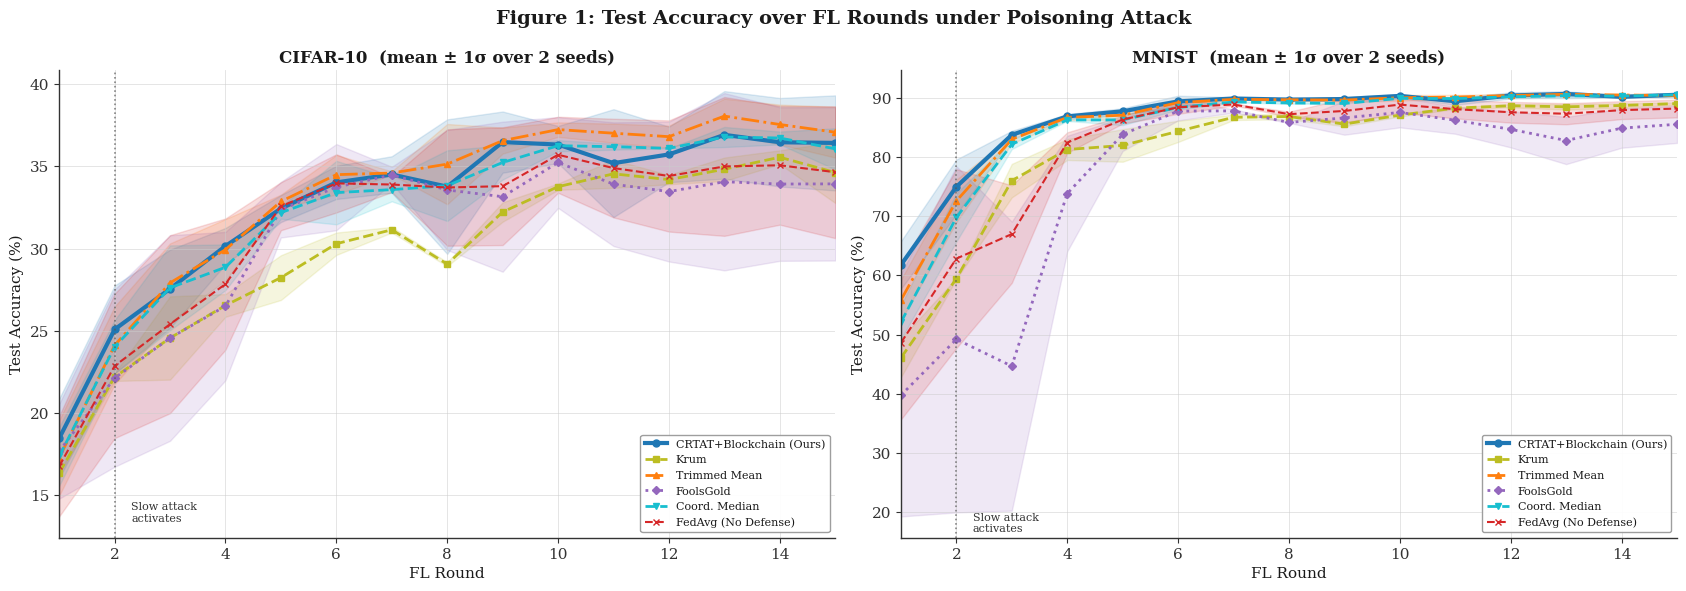

✅ Figure 1 saved.


In [ ]:
METHODS = ['CRTAT+Blockchain','Krum','TrimmedMean',
           'FoolsGold','CoordMedian','FedAvg_NoDefense']

# v5: helper to access multi-seed accuracy mean/std by dataset
_DATA_AGG = {'CIFAR-10': agg_cifar, 'MNIST': agg_mnist}
MLABELS = {'CRTAT+Blockchain':'CRTAT+Blockchain (Ours)',
           'Krum':'Krum','TrimmedMean':'Trimmed Mean',
           'FoolsGold':'FoolsGold','CoordMedian':'Coord. Median',
           'FedAvg_NoDefense':'FedAvg (No Defense)'}
MSTYLES = {
    'CRTAT+Blockchain' :{'color':'#1f77b4','lw':3.0,'ls':'-', 'marker':'o','ms':5},
    'Krum'             :{'color':'#bcbd22','lw':2.0,'ls':'--','marker':'s','ms':4},
    'TrimmedMean'      :{'color':'#ff7f0e','lw':2.0,'ls':'-.','marker':'^','ms':4},
    'FoolsGold'        :{'color':'#9467bd','lw':2.0,'ls':':', 'marker':'D','ms':4},
    'CoordMedian'      :{'color':'#17becf','lw':2.0,'ls':'--','marker':'v','ms':4},
    'FedAvg_NoDefense' :{'color':'#d62728','lw':1.5,'ls':'--','marker':'x','ms':5},
}
# Use the *actual* number of rounds run (may be < FL_ROUNDS due to early stop).
def _rounds_axis(hist):
    return list(range(1, len(hist['CRTAT+Blockchain']['acc']) + 1))

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
fig.suptitle('Figure 1: Test Accuracy over FL Rounds under Poisoning Attack',
             fontsize=14, fontweight='bold')

for ax, dname in zip(axes, ['CIFAR-10', 'MNIST']):
    agg = _DATA_AGG[dname]
    n_rounds = agg['min_rounds']
    rounds_axis = list(range(1, n_rounds+1))
    for m, st in MSTYLES.items():
        mean = agg['acc_mean'][m] * 100
        std  = agg['acc_std'][m]  * 100
        ax.plot(rounds_axis, mean, label=MLABELS[m], **st)
        ax.fill_between(rounds_axis, mean-std, mean+std,
                        color=st['color'], alpha=0.15)
    ax.axvline(SLOW_RAMP_START, color='#555555', lw=1.2, ls=':', alpha=0.7)
    ax.text(SLOW_RAMP_START+.3, ax.get_ylim()[0]+1,
            'Slow attack\nactivates', color='black', fontsize=8, alpha=0.8)
    ax.set_xlabel('FL Round'); ax.set_ylabel('Test Accuracy (%)')
    ax.set_title(f'{dname}  (mean ± 1σ over {len(SEEDS)} seeds)', fontsize=12)
    ax.legend(fontsize=8); ax.grid(True)
    ax.set_xlim([1, max(rounds_axis)])

plt.tight_layout()
plt.savefig('fig1_accuracy.png', dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show(); print('✅ Figure 1 saved.')

## 📊 Figure 2: CRTAT Anomaly Score Heatmap (Client × Round)

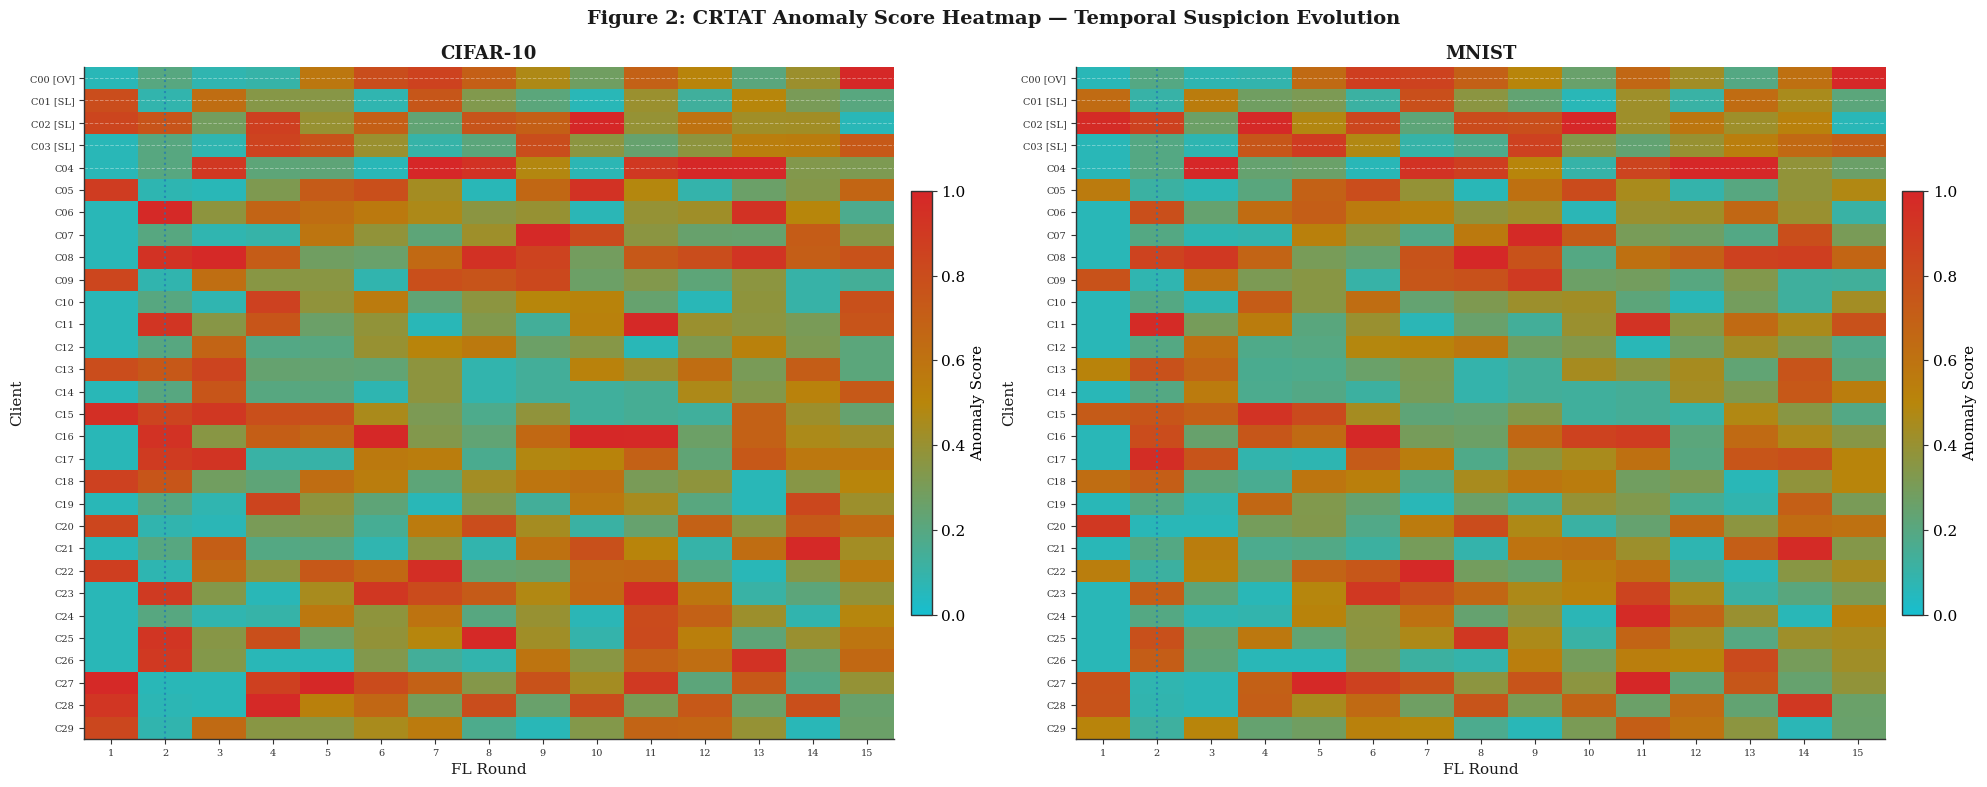

✅ Figure 2 saved.


In [ ]:
cmap_hot = LinearSegmentedColormap.from_list('trust',
    ['#17becf','#B8860B','#d62728'], N=256)

clabels = [f'C{i:02d}'+(' [OV]' if i in POISONED_CLIENTS else
            ' [SL]' if i in SLOW_CLIENTS else '')
           for i in range(NUM_CLIENTS)]

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.suptitle('Figure 2: CRTAT Anomaly Score Heatmap — Temporal Suspicion Evolution',
             fontsize=14, fontweight='bold')

for ax, (cs, dname) in zip(axes, [(cs_cifar,'CIFAR-10'),(cs_mnist,'MNIST')]):
    im = ax.imshow(cs.T, aspect='auto', cmap=cmap_hot, vmin=0, vmax=1)
    for cid in MALICIOUS:
        ax.axhline(cid, color='white', lw=0.7, ls='--', alpha=0.35)
    ax.axvline(SLOW_RAMP_START-1, color='#1f77b4', lw=1.5, ls=':', alpha=0.7)
    # Dynamic axis: cs.shape[0] is the actual number of rounds run (may be < FL_ROUNDS).
    n_rds = cs.shape[0]
    ax.set_xticks(range(n_rds)); ax.set_xticklabels(list(range(1, n_rds+1)), fontsize=7)
    ax.set_yticks(range(NUM_CLIENTS)); ax.set_yticklabels(clabels, fontsize=7)
    ax.set_xlabel('FL Round'); ax.set_ylabel('Client')
    ax.set_title(dname, fontsize=13)
    cb = plt.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
    cb.set_label('Anomaly Score', color='black')
    plt.setp(cb.ax.yaxis.get_ticklabels(), color='black')

plt.tight_layout()
plt.savefig('fig2_crtat_heatmap.png', dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show(); print('✅ Figure 2 saved.')


## 📊 Figure 3: CRTAT Temporal Trajectory — Slow vs Overt vs Honest

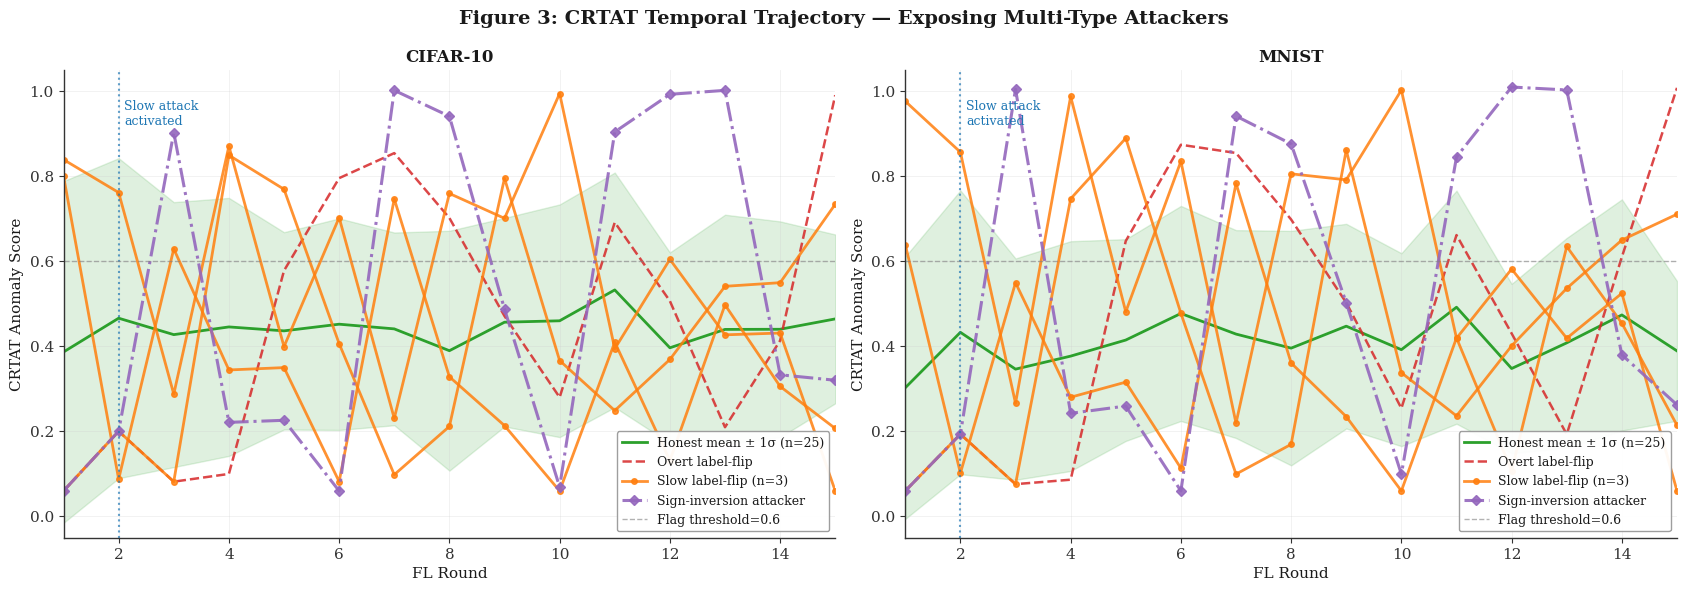

✅ Figure 3 saved (3 attack types).


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
fig.suptitle('Figure 3: CRTAT Temporal Trajectory — Exposing Multi-Type Attackers',
             fontsize=14, fontweight='bold')

for ax, (cs, dname) in zip(axes, [(cs_cifar,'CIFAR-10'),(cs_mnist,'MNIST')]):
    _ra = list(range(1, cs.shape[0]+1))
    hon_mean = cs[:, HONEST_CLIENTS].mean(1)
    hon_std  = cs[:, HONEST_CLIENTS].std(1)
    ax.fill_between(_ra, hon_mean-hon_std, hon_mean+hon_std,
                    alpha=0.15, color='#2ca02c')
    ax.plot(_ra, hon_mean, color='#2ca02c', lw=2,
            label=f'Honest mean ± 1σ (n={len(HONEST_CLIENTS)})')

    # Overt attacker(s) — red dashed
    for i, cid in enumerate(POISONED_CLIENTS):
        ax.plot(_ra, cs[:,cid], color='#d62728', lw=1.8, ls='--', alpha=0.85,
                label='Overt label-flip' if i==0 else '_')

    # Slow attackers — orange solid
    for i, cid in enumerate(SLOW_CLIENTS):
        ax.plot(_ra, cs[:,cid], color='#ff7f0e', lw=2.0, marker='o', ms=4, alpha=0.85,
                label=f'Slow label-flip (n={len(SLOW_CLIENTS)})' if i==0 else '_')

    # Sign-inversion attackers — purple dash-dot
    for i, cid in enumerate(INVERSE_CLIENTS):
        ax.plot(_ra, cs[:,cid], color='#9467bd', lw=2.2, ls='-.', marker='D', ms=5, alpha=0.9,
                label='Sign-inversion attacker' if i==0 else '_')

    ax.axvline(SLOW_RAMP_START, color='#1f77b4', ls=':', lw=1.5, alpha=0.7)
    ax.text(SLOW_RAMP_START+0.1, 0.98, 'Slow attack\nactivated', color='#1f77b4',
            fontsize=9, va='top')
    ax.axhline(FLAG_THRESHOLD, color='gray', ls='--', lw=1.0, alpha=0.6,
               label=f'Flag threshold={FLAG_THRESHOLD}')

    ax.set_xlabel('FL Round'); ax.set_ylabel('CRTAT Anomaly Score')
    ax.set_title(dname, fontsize=12)
    ax.set_xlim([1, max(_ra)]); ax.set_ylim([-0.05, 1.05])
    ax.legend(fontsize=9, loc='lower right')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig3_crtat_trajectory.png', dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()
print('✅ Figure 3 saved (3 attack types).')

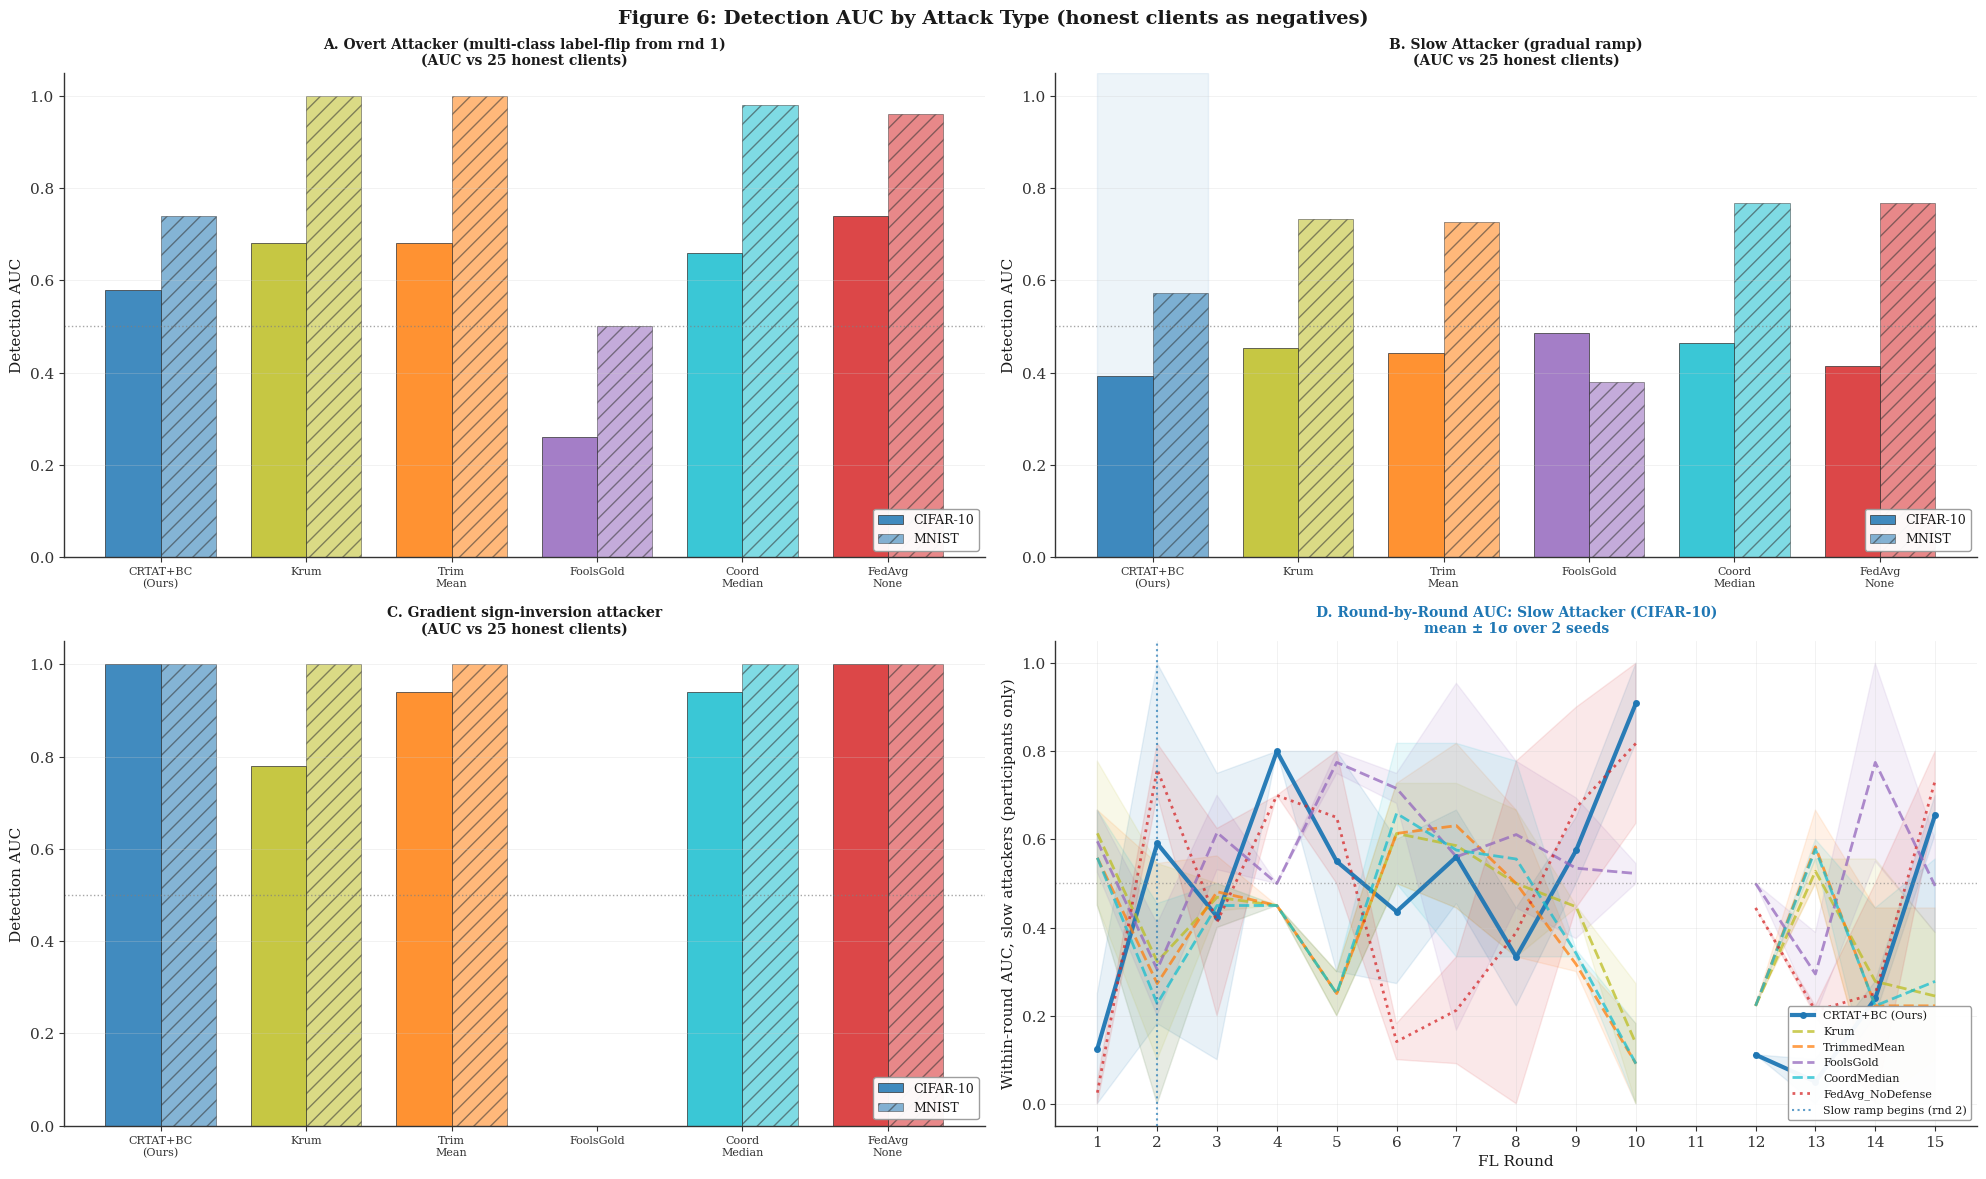

✅ Figure 6 saved (3 attack types · 4 panels).

Table IV — Detection AUC vs 25 honest clients | per-seed AUC → mean±std over seeds [42, 123] | final score = mean of last 3 observed rounds
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
Method                         Overt-C         Overt-M          Slow-C          Slow-M           Inv-C           Inv-M        Pooled-C        Pooled-M
──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  CRTAT+Blockchain         0.580±0.180     0.740±0.020     0.393±0.047     0.573±0.053     1.000±0.000     1.000±0.000     0.552±0.064     0.692±0.036
  Krum                     0.680±0.280     1.000±0.000     0.453±0.133     0.733±0.107     0.780±0.220     1.000±0.000     0.564±0.068     0.840±0.064
  TrimmedMean              0.680±0.320     1.000±0.000    

In [ ]:
from sklearn.metrics import roc_auc_score

def safe_auc(scores, gt):
    try: return roc_auc_score(gt, scores)
    except: return 0.5

# Table IV protocol: per-seed AUC of final_signal scores, honest clients as negatives, mean ± std over seeds
tbl_c = method_auc_table(results_cifar)
tbl_m = method_auc_table(results_mnist)
_pick = lambda tbl, j: [tbl[m]['mean'][j] for m in METHODS]
auc_overt_c, auc_slow_c, auc_inverse_c, auc_c = (_pick(tbl_c, j) for j in range(4))
auc_overt_m, auc_slow_m, auc_inverse_m, auc_m = (_pick(tbl_m, j) for j in range(4))
final_acc_c = [agg_cifar['acc_mean'][m][-1]*100 for m in METHODS]
final_acc_m = [agg_mnist['acc_mean'][m][-1]*100 for m in METHODS]
final_acc_c_std = [agg_cifar['acc_std'][m][-1]*100 for m in METHODS]
final_acc_m_std = [agg_mnist['acc_std'][m][-1]*100 for m in METHODS]

MDISP = ['CRTAT+BC\n(Ours)','Krum','Trim\nMean',
         'FoolsGold','Coord\nMedian','FedAvg\nNone']
MCOLS = ['#1f77b4','#bcbd22','#ff7f0e','#9467bd','#17becf','#d62728']
xp = np.arange(len(METHODS)); bw = 0.38

fig, axes = plt.subplots(2, 2, figsize=(20, 12))
fig.suptitle('Figure 6: Detection AUC by Attack Type (honest clients as negatives)',
             fontsize=14, fontweight='bold')

# ── Panel A: Overt Attacker ──
ax = axes[0,0]
ax.bar(xp - bw/2, auc_overt_c, bw, color=MCOLS, alpha=0.85,
       edgecolor='#333333', lw=0.6, label='CIFAR-10')
ax.bar(xp + bw/2, auc_overt_m, bw, color=MCOLS, alpha=0.55,
       edgecolor='#333333', lw=0.6, hatch='//', label='MNIST')
ax.axhline(0.5, color='gray', ls=':', lw=1, alpha=0.7)
ax.set_xticks(xp); ax.set_xticklabels(MDISP, fontsize=8)
ax.set_ylim([0, 1.05]); ax.set_ylabel('Detection AUC')
ax.set_title('A. Overt Attacker (multi-class label-flip from rnd 1)\n'
             '(AUC vs 25 honest clients)', fontsize=10)
ax.legend(fontsize=9, loc='lower right'); ax.grid(True, axis='y', alpha=0.3)

# ── Panel B: Slow Attacker (CRTAT advantage) ──
ax = axes[0,1]
ax.bar(xp - bw/2, auc_slow_c, bw, color=MCOLS, alpha=0.85,
       edgecolor='#333333', lw=0.6, label='CIFAR-10')
ax.bar(xp + bw/2, auc_slow_m, bw, color=MCOLS, alpha=0.55,
       edgecolor='#333333', lw=0.6, hatch='//', label='MNIST')
ax.axhline(0.5, color='gray', ls=':', lw=1, alpha=0.7)
ax.set_xticks(xp); ax.set_xticklabels(MDISP, fontsize=8)
ax.set_ylim([0, 1.05]); ax.set_ylabel('Detection AUC')
ax.set_title('B. Slow Attacker (gradual ramp)\n'
             '(AUC vs 25 honest clients)', fontsize=10)
ax.legend(fontsize=9, loc='lower right'); ax.grid(True, axis='y', alpha=0.3)
ax.axvspan(-bw, bw, alpha=0.08, color='#1f77b4')

# ── Panel C: Gradient Inverter (Krum's territory) ──
ax = axes[1,0]
ax.bar(xp - bw/2, auc_inverse_c, bw, color=MCOLS, alpha=0.85,
       edgecolor='#333333', lw=0.6, label='CIFAR-10')
ax.bar(xp + bw/2, auc_inverse_m, bw, color=MCOLS, alpha=0.55,
       edgecolor='#333333', lw=0.6, hatch='//', label='MNIST')
ax.axhline(0.5, color='gray', ls=':', lw=1, alpha=0.7)
ax.set_xticks(xp); ax.set_xticklabels(MDISP, fontsize=8)
ax.set_ylim([0, 1.05]); ax.set_ylabel('Detection AUC')
ax.set_title('C. Gradient sign-inversion attacker\n'
             '(AUC vs 25 honest clients)', fontsize=10)
ax.legend(fontsize=9, loc='lower right'); ax.grid(True, axis='y', alpha=0.3)

# ── Panel D: Round-by-round AUC for slow attacker (early-detection) ──
ax = axes[1,1]
LSTYLE = {'CRTAT+Blockchain':'-', 'Krum':'--', 'TrimmedMean':'--',
          'FoolsGold':'--', 'CoordMedian':'--', 'FedAvg_NoDefense':':'}
LWIDTH = {'CRTAT+Blockchain': 3.0}
n_rounds = agg_cifar['min_rounds']
rounds_axis = list(range(1, n_rounds+1))
for m, col in zip(METHODS, MCOLS):
    mean = agg_cifar['auc_slow_mean'][m]
    std  = agg_cifar['auc_slow_std'][m]
    ax.plot(rounds_axis, mean, color=col, ls=LSTYLE[m], lw=LWIDTH.get(m, 2.0),
            label=m if m != 'CRTAT+Blockchain' else 'CRTAT+BC (Ours)',
            alpha=0.95 if m == 'CRTAT+Blockchain' else 0.75,
            marker='o' if m == 'CRTAT+Blockchain' else None, markersize=4)
    ax.fill_between(rounds_axis, mean-std, mean+std, color=col, alpha=0.10)
ax.axvline(SLOW_RAMP_START, color='#1f77b4', ls=':', lw=1.5, alpha=0.7,
           label=f'Slow ramp begins (rnd {SLOW_RAMP_START})')
ax.axhline(0.5, color='gray', ls=':', lw=1, alpha=0.6)
ax.set_xlabel('FL Round'); ax.set_ylabel('Within-round AUC, slow attackers (participants only)')
ax.set_title('D. Round-by-Round AUC: Slow Attacker (CIFAR-10)\n'
             f'mean ± 1σ over {len(SEEDS)} seeds', fontsize=10, color='#1f77b4')
ax.set_xticks(rounds_axis); ax.set_ylim([-0.05, 1.05])
ax.legend(fontsize=8, loc='lower right'); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig6_detection_3types.png', dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()
print('✅ Figure 6 saved (3 attack types · 4 panels).')

# ── Table IV (numeric) ──
def _pm(tbl, m, j): return f"{tbl[m]['mean'][j]:.3f}±{tbl[m]['std'][j]:.3f}"
print()
print(f'Table IV — Detection AUC vs 25 honest clients | per-seed AUC → mean±std over seeds {SEEDS} | '
      f'final score = mean of last {FINAL_K} observed rounds')
print('═' * 150)
print(f'{"Method":<22}' + ''.join(f'{h:>16}' for h in ['Overt-C','Overt-M','Slow-C','Slow-M','Inv-C','Inv-M','Pooled-C','Pooled-M']))
print('─' * 150)
_cols = [(0,tbl_c),(0,tbl_m),(1,tbl_c),(1,tbl_m),(2,tbl_c),(2,tbl_m),(3,tbl_c),(3,tbl_m)]
for m in AUC_METHODS:
    print(f'  {m:<20}' + ''.join(f'{_pm(t, m, j):>16}' for (j, t) in _cols))
print('═' * 150)
print('  AUC < 0.5 means the attacker is ranked as LESS suspicious than honest clients on average — report it as such.')
print('  TemporalConsistency = simplified FLDetector-inspired baseline (not FLDetector).')
print_baseline_definitions()

## 📊 Figure 4: Per-Client Trust & CRTAT Scores

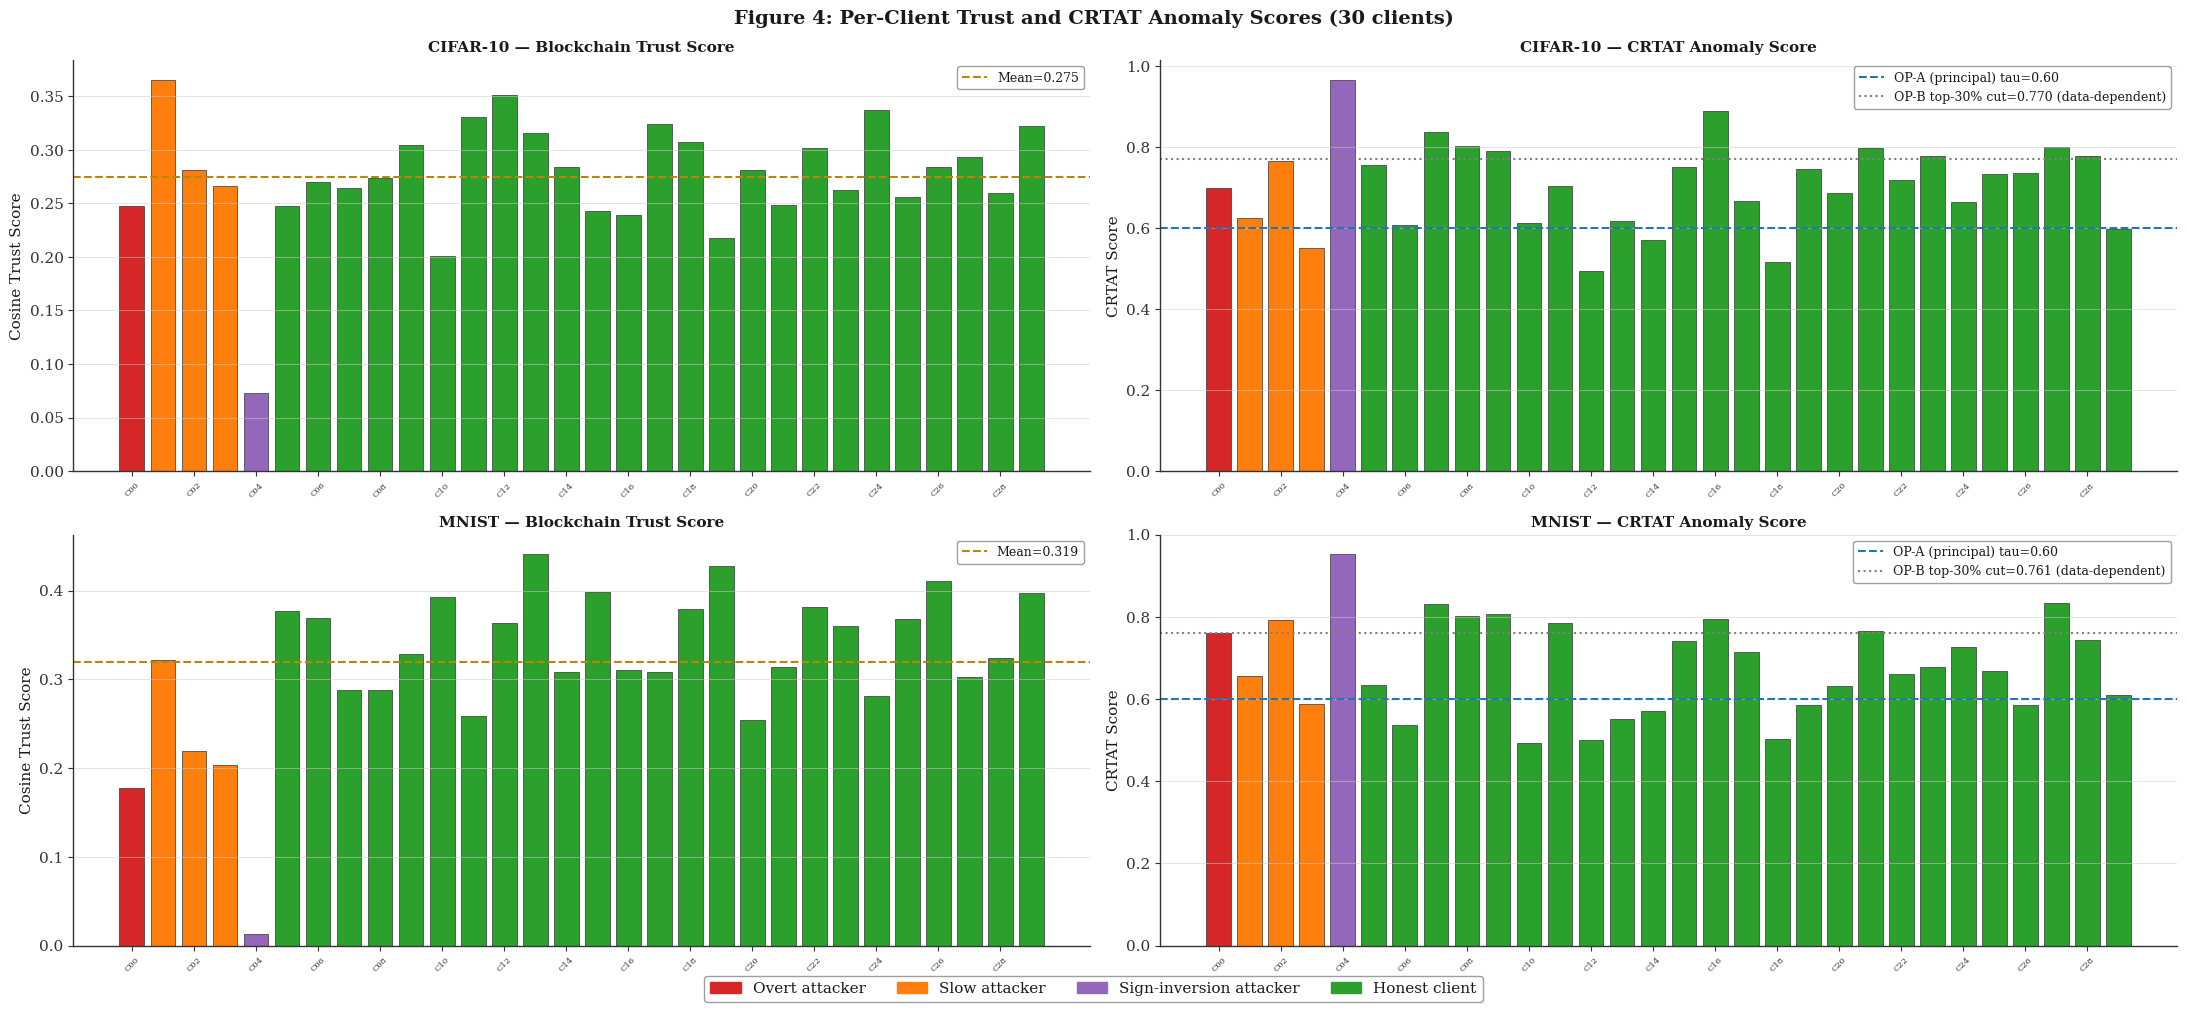

✅ Figure 4 saved (30 clients · 3 attack types).


In [ ]:
# v5: 3 attack-type colors instead of 2
def _attack_color(i):
    if i in POISONED_CLIENTS: return '#d62728'   # red — overt
    if i in SLOW_CLIENTS:     return '#ff7f0e'   # orange — slow
    if i in INVERSE_CLIENTS:  return '#9467bd'   # purple — inverter
    return '#2ca02c'                              # green — honest

bar_colors = [_attack_color(i) for i in range(NUM_CLIENTS)]
x = np.arange(NUM_CLIENTS)

fig, axes = plt.subplots(2, 2, figsize=(22, 10))
fig.suptitle('Figure 4: Per-Client Trust and CRTAT Anomaly Scores (30 clients)',
             fontsize=14, fontweight='bold')

# Legend handles for attack types
from matplotlib.patches import Patch
legend_handles = [
    Patch(color='#d62728', label='Overt attacker'),
    Patch(color='#ff7f0e', label='Slow attacker'),
    Patch(color='#9467bd', label='Sign-inversion attacker'),
    Patch(color='#2ca02c', label='Honest client'),
]

for row, (dname, mt, dc) in enumerate([('CIFAR-10', mt_cifar, dc_cifar),
                                        ('MNIST',   mt_mnist, dc_mnist)]):
    ax = axes[row, 0]
    ax.bar(x, mt, color=bar_colors, edgecolor='#333333', lw=0.5)
    ax.axhline(np.mean(mt), color='#B8860B', ls='--', lw=1.5,
               label=f'Mean={np.mean(mt):.3f}')
    ax.set_title(f'{dname} — Blockchain Trust Score', fontsize=11)
    ax.set_xticks(x[::2]); ax.set_xticklabels([f'C{i:02d}' for i in x[::2]],
                                              fontsize=6, rotation=45)
    ax.set_ylabel('Cosine Trust Score'); ax.legend(fontsize=9); ax.grid(True, axis='y')

    ax = axes[row, 1]
    ax.bar(x, dc, color=bar_colors, edgecolor='#333333', lw=0.5)
    ax.axhline(FLAG_THRESHOLD, color='#1f77b4', ls='--', lw=1.5,
               label=f'OP-A (principal) tau={FLAG_THRESHOLD:.2f}')
    thr_q = np.percentile(dc, 70)
    ax.axhline(thr_q, color='#7f7f7f', ls=':', lw=1.5,
               label=f'OP-B top-30% cut={thr_q:.3f} (data-dependent)')
    ax.set_title(f'{dname} — CRTAT Anomaly Score', fontsize=11)
    ax.set_xticks(x[::2]); ax.set_xticklabels([f'C{i:02d}' for i in x[::2]],
                                              fontsize=6, rotation=45)
    ax.set_ylabel('CRTAT Score'); ax.legend(fontsize=9); ax.grid(True, axis='y')

# Add an attack-type legend across the bottom
fig.legend(handles=legend_handles, loc='lower center', ncol=4,
           fontsize=11, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout()
plt.savefig('fig4_per_client.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('✅ Figure 4 saved (30 clients · 3 attack types).')

## 📊 Figure 5: ROC Curves — Poison Detection

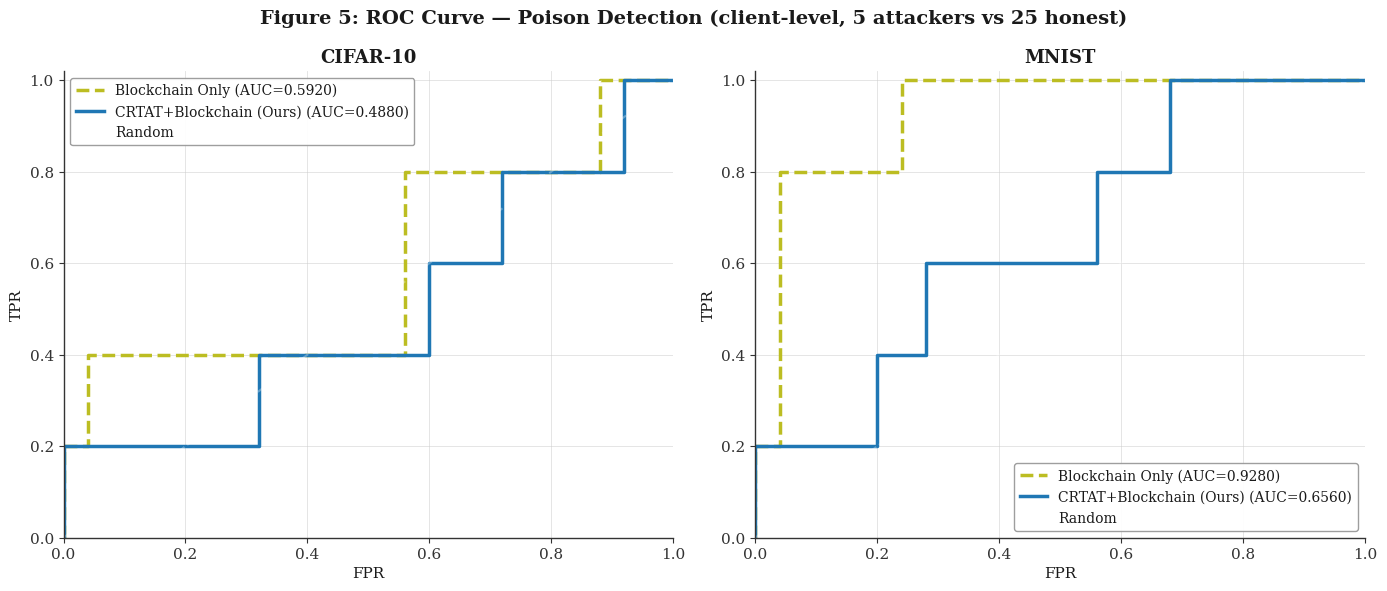

✅ Figure 5 saved.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Figure 5: ROC Curve — Poison Detection (client-level, 5 attackers vs 25 honest)',
             fontsize=14, fontweight='bold')

for ax, (db, dc, det_sig, dname) in zip(axes, [
        (db_cifar, dc_cifar, det_cifar, 'CIFAR-10'),
        (db_mnist, dc_mnist, det_mnist, 'MNIST')]):
    for label, sc, color, ls in [
        ('Blockchain Only',         db, '#bcbd22', '--'),
        ('CRTAT+Blockchain (Ours)', dc, '#1f77b4', '-')]:
        fpr, tpr, _ = roc_curve(gt_labels, sc)
        ax.plot(fpr, tpr, color=color, lw=2.5, ls=ls,
                label=f'{label} (AUC={auc(fpr,tpr):.4f})')
    ax.plot([0,1],[0,1], 'w--', alpha=0.3, label='Random')
    ax.fill_between([0,1],[0,1], alpha=0.03, color='white')
    ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
    ax.set_title(dname, fontsize=13); ax.legend(fontsize=10)
    ax.grid(True); ax.set_xlim([0,1]); ax.set_ylim([0,1.02])

plt.tight_layout()
plt.savefig('fig5_roc.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show(); print('✅ Figure 5 saved.')


## Figure 6: Per-attack-type detection AUC

Three panels (overt, slow, sign-inversion) show the final-score AUC of every method with the 25 honest clients as negatives (per seed, mean over seeds); panel D shows the within-round AUC for the slow attackers over rounds (participants only). Which method is best on which attack type is read off these panels — it is not assumed in advance.


## 📊 Figure 7: Confusion Matrix — Client Classification

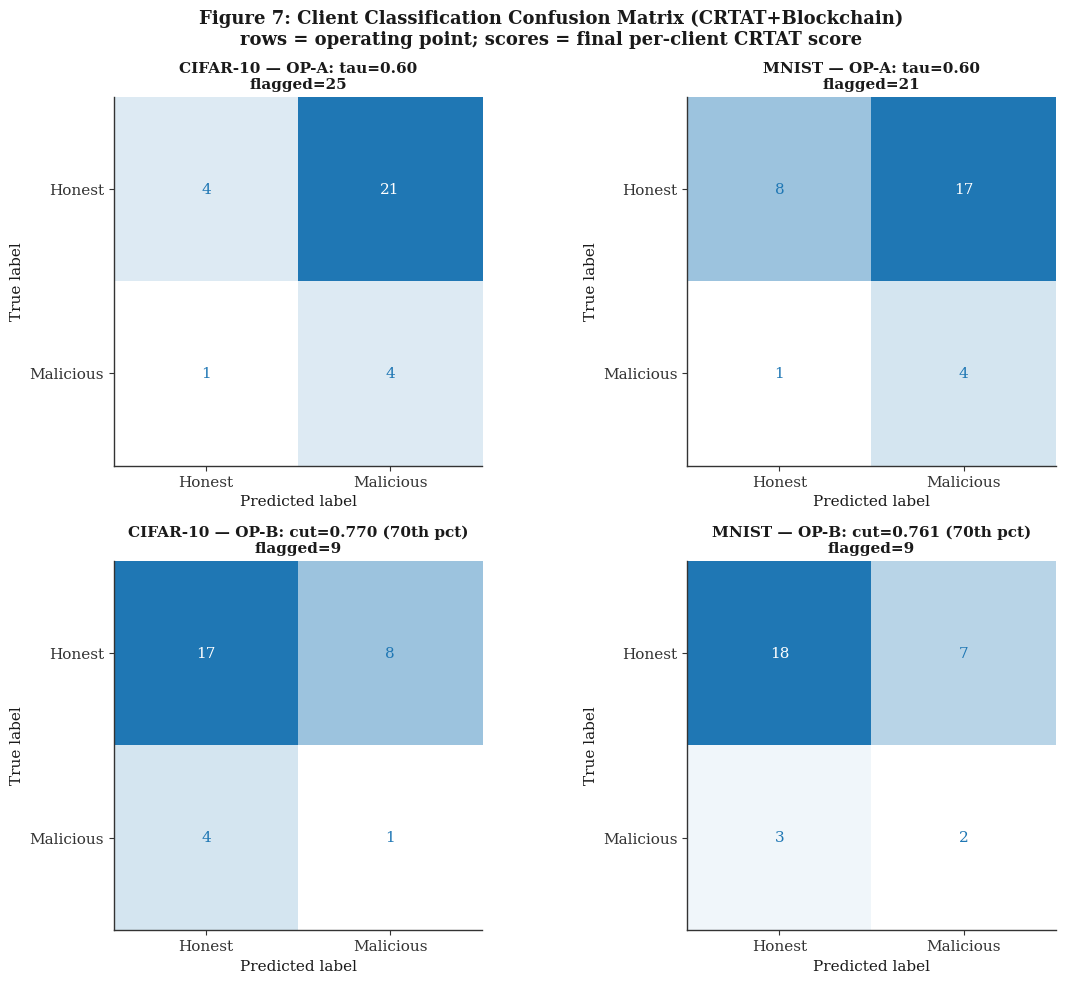

✅ Figure 7 saved.
  OP-A CIFAR-10 : TP=4 FP=21 TN=4 FN=1 | flagged=25 | P=0.160 R=0.800 F1=0.267
  OP-A MNIST    : TP=4 FP=17 TN=8 FN=1 | flagged=21 | P=0.190 R=0.800 F1=0.308
  OP-B CIFAR-10 : TP=1 FP=8 TN=17 FN=4 | flagged=9 | P=0.111 R=0.200 F1=0.143
  OP-B MNIST    : TP=2 FP=7 TN=18 FN=3 | flagged=9 | P=0.222 R=0.400 F1=0.286


In [ ]:
# Figure 7: confusion matrices at BOTH labelled operating points (OP-A principal, OP-B secondary)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Figure 7: Client Classification Confusion Matrix (CRTAT+Blockchain)\n'
             'rows = operating point; scores = final per-client CRTAT score',
             fontsize=13, fontweight='bold')
for row, op in enumerate(['OP-A', 'OP-B']):
    for col, (dc_, dname) in enumerate([(dc_cifar, 'CIFAR-10'), (dc_mnist, 'MNIST')]):
        pred = OPERATING_POINTS[op]['fn'](dc_)
        cm = confusion_matrix(gt_labels, pred, labels=[0, 1])
        ax = axes[row, col]
        ConfusionMatrixDisplay(cm, display_labels=['Honest', 'Malicious']).plot(
            ax=ax, colorbar=False, cmap=LinearSegmentedColormap.from_list('cm', ['white', '#1f77b4']))
        thr_txt = (f'tau={FLAG_THRESHOLD:.2f}' if op == 'OP-A'
                   else f'cut={np.percentile(dc_, 70):.3f} (70th pct)')
        ax.set_title(f'{dname} — {op}: {thr_txt}\nflagged={int(pred.sum())}', fontsize=11)
plt.tight_layout()
plt.savefig('fig7_confusion.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show(); print('✅ Figure 7 saved.')
for op in ['OP-A', 'OP-B']:
    for dc_, dname in [(dc_cifar, 'CIFAR-10'), (dc_mnist, 'MNIST')]:
        print(f'  {op} {dname:<9}: {fmt_counts(confusion_counts(gt_labels, OPERATING_POINTS[op]["fn"](dc_)))}')


## 📊 Figure 8: PCA Scatter of Client Updates

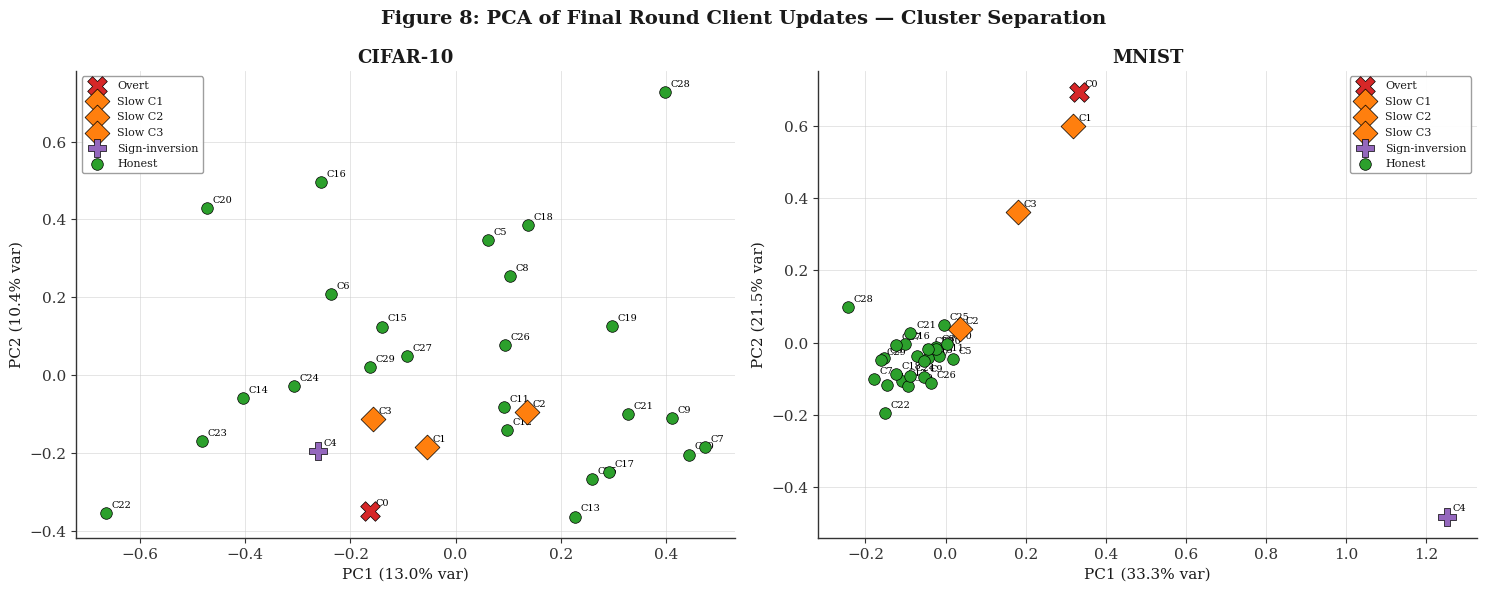

✅ Figure 8 saved.


In [ ]:
def get_final_updates(clients_list, client_data, gp):
    """Final-round updates of ALL clients using the same attack code as the simulation
    (overt flip, slow ramp at the last round, sign-inversion with INVERSE_SCALE)."""
    rng = np.random.default_rng(SEED)
    updates = []
    for cid in range(NUM_CLIENTS):
        X_c, y_c = client_data[cid]
        updates.append(_client_update(clients_list[cid], gp, X_c, y_c, cid, FL_ROUNDS, FL_ROUNDS, LR_MIN, rng))
    return np.stack(updates)

pca2 = PCA(n_components=2, random_state=SEED)
upd_c = get_final_updates(clients_cifar, client_cifar, gp_cifar['CRTAT+Blockchain'])
upd_m = get_final_updates(clients_mnist, client_mnist, gp_mnist['CRTAT+Blockchain'])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Figure 8: PCA of Final Round Client Updates — Cluster Separation',
             fontsize=14, fontweight='bold')

for ax, (upd, dname) in zip(axes,[(upd_c,'CIFAR-10'),(upd_m,'MNIST')]):
    emb = pca2.fit_transform(upd)
    for i in range(NUM_CLIENTS):
        if i in POISONED_CLIENTS:
            c,mk,s,lbl='#d62728','X',200,('Overt' if i==POISONED_CLIENTS[0] else '_')
        elif i in SLOW_CLIENTS:
            c,mk,s,lbl='#ff7f0e','D',160,(f'Slow C{i}')
        elif i in INVERSE_CLIENTS:
            c,mk,s,lbl='#9467bd','P',180,'Sign-inversion'
        else:
            c,mk,s,lbl='#2ca02c','o',70,('Honest' if i==HONEST_CLIENTS[0] else '_')
        ax.scatter(emb[i,0],emb[i,1],c=c,marker=mk,s=s,
                   edgecolors='black',lw=0.5,zorder=5,label=lbl)
        ax.annotate(f'C{i}',(emb[i,0],emb[i,1]),
                    xytext=(4,4),textcoords='offset points',fontsize=7,color='black')
    ax.set_xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}% var)')
    ax.set_ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}% var)')
    ax.set_title(dname,fontsize=13); ax.legend(fontsize=8); ax.grid(True)

plt.tight_layout()
plt.savefig('fig8_pca.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show(); print('✅ Figure 8 saved.')


## 📊 Figure 9: Precision–Recall Curve

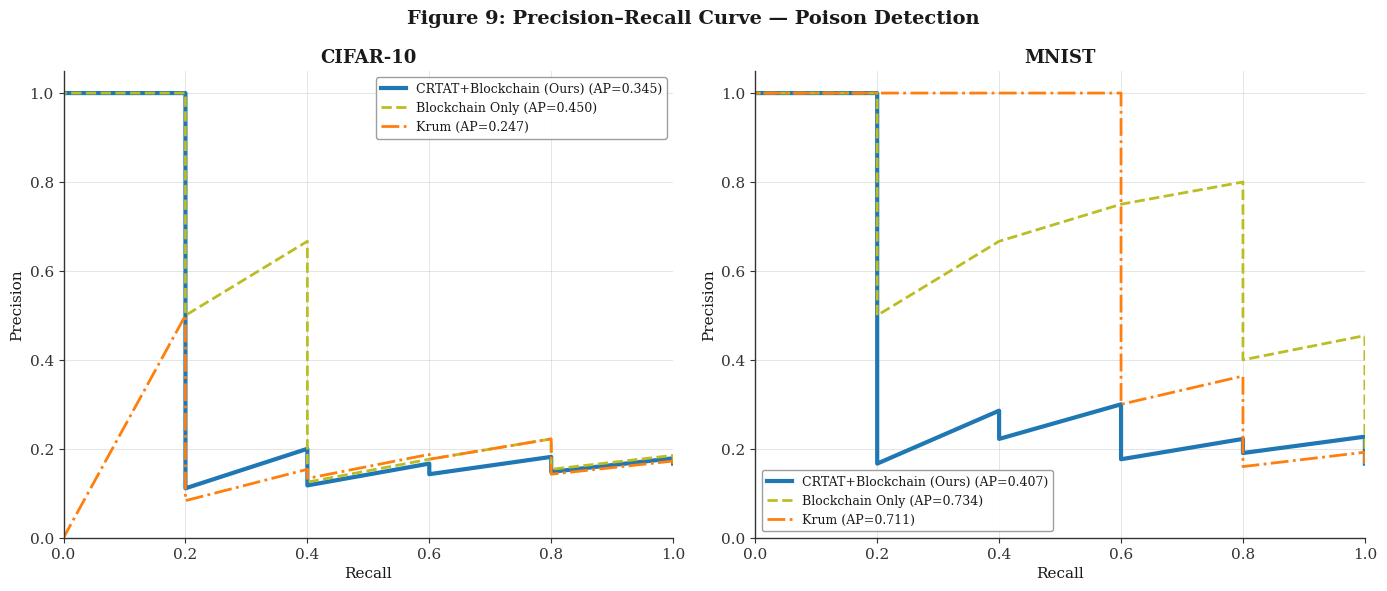

✅ Figure 9 saved.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Figure 9: Precision–Recall Curve — Poison Detection',
             fontsize=14, fontweight='bold')

PR_CFG = [
    ('CRTAT+Blockchain (Ours)',dc_cifar,dc_mnist,'#1f77b4','-',3.0),
    ('Blockchain Only',        db_cifar,db_mnist,'#bcbd22','--',2.0),
    ('Krum',          det_cifar['Krum'],det_mnist['Krum'],'#ff7f0e','-.', 2.0),
]
for ax, dname in zip(axes,['CIFAR-10','MNIST']):
    for label,sc_c,sc_m,color,ls,lw in PR_CFG:
        sc = sc_c if dname=='CIFAR-10' else sc_m
        try:
            p,r,_ = precision_recall_curve(gt_labels,sc)
            ap    = average_precision_score(gt_labels,sc)
            ax.plot(r,p,color=color,lw=lw,ls=ls,label=f'{label} (AP={ap:.3f})')
        except: pass
    ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
    ax.set_title(dname,fontsize=13); ax.legend(fontsize=9)
    ax.grid(True); ax.set_xlim([0,1]); ax.set_ylim([0,1.05])

plt.tight_layout()
plt.savefig('fig9_pr_curve.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show(); print('✅ Figure 9 saved.')

## 📊 Figure 10: Blockchain Trust Score Evolution per Client

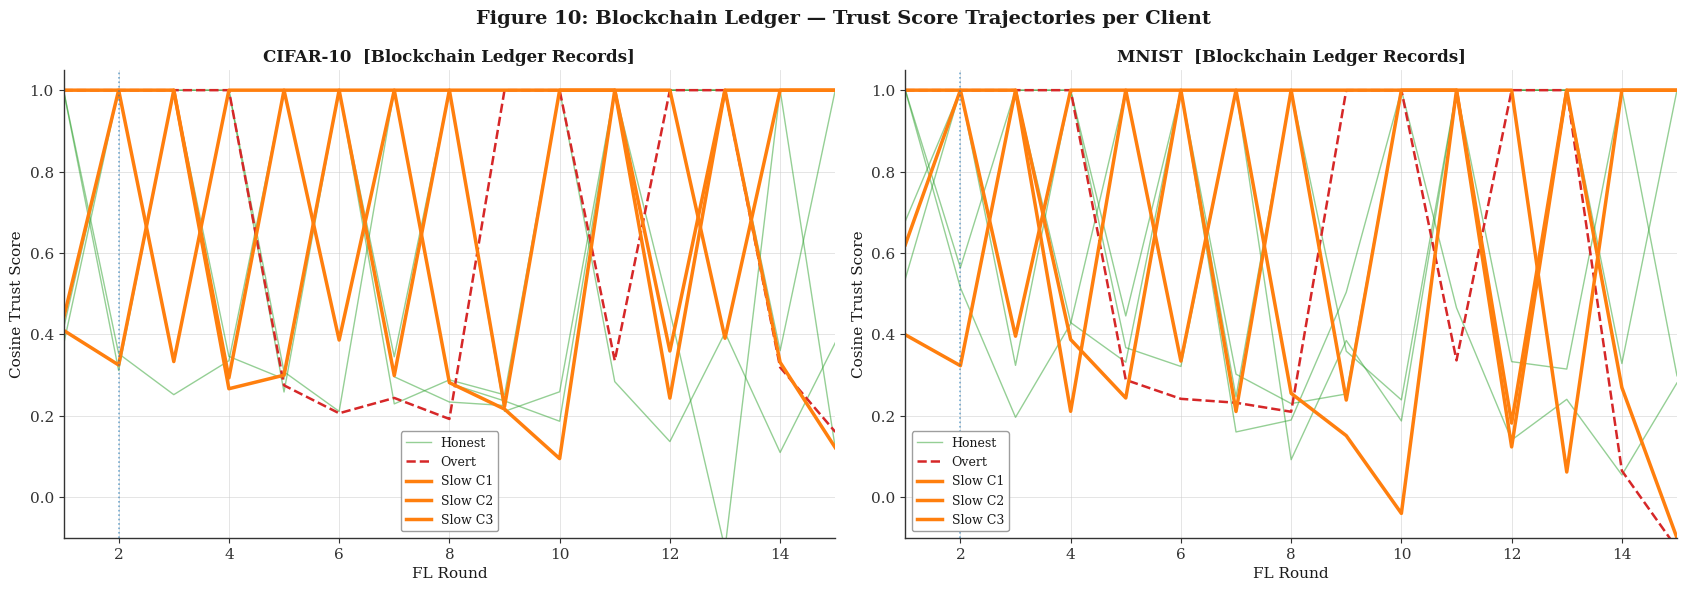

✅ Figure 10 saved.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
fig.suptitle('Figure 10: Blockchain Ledger — Trust Score Trajectories per Client',
             fontsize=14, fontweight='bold')

for ax, (bc, ts, dname) in zip(axes,
        [(bc_cifar,ts_cifar,'CIFAR-10'),(bc_mnist,ts_mnist,'MNIST')]):
    for cid in HONEST_CLIENTS[:5]:
        ax.plot(list(range(1, ts.shape[0]+1)), ts[:,cid], color='#2ca02c', lw=1, alpha=0.5,
                label='Honest' if cid==HONEST_CLIENTS[0] else '_')
    for cid in POISONED_CLIENTS:
        ax.plot(list(range(1, ts.shape[0]+1)), ts[:,cid], color='#d62728', lw=1.8, ls='--',
                label='Overt' if cid==POISONED_CLIENTS[0] else '_')
    for cid in SLOW_CLIENTS:
        ax.plot(list(range(1, ts.shape[0]+1)), ts[:,cid], color='#ff7f0e', lw=2.5,
                label=f'Slow C{cid}')
    ax.axvline(SLOW_RAMP_START, color='#1f77b4', lw=1.2, ls=':', alpha=0.6)
    ax.set_xlabel('FL Round'); ax.set_ylabel('Cosine Trust Score')
    ax.set_title(f'{dname}  [Blockchain Ledger Records]', fontsize=12)
    ax.legend(fontsize=9); ax.grid(True)
    ax.set_xlim([1,ts.shape[0]]); ax.set_ylim([-0.1,1.05])

plt.tight_layout()
plt.savefig('fig10_blockchain_trust.png', dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show(); print('✅ Figure 10 saved.')


## 📊 Figure 11: Summary Dashboard

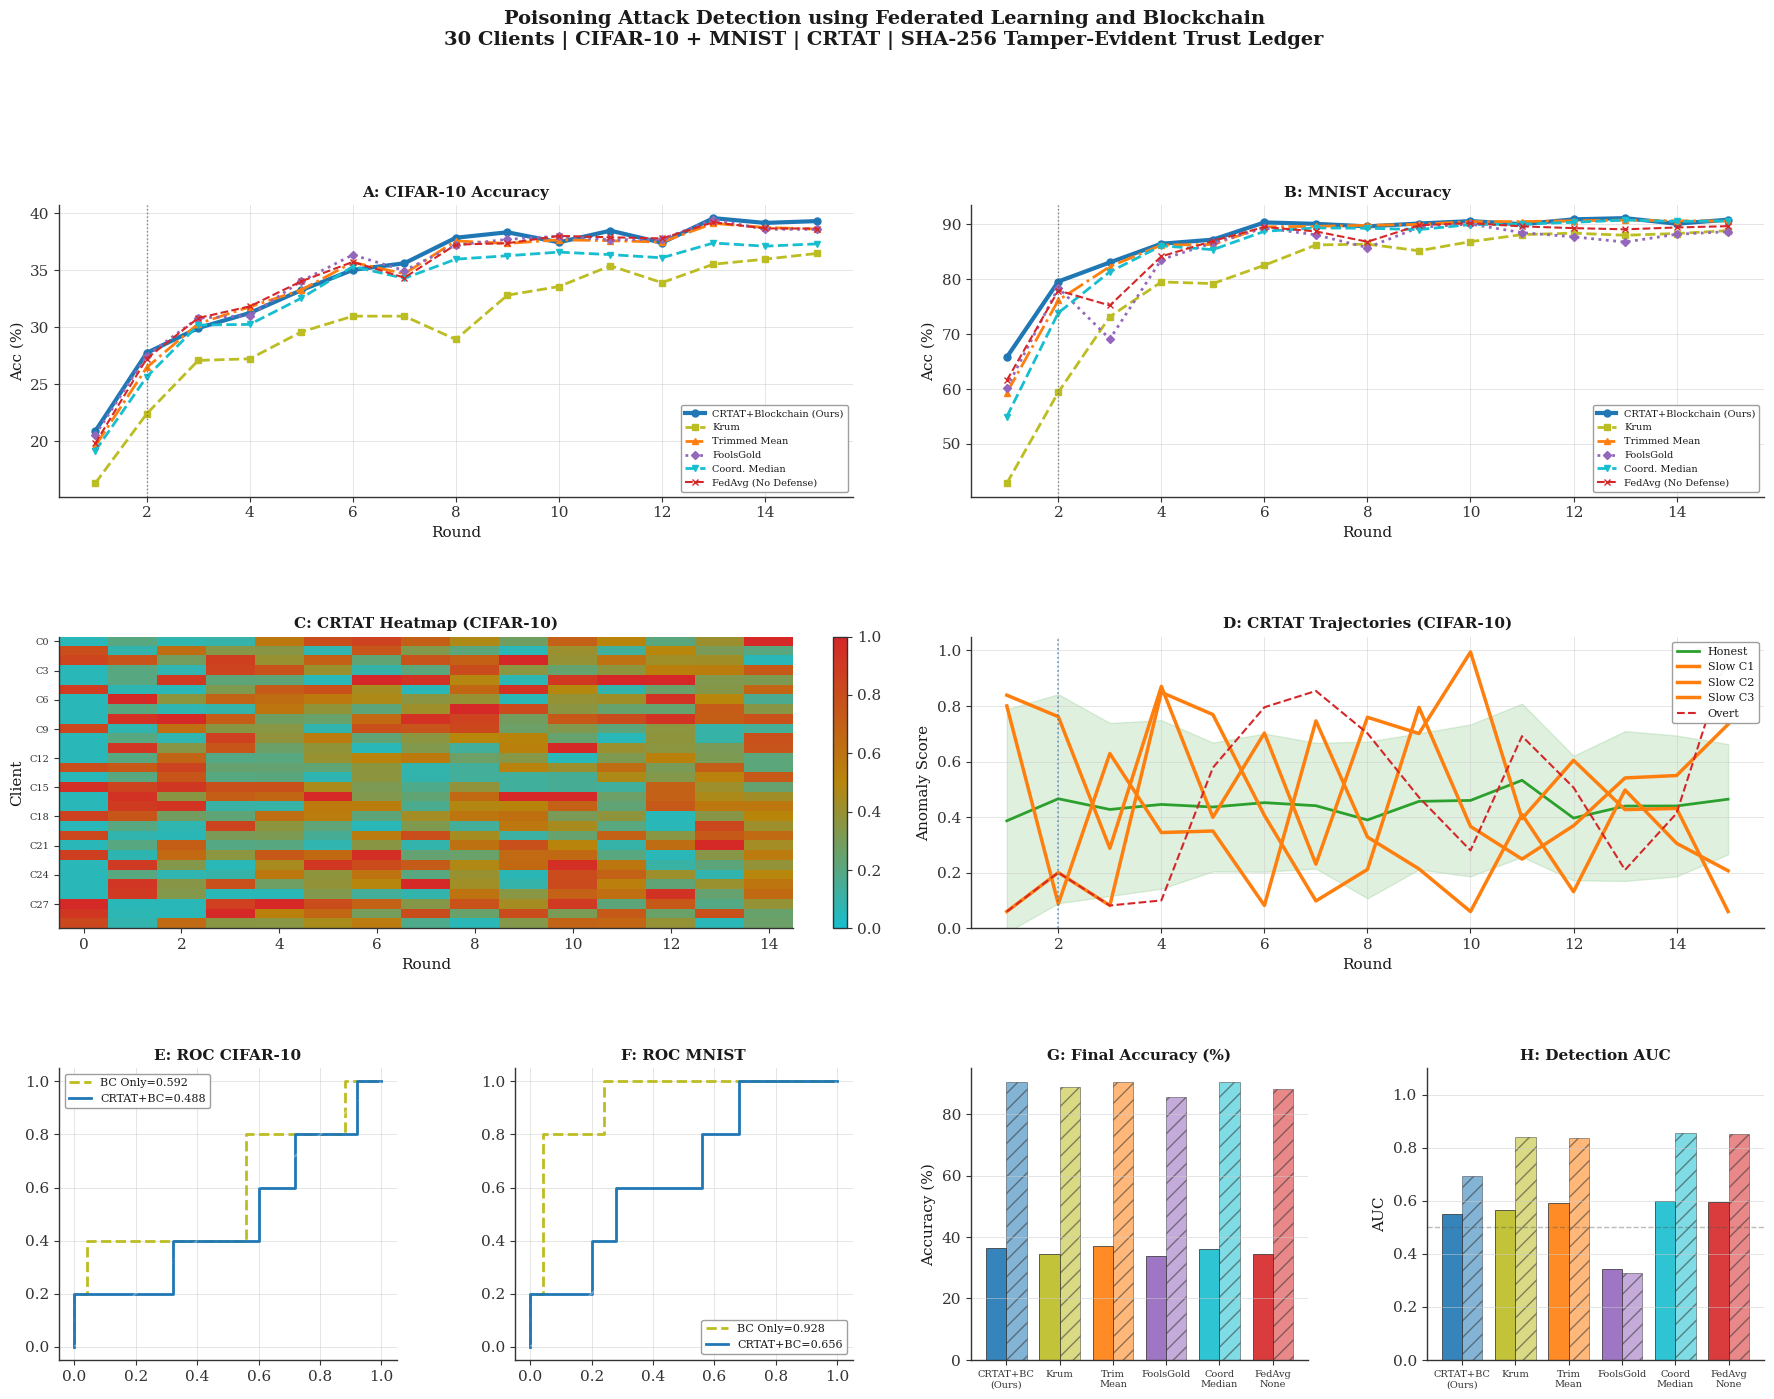

✅ Figure 11 — Summary Dashboard saved.


In [ ]:
fig = plt.figure(figsize=(22, 15))
fig.suptitle(
    'Poisoning Attack Detection using Federated Learning and Blockchain\n'
    '30 Clients | CIFAR-10 + MNIST | CRTAT | '
    'SHA-256 Tamper-Evident Trust Ledger',
    fontsize=14, fontweight='bold', y=1.01)

gs = gridspec.GridSpec(3, 4, figure=fig, hspace=0.48, wspace=0.35)

# A: Accuracy CIFAR
ax_a = fig.add_subplot(gs[0,:2])
_ra_c = list(range(1, len(hist_cifar['CRTAT+Blockchain']['acc'])+1))
for m,st in MSTYLES.items():
    ax_a.plot(_ra_c,[a*100 for a in hist_cifar[m]['acc']],
              label=MLABELS[m],**st)
ax_a.axvline(SLOW_RAMP_START,color='#555555',lw=1,ls=':',alpha=0.7)
ax_a.set_title('A: CIFAR-10 Accuracy',fontsize=11)
ax_a.set_xlabel('Round'); ax_a.set_ylabel('Acc (%)')
ax_a.legend(fontsize=7); ax_a.grid(True)

# B: Accuracy MNIST
ax_b = fig.add_subplot(gs[0,2:])
_ra_m = list(range(1, len(hist_mnist['CRTAT+Blockchain']['acc'])+1))
for m,st in MSTYLES.items():
    ax_b.plot(_ra_m,[a*100 for a in hist_mnist[m]['acc']],
              label=MLABELS[m],**st)
ax_b.axvline(SLOW_RAMP_START,color='#555555',lw=1,ls=':',alpha=0.7)
ax_b.set_title('B: MNIST Accuracy',fontsize=11)
ax_b.set_xlabel('Round'); ax_b.set_ylabel('Acc (%)')
ax_b.legend(fontsize=7); ax_b.grid(True)

# C: CRTAT heatmap CIFAR
ax_c = fig.add_subplot(gs[1,:2])
im = ax_c.imshow(cs_cifar.T,aspect='auto',cmap=cmap_hot,vmin=0,vmax=1)
ax_c.set_title('C: CRTAT Heatmap (CIFAR-10)',fontsize=11)
ax_c.set_xlabel('Round'); ax_c.set_ylabel('Client')
ax_c.set_yticks(range(0,NUM_CLIENTS,3))
ax_c.set_yticklabels([f'C{i}' for i in range(0,NUM_CLIENTS,3)],fontsize=7)
plt.colorbar(im,ax=ax_c,fraction=0.025)

# D: CRTAT trajectory
ax_d = fig.add_subplot(gs[1,2:])
hon_m = cs_cifar[:,HONEST_CLIENTS].mean(1)
_ra_d = list(range(1, cs_cifar.shape[0]+1))
ax_d.fill_between(_ra_d,hon_m-cs_cifar[:,HONEST_CLIENTS].std(1),
                  hon_m+cs_cifar[:,HONEST_CLIENTS].std(1),alpha=0.15,color='#2ca02c')
ax_d.plot(_ra_d,hon_m,color='#2ca02c',lw=2,label='Honest')
for cid in SLOW_CLIENTS:
    ax_d.plot(_ra_d,cs_cifar[:,cid],color='#ff7f0e',lw=2.5,label=f'Slow C{cid}')
for cid in POISONED_CLIENTS[:2]:
    ax_d.plot(_ra_d,cs_cifar[:,cid],color='#d62728',lw=1.5,ls='--',label='Overt')
ax_d.axvline(SLOW_RAMP_START,color='#1f77b4',lw=1.2,ls=':',alpha=0.7)
ax_d.set_title('D: CRTAT Trajectories (CIFAR-10)',fontsize=11)
ax_d.set_xlabel('Round'); ax_d.set_ylabel('Anomaly Score')
ax_d.legend(fontsize=8); ax_d.grid(True); ax_d.set_ylim([0,1.05])

# E: ROC CIFAR
ax_e = fig.add_subplot(gs[2,0])
for lbl,sc,col,ls in [('BC Only',db_cifar,'#bcbd22','--'),
                       ('CRTAT+BC',dc_cifar,'#1f77b4','-')]:
    fpr,tpr,_ = roc_curve(gt_labels,sc)
    ax_e.plot(fpr,tpr,color=col,lw=2,ls=ls,label=f'{lbl}={auc(fpr,tpr):.3f}')
ax_e.plot([0,1],[0,1],'w--',alpha=0.3)
ax_e.set_title('E: ROC CIFAR-10',fontsize=11)
ax_e.legend(fontsize=8); ax_e.grid(True)

# F: ROC MNIST
ax_f = fig.add_subplot(gs[2,1])
for lbl,sc,col,ls in [('BC Only',db_mnist,'#bcbd22','--'),
                       ('CRTAT+BC',dc_mnist,'#1f77b4','-')]:
    fpr,tpr,_ = roc_curve(gt_labels,sc)
    ax_f.plot(fpr,tpr,color=col,lw=2,ls=ls,label=f'{lbl}={auc(fpr,tpr):.3f}')
ax_f.plot([0,1],[0,1],'w--',alpha=0.3)
ax_f.set_title('F: ROC MNIST',fontsize=11)
ax_f.legend(fontsize=8); ax_f.grid(True)

# G: Final accuracy bar
ax_g = fig.add_subplot(gs[2,2])
ax_g.bar(xp-bw/2,final_acc_c,bw,color=MCOLS,alpha=0.9,edgecolor='#333333',lw=0.6)
ax_g.bar(xp+bw/2,final_acc_m,bw,color=MCOLS,alpha=0.55,edgecolor='#333333',lw=0.6,hatch='//')
ax_g.set_title('G: Final Accuracy (%)',fontsize=11)
ax_g.set_xticks(xp); ax_g.set_xticklabels(MDISP,fontsize=7)
ax_g.set_ylabel('Accuracy (%)'); ax_g.grid(True,axis='y')

# H: AUC bar
ax_h = fig.add_subplot(gs[2,3])
ax_h.bar(xp-bw/2,auc_c,bw,color=MCOLS,alpha=0.9,edgecolor='#333333',lw=0.6)
ax_h.bar(xp+bw/2,auc_m,bw,color=MCOLS,alpha=0.55,edgecolor='#333333',lw=0.6,hatch='//')
ax_h.axhline(0.5,color='#555555',ls='--',lw=1,alpha=0.4)
ax_h.set_title('H: Detection AUC',fontsize=11)
ax_h.set_xticks(xp); ax_h.set_xticklabels(MDISP,fontsize=7)
ax_h.set_ylabel('AUC'); ax_h.set_ylim([0,1.1]); ax_h.grid(True,axis='y')

plt.savefig('fig11_dashboard.png', dpi=180, bbox_inches='tight',
            facecolor='white')
plt.show(); print('✅ Figure 11 — Summary Dashboard saved.')


## 📋 Step 13: Results Table (protocol stated per number)


In [ ]:
# ─── Step 13: Results table — every number states its protocol ───────────────
# Accuracy: mean over SEEDS after the last executed round (early stopping is OFF by default).
# AUC: per-seed AUC of final_signal scores, honest clients as negatives, mean over SEEDS.
# Operating points are reported separately (OP-A principal, OP-B secondary) WITH confusion counts.
tbl_c48 = method_auc_table(results_cifar)
tbl_m48 = method_auc_table(results_mnist)
W = 96
print('╔' + '═'*W + '╗')
print('║' + f'{"POISONING ATTACK DETECTION — RESULTS":^{W}}' + '║')
print('║' + f'{f"FL+Blockchain+CRTAT | {NUM_CLIENTS} clients | CIFAR-10 + MNIST | {FL_ROUNDS} rounds | seeds {SEEDS}":^{W}}' + '║')
print('╠' + '═'*W + '╣')
hdr = f'{"Method":<22}{"CIFAR Acc":>11}{"MNIST Acc":>11}{"CIFAR pooled AUC":>18}{"MNIST pooled AUC":>18}  Notes'
print('║' + f'{hdr:<{W}}' + '║')
print('╠' + '═'*W + '╣')
notes = {'CRTAT+Blockchain': '★ Proposed', 'Krum': 'Baseline', 'TrimmedMean': 'Baseline',
         'FoolsGold': 'Baseline', 'CoordMedian': 'Baseline', 'FedAvg_NoDefense': 'No defense (proxy score)'}
for m in METHODS:
    ca = agg_cifar['acc_mean'][m][-1]*100; ma = agg_mnist['acc_mean'][m][-1]*100
    cu, cs_ = tbl_c48[m]['mean'][3], tbl_c48[m]['std'][3]
    mu, ms_ = tbl_m48[m]['mean'][3], tbl_m48[m]['std'][3]
    row = f'{m:<22}{ca:>11.2f}{ma:>11.2f}{f"{cu:.3f}±{cs_:.3f}":>18}{f"{mu:.3f}±{ms_:.3f}":>18}  {notes[m]}'
    print('║' + f'{row:<{W}}' + '║')
print('╠' + '═'*W + '╣')
for op in ['OP-A', 'OP-B']:
    t = f'  CRTAT+Blockchain detection at {OPERATING_POINTS[op]["name"]}'
    print('║' + f'{t:<{W}}' + '║')
    for dname, dc_ in [('CIFAR-10', dc_cifar), ('MNIST', dc_mnist)]:
        line = f'    {dname:<9}: {fmt_counts(confusion_counts(gt_labels, OPERATING_POINTS[op]["fn"](dc_)))}'
        print('║' + f'{line:<{W}}' + '║')
print('╠' + '═'*W + '╣')
t = '  Slow-attacker detection (OP-A principal | OP-B in brackets)'
print('║' + f'{t:<{W}}' + '║')
thr_c = np.percentile(dc_cifar, 70); thr_m = np.percentile(dc_mnist, 70)
for cid in SLOW_CLIENTS:
    fa_c = '✓' if dc_cifar[cid] >= FLAG_THRESHOLD else '✗'; fb_c = '✓' if dc_cifar[cid] >= thr_c else '✗'
    fa_m = '✓' if dc_mnist[cid] >= FLAG_THRESHOLD else '✗'; fb_m = '✓' if dc_mnist[cid] >= thr_m else '✗'
    line = (f'    C{cid:02d}: CIFAR score={dc_cifar[cid]:.4f} {fa_c} [{fb_c}]  '
            f'ledger flags={bc_cifar.cumulative_flags(cid)} | '
            f'MNIST score={dc_mnist[cid]:.4f} {fa_m} [{fb_m}]  ledger flags={bc_mnist.cumulative_flags(cid)}')
    print('║' + f'{line:<{W}}' + '║')
print('╠' + '═'*W + '╣')
line = f'  Ledger integrity (internal consistency only): CIFAR-10={bc_cifar.is_valid()[1]}  MNIST={bc_mnist.is_valid()[1]}'
print('║' + f'{line:<{W}}' + '║')
print('╚' + '═'*W + '╝')


╔════════════════════════════════════════════════════════════════════════════════════════════════╗
║                              POISONING ATTACK DETECTION — RESULTS                              ║
║       FL+Blockchain+CRTAT | 30 clients | CIFAR-10 + MNIST | 15 rounds | seeds [42, 123]        ║
╠════════════════════════════════════════════════════════════════════════════════════════════════╣
║Method                  CIFAR Acc  MNIST Acc  CIFAR pooled AUC  MNIST pooled AUC  Notes         ║
╠════════════════════════════════════════════════════════════════════════════════════════════════╣
║CRTAT+Blockchain            36.43      90.48       0.552±0.064       0.692±0.036  ★ Proposed    ║
║Krum                        34.63      89.00       0.564±0.068       0.840±0.064  Baseline      ║
║TrimmedMean                 37.08      90.36       0.590±0.010       0.836±0.092  Baseline      ║
║FoolsGold                   33.94      85.50       0.344±0.032       0.328±0.208  Baseline      ║
║CoordMedi

## 📋 Step 14: Classification Report — Global Model

In [ ]:
for gp, Xte, yte, dname, classes, inp_dim in [

    (gp_cifar,
     Xf_cifar_test,
     y_cifar_test,
     'CIFAR-10',
     CIFAR10_CLASSES,
     CIFAR_PCA_DIM),

    (gp_mnist,
     Xf_mnist_test,
     y_mnist_test,
     'MNIST',
     MNIST_CLASSES,
     MNIST_PCA_DIM)

]:

    _, probs = evaluate_model(
        gp['CRTAT+Blockchain'],
        Xte,
        yte,
        inp_dim
    )

    preds = probs.argmax(axis=1)

    print('\n' + '╔' + '═'*72 + '╗')
    print('║' + f'{dname} — CRTAT+Blockchain Classification Report'.center(72) + '║')
    print('╚' + '═'*72 + '╝')

    print(
        classification_report(
            yte,
            preds,
            target_names=classes,
            digits=4
        )
    )


╔════════════════════════════════════════════════════════════════════════╗
║           CIFAR-10 — CRTAT+Blockchain Classification Report            ║
╚════════════════════════════════════════════════════════════════════════╝
              precision    recall  f1-score   support

    airplane     0.5000    0.4394    0.4677       503
  automobile     0.4738    0.5230    0.4972       501
        bird     0.2857    0.2241    0.2512       473
         cat     0.2425    0.3737    0.2941       495
        deer     0.3202    0.4198    0.3633       505
         dog     0.3208    0.1921    0.2403       531
        frog     0.4912    0.4267    0.4567       525
       horse     0.4244    0.4703    0.4462       489
        ship     0.4921    0.4921    0.4921       506
       truck     0.4522    0.3708    0.4075       472

    accuracy                         0.3932      5000
   macro avg     0.4003    0.3932    0.3916      5000
weighted avg     0.4008    0.3932    0.3918      5000


╔═════════════

## 📋 Step 15: Blockchain Chain Dump — Final 5 Blocks

In [ ]:
for name, bc in [('CIFAR-10', bc_cifar), ('MNIST', bc_mnist)]:
    print(f'\n{"═"*65}')
    print(f'  {name} — Blockchain Final State')
    print(f'  Total blocks : {len(bc.chain)}')
    valid, msg = bc.is_valid()
    print(f'  Integrity    : {msg}')
    print(f'{"─"*65}')
    for blk in bc.chain[-5:]:
        if blk.index == 0: continue
        avg_trust = np.mean(list(blk.trust_scores.values()))
        avg_crtat = np.mean(list(blk.crtat_scores.values()))
        print(f'  Block #{blk.index:<3} | Round {blk.round_num:<3} | '
              f'μ_trust={avg_trust:.4f} | μ_crtat={avg_crtat:.4f} | '
              f'Flagged={blk.flagged_clients} | Hash={blk.hash[:20]}…')
    print(f'{"═"*65}')



═════════════════════════════════════════════════════════════════
  CIFAR-10 — Blockchain Final State
  Total blocks : 16
  Integrity    : Chain valid ✅
─────────────────────────────────────────────────────────────────
  Block #11  | Round 11  | μ_trust=0.7013 | μ_crtat=0.5321 | Flagged=[0, 4, 8, 11, 16, 17, 22, 23, 24, 25, 26, 27, 29] | Hash=84751b74bd28af45b2f9…
  Block #12  | Round 12  | μ_trust=0.7034 | μ_crtat=0.4172 | Flagged=[2, 4, 8, 13, 20, 24, 26, 28, 29] | Hash=e9da0b7841e1e43562c1…
  Block #13  | Round 13  | μ_trust=0.7042 | μ_crtat=0.4557 | Flagged=[4, 6, 8, 15, 16, 17, 21, 26, 27] | Hash=b35f2d539d682a951249…
  Block #14  | Round 14  | μ_trust=0.7064 | μ_crtat=0.4345 | Flagged=[7, 8, 13, 19, 20, 21, 28] | Hash=a98f79357541bf1b615b…
  Block #15  | Round 15  | μ_trust=0.7024 | μ_crtat=0.4641 | Flagged=[0, 3, 5, 8, 10, 11, 14, 20, 26] | Hash=807a1ffdee57ce32b6c6…
═════════════════════════════════════════════════════════════════

═════════════════════════════════════════════

## 🔬 Threshold sensitivity (OP-S)

The CRTAT scores are fixed; only the flagging threshold varies (0.50 / 0.60 / 0.70). Confusion counts at every threshold distinguish 'nothing flagged' from 'only honest clients flagged'.


════════════════════════════════════════════════════════════════════════════════════════════════════
  THRESHOLD SENSITIVITY (OP-S) — tau applied to the final per-client CRTAT score
════════════════════════════════════════════════════════════════════════════════════════════════════
  CIFAR-10  | pooled AUC (5 attackers vs 25 honest) = 0.4880
    tau=0.50: TP=5 FP=24 TN=1 FN=0 | flagged=29 | P=0.172 R=1.000 F1=0.294
    tau=0.60: TP=4 FP=21 TN=4 FN=1 | flagged=25 | P=0.160 R=0.800 F1=0.267  ← principal operating point OP-A
    tau=0.70: TP=2 FP=15 TN=10 FN=3 | flagged=17 | P=0.118 R=0.400 F1=0.182
────────────────────────────────────────────────────────────────────────────────────────────────────
  MNIST  | pooled AUC (5 attackers vs 25 honest) = 0.6560
    tau=0.50: TP=5 FP=23 TN=2 FN=0 | flagged=28 | P=0.179 R=1.000 F1=0.303
    tau=0.60: TP=4 FP=17 TN=8 FN=1 | flagged=21 | P=0.190 R=0.800 F1=0.308  ← principal operating point OP-A
    tau=0.70: TP=3 FP=11 TN=14 FN=2 | flagged=14 | P=

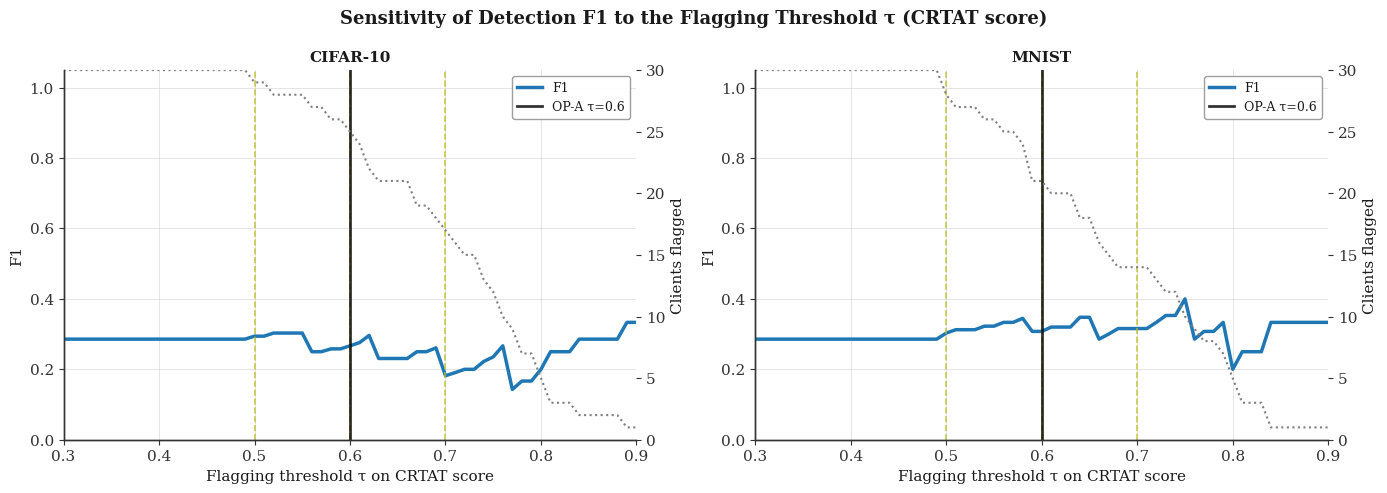

✅ Threshold sensitivity complete.


In [ ]:
# ─── Threshold sensitivity (OP-S): CRTAT scores are fixed; only the flagging threshold varies ───
# AUC does not depend on the threshold, so it is reported once. Confusion counts are given at
# every threshold so that "P = R = F1 = 0" can be told apart from "nothing was flagged".
print("═"*100)
print("  THRESHOLD SENSITIVITY (OP-S) — tau applied to the final per-client CRTAT score")
print("═"*100)
for dc_, name in [(dc_cifar, "CIFAR-10"), (dc_mnist, "MNIST")]:
    print(f"  {name}  | pooled AUC (5 attackers vs 25 honest) = {auc_pooled(dc_):.4f}")
    for thr in SENSITIVITY_THRESHOLDS:
        tag = "  ← principal operating point OP-A" if abs(thr - FLAG_THRESHOLD) < 1e-12 else ""
        print(f"    tau={thr:.2f}: {fmt_counts(confusion_counts(gt_labels, flag_fixed(dc_, thr)))}{tag}")
    print("─"*100)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Sensitivity of Detection F1 to the Flagging Threshold τ (CRTAT score)", fontsize=13, fontweight="bold")
for ax, (dc_, dname) in zip(axes, [(dc_cifar, "CIFAR-10"), (dc_mnist, "MNIST")]):
    thrs = np.linspace(0.3, 0.9, 61)
    f1s  = [confusion_counts(gt_labels, flag_fixed(dc_, t))['f1'] for t in thrs]
    nfl  = [confusion_counts(gt_labels, flag_fixed(dc_, t))['n_flagged'] for t in thrs]
    ax.plot(thrs, f1s, color='#1f77b4', lw=2.5, label='F1')
    ax2 = ax.twinx(); ax2.plot(thrs, nfl, color='#7f7f7f', lw=1.5, ls=':', label='# clients flagged')
    ax2.set_ylabel('Clients flagged'); ax2.set_ylim(0, NUM_CLIENTS)
    for t in SENSITIVITY_THRESHOLDS:
        ax.axvline(t, color='#bcbd22', ls='--', lw=1.2, alpha=0.8)
    ax.axvline(FLAG_THRESHOLD, color='black', ls='-', lw=2, alpha=0.8, label=f'OP-A τ={FLAG_THRESHOLD}')
    ax.set_xlabel('Flagging threshold τ on CRTAT score'); ax.set_ylabel('F1')
    ax.set_title(f'{dname}', fontsize=11); ax.legend(fontsize=9, loc='upper right'); ax.grid(True)
    ax.set_xlim([0.3, 0.9]); ax.set_ylim([0, 1.05])
plt.tight_layout()
plt.savefig('fig_threshold_sensitivity.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('✅ Threshold sensitivity complete.')


## Conclusion (v9 — claims limited to what the printed evidence supports)

CRTAT scores each client from the *trajectory* of its trust values (trend, trend-change, volatility, inversion cosine) fused with an instantaneous score, and records per-round scores in a hash-chained ledger.

### What the experiments can and cannot show
- **Per-attack-type AUC** (Table IV, honest clients as negatives) is the primary detection evidence; the notebook does not presuppose that CRTAT wins on any attack type. The ablation (Table VI) is a replay under the same protocol and its Full row is asserted equal to Table IV.
- **Components** whose removal *raises* AUC are findings to report and to motivate refinement, not exceptions to a blanket "every component helps" statement (the code prints them).
- **Inversion attacker:** the diagnostics cell localises where the signal is lost; scores are never sign-flipped after looking at test results.
- **Ledger:** tamper-evident relative to a trusted checkpoint; with no external anchor a party controlling the whole chain can rewrite it. It is a local audit mechanism, not a decentralised consensus system.
- **Soft weighting** does not bound a boosted update's influence; the influence-bound experiment compares it with explicit norm clipping.
- **Impact** is reported beyond overall accuracy (source-class accuracy, targeted misclassification, clean controls).

### Limitations
15 rounds at 40% participation give ≈6 observations per client; PCA+MLP backbone only; the temporal-consistency row is a simplified FLDetector-*inspired* baseline, not FLDetector; baseline anomaly scores are derived (definitions printed in Step 8) because aggregation rules do not natively output attack probabilities.

### Future work
Faithful FLDetector/trajectory-based baselines, longer horizons, adaptive attackers, participation-aware trajectories, learned sequence detectors.


## Step 14: Computational Cost Benchmark (v6)

Per-method runtime, memory footprint, and blockchain ledger cost. Measures the *additional* cost CRTAT+Blockchain imposes vs simpler defenses, important for justifying deployment in resource-constrained FL settings.

- **Runtime per round**: wall-clock seconds (mean of 3 runs)
- **Memory**: bytes of internal state (history buffers, model params, blockchain)
- **Ledger cost**: bytes per FL round added to the blockchain

All measurements taken on a fixed 30-client setup with the MLP backbone.
**Scope:** this benchmark times *detector computation + aggregation* on synthetic updates only. It excludes local training, ledger construction and ledger verification (timed separately at the end of this cell and in Table VII). Quote the operation a runtime refers to — it is not the cost of a complete FL round or experiment.


In [ ]:
# ─── Computational Cost Benchmark ───────────────────────────────
import time, sys
from copy import deepcopy

# Build a synthetic micro-test environment matching the real setup
_n_test_rounds = 3
_n_test_clients = NUM_CLIENTS
_param_size = MNIST_PARAM_SIZE   # smallest dim, fastest test
rng_b = np.random.default_rng(0)
_test_updates = [rng_b.standard_normal(_param_size).astype(np.float32) * 0.01
                 for _ in range(_n_test_clients)]

def _bench(fn, n=3):
    '''Run fn() n times, return (mean_seconds, mean_memory_used_bytes_estimate).'''
    times = []
    for _ in range(n):
        t0 = time.perf_counter()
        result = fn()
        times.append(time.perf_counter() - t0)
    # Estimate memory of result: array bytes if numpy, else negligible
    mem = 0
    if isinstance(result, np.ndarray):
        mem = result.nbytes
    elif isinstance(result, tuple):
        mem = sum(r.nbytes for r in result if isinstance(r, np.ndarray))
    return float(np.mean(times)), int(mem)

# Benchmark each detection / aggregation method
bench_results = {}

# CRTAT+Blockchain: trust + inversion + CRTAT update + combined_score + soft-penalty agg
def _bench_crtat():
    crtat = CRTAT()
    for _ in range(_n_test_rounds):
        t = blockchain_trust(_test_updates)
        i = inversion_signal(_test_updates)
        crtat.update(t, inv_scores=i)
        s = crtat.combined_score(t)
        w = crtat_weights(s)
        out = fedavg_agg(_test_updates, w)
    return out
bench_results['CRTAT+Blockchain'] = _bench(_bench_crtat)

# Krum
def _bench_krum():
    for _ in range(_n_test_rounds):
        w, sc = krum_select(_test_updates, f=NUM_MALICIOUS)
        out = fedavg_agg(_test_updates, w)
    return out
bench_results['Krum'] = _bench(_bench_krum)

# TrimmedMean
def _bench_tm():
    for _ in range(_n_test_rounds):
        out = trimmed_mean_agg(_test_updates)
    return out
bench_results['TrimmedMean'] = _bench(_bench_tm)

# FoolsGold
def _bench_fg():
    for _ in range(_n_test_rounds):
        w = foolsgold_weights(_test_updates)
        out = fedavg_agg(_test_updates, w)
    return out
bench_results['FoolsGold'] = _bench(_bench_fg)

# CoordMedian
def _bench_med():
    for _ in range(_n_test_rounds):
        out = median_agg(_test_updates)
    return out
bench_results['CoordMedian'] = _bench(_bench_med)

# FedAvg (baseline)
def _bench_fa():
    for _ in range(_n_test_rounds):
        out = fedavg_agg(_test_updates)
    return out
bench_results['FedAvg_NoDefense'] = _bench(_bench_fa)

# Blockchain ledger cost: bytes per FL round
# Each block stores: round_num (8B), trust (n_clients * 8B), crtat (n_clients * 8B),
#                   prev_hash (64B), timestamp (~28B), block_hash (64B)
ledger_bytes_per_round = 8 + NUM_CLIENTS*8 + NUM_CLIENTS*8 + 64 + 28 + 64

# State memory (CRTAT history buffers etc) — only relevant for CRTAT
_crtat_test = CRTAT()
for _ in range(15):
    t = blockchain_trust(_test_updates)
    i = inversion_signal(_test_updates)
    _crtat_test.update(t, inv_scores=i)
_crtat_state_bytes = sum(
    sys.getsizeof(_crtat_test.history[c]) + sum(sys.getsizeof(x) for x in _crtat_test.history[c])
    for c in range(NUM_CLIENTS)
)

# ── Print the cost table ──
print('')
print('╔════════════════════════════════════════════════════════════════════════╗')
print('║  DETECTOR + AGGREGATION COST PER ROUND (no training, no ledger)        ║')
print('║  30 clients · MLP-256 update size · 3-run averages                     ║')
print('╠════════════════════════════════════════════════════════════════════════╣')
print(f'║ {"Method":<22} {"Runtime (ms)":>14} {"Memory (KB)":>14} {"Ledger (KB/rnd)":>15} ║')
print('╠════════════════════════════════════════════════════════════════════════╣')
for m in ['CRTAT+Blockchain','Krum','TrimmedMean','FoolsGold','CoordMedian','FedAvg_NoDefense']:
    rt, mem = bench_results[m]
    rt_ms = rt * 1000 / _n_test_rounds   # per-round
    mem_kb = mem / 1024
    if m == 'CRTAT+Blockchain':
        ledger_kb = ledger_bytes_per_round / 1024
        mem_kb += _crtat_state_bytes / 1024
    else:
        ledger_kb = 0.0
    print(f'║ {m:<22} {rt_ms:>13.2f}  {mem_kb:>13.2f}  {ledger_kb:>14.3f}  ║')
print('╚════════════════════════════════════════════════════════════════════════╝')

# Compute relative overhead vs FedAvg baseline
_fa_rt = bench_results['FedAvg_NoDefense'][0] / _n_test_rounds
_crtat_rt = bench_results['CRTAT+Blockchain'][0] / _n_test_rounds
print(f'\nCRTAT+Blockchain overhead vs FedAvg: {_crtat_rt/_fa_rt:.1f}× runtime')
print(f'Total ledger size for {FL_ROUNDS}-round run: {ledger_bytes_per_round*FL_ROUNDS/1024:.2f} KB')
print(f'\nNote: CRTAT trades modest compute overhead for explicit attacker identification')
print(f'      and tamper-evident audit. Other methods provide neither.')


# ── Separate scopes: ledger construction and verification (15-round ledger, 30 clients) ──
_t0 = time.perf_counter(); _bc_b = TrustBlockchain()
for _r in range(1, FL_ROUNDS+1): _bc_b.add_round(_r, np.random.rand(NUM_CLIENTS), np.random.rand(NUM_CLIENTS), [])
_build_ms = (time.perf_counter()-_t0)*1000
_t0 = time.perf_counter(); _bc_b.is_valid(); _verify_ms = (time.perf_counter()-_t0)*1000
print(f'\nLedger construction ({FL_ROUNDS} blocks): {_build_ms:.2f} ms total = {_build_ms/FL_ROUNDS:.3f} ms/round')
print(f'Ledger verification  ({FL_ROUNDS} blocks): {_verify_ms:.2f} ms (one full is_valid() pass)')
print('Local training is NOT included in any number above; see Table VII timing columns and the protocol-check cell.')



╔════════════════════════════════════════════════════════════════════════╗
║  DETECTOR + AGGREGATION COST PER ROUND (no training, no ledger)        ║
║  30 clients · MLP-256 update size · 3-run averages                     ║
╠════════════════════════════════════════════════════════════════════════╣
║ Method                   Runtime (ms)    Memory (KB) Ledger (KB/rnd) ║
╠════════════════════════════════════════════════════════════════════════╣
║ CRTAT+Blockchain               26.73         283.02           0.629  ║
║ Krum                           86.55         267.08           0.000  ║
║ TrimmedMean                     5.33         133.54           0.000  ║
║ FoolsGold                      11.78         267.08           0.000  ║
║ CoordMedian                    24.86         133.54           0.000  ║
║ FedAvg_NoDefense                1.60         267.08           0.000  ║
╚════════════════════════════════════════════════════════════════════════╝

CRTAT+Blockchain overhead vs FedAvg: 

## 📋 Step 16: CIFAR-100 Results (v7 NEW)

CIFAR-100 (100 fine-grained classes, same PCA-512/MLP/attack budget as CIFAR-10)
is added as a third benchmark dataset to test whether CRTAT+Blockchain's
detection advantage holds as the classification task becomes harder and
per-class client data becomes sparser (100 classes vs 10, same sample budget).


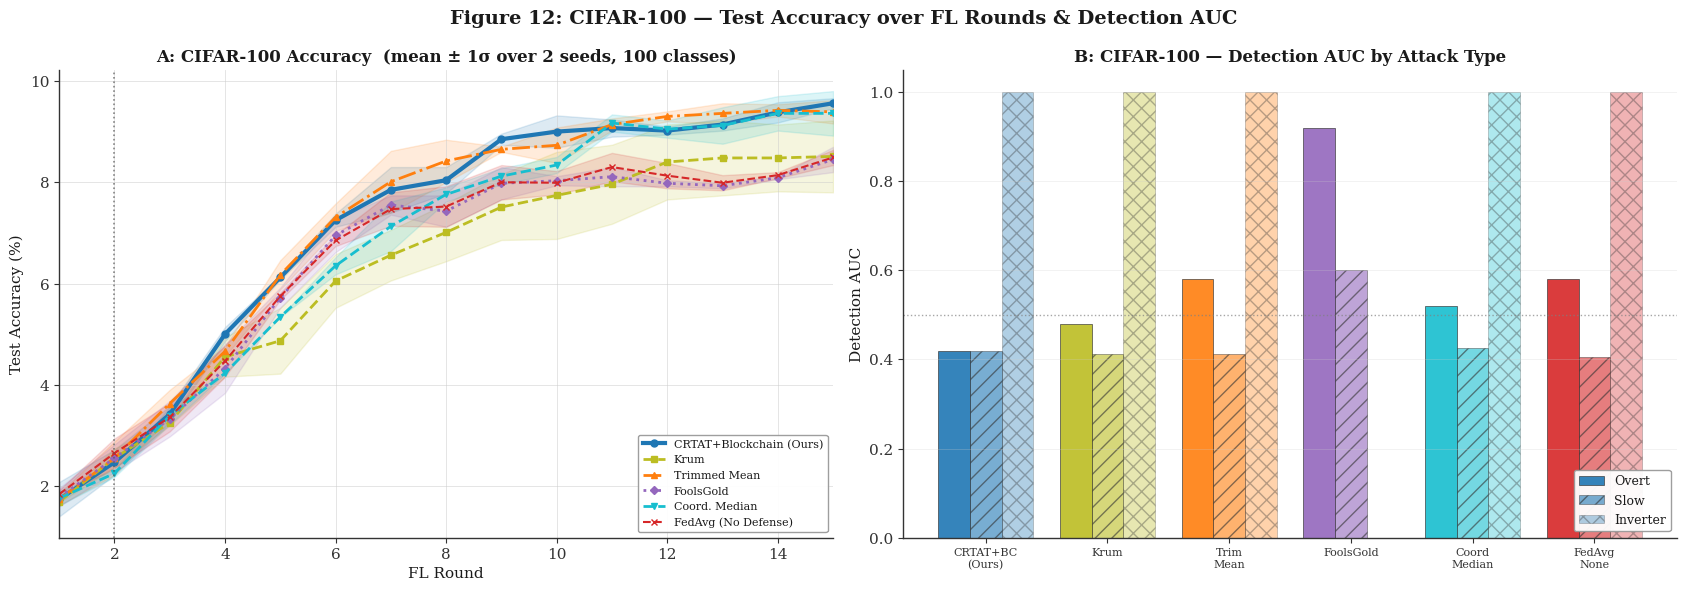

✅ Figure 12 saved (CIFAR-100).

CIFAR-100 Summary (multi-seed mean ± std)
══════════════════════════════════════════════════════════════════════════════
Method                     Accuracy  Overt AUC   Slow AUC    Inv AUC
──────────────────────────────────────────────────────────────────────────────
  CRTAT+Blockchain        9.56± 0.1%      0.420     0.420     1.000
  Krum                    8.51± 0.7%      0.480     0.413     1.000
  TrimmedMean             9.39± 0.2%      0.580     0.413     1.000
  FoolsGold               8.45± 0.2%      0.920     0.600     0.000
  CoordMedian             9.36± 0.4%      0.520     0.427     1.000
  FedAvg_NoDefense        8.49± 0.2%      0.580     0.407     1.000


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
fig.suptitle('Figure 12: CIFAR-100 — Test Accuracy over FL Rounds & Detection AUC',
             fontsize=14, fontweight='bold')

# Panel A — accuracy over rounds
ax = axes[0]
n_rounds = agg_cifar100['min_rounds']
rounds_axis = list(range(1, n_rounds+1))
for m, st in MSTYLES.items():
    mean = agg_cifar100['acc_mean'][m] * 100
    std  = agg_cifar100['acc_std'][m]  * 100
    ax.plot(rounds_axis, mean, label=MLABELS[m], **st)
    ax.fill_between(rounds_axis, mean-std, mean+std, color=st['color'], alpha=0.15)
ax.axvline(SLOW_RAMP_START, color='#555555', lw=1.2, ls=':', alpha=0.7)
ax.set_xlabel('FL Round'); ax.set_ylabel('Test Accuracy (%)')
ax.set_title(f'A: CIFAR-100 Accuracy  (mean ± 1σ over {len(SEEDS)} seeds, 100 classes)', fontsize=12)
ax.legend(fontsize=8); ax.grid(True); ax.set_xlim([1, max(rounds_axis)])

# Panel B — detection AUC bar (overt / slow / inverse) for CIFAR-100
tbl_c100 = method_auc_table(results_cifar100)
auc_overt_c100   = [tbl_c100[m]['mean'][0] for m in METHODS]
auc_slow_c100    = [tbl_c100[m]['mean'][1] for m in METHODS]
auc_inverse_c100 = [tbl_c100[m]['mean'][2] for m in METHODS]

ax = axes[1]
xw = 0.26
ax.bar(xp - xw, auc_overt_c100,   xw, color=MCOLS, alpha=0.9,  edgecolor='#333333', lw=0.5, label='Overt')
ax.bar(xp,       auc_slow_c100,   xw, color=MCOLS, alpha=0.6,  edgecolor='#333333', lw=0.5, hatch='//', label='Slow')
ax.bar(xp + xw,  auc_inverse_c100,xw, color=MCOLS, alpha=0.35, edgecolor='#333333', lw=0.5, hatch='xx', label='Inverter')
ax.axhline(0.5, color='gray', ls=':', lw=1, alpha=0.7)
ax.set_xticks(xp); ax.set_xticklabels(MDISP, fontsize=8)
ax.set_ylim([0, 1.05]); ax.set_ylabel('Detection AUC')
ax.set_title('B: CIFAR-100 — Detection AUC by Attack Type', fontsize=12)
ax.legend(fontsize=9, loc='lower right'); ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('fig12_cifar100.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('✅ Figure 12 saved (CIFAR-100).')

final_acc_c100     = [agg_cifar100['acc_mean'][m][-1]*100 for m in METHODS]
final_acc_c100_std = [agg_cifar100['acc_std'][m][-1]*100  for m in METHODS]
auc_c100 = [tbl_c100[m]['mean'][3] for m in METHODS]

print()
print('CIFAR-100 Summary (multi-seed mean ± std)')
print('═'*78)
print(f'{"Method":<20} {"Accuracy":>14} {"Overt AUC":>10} {"Slow AUC":>10} {"Inv AUC":>10}')
print('─'*78)
for i, m in enumerate(METHODS):
    print(f'  {m:<18} {final_acc_c100[i]:>9.2f}±{final_acc_c100_std[i]:>4.1f}%  '
          f'{auc_overt_c100[i]:>9.3f} {auc_slow_c100[i]:>9.3f} {auc_inverse_c100[i]:>9.3f}')


## 📊 Figure 13: Dirichlet Non-IID Client Distribution (v7 NEW — Result Analysis)

Visualizes the label-skew produced by `split_dirichlet` (α=0.5): the per-client,
per-class sample counts for CIFAR-10 and MNIST (stacked bars, 10 classes), and a
client × class heatmap for CIFAR-100 (100 classes — too many categories for a
readable stacked bar). A quantitative heterogeneity score (normalised Shannon
entropy of each client's class distribution, averaged over clients — 1.0 = IID,
0.0 = each client holds a single class) is reported alongside each panel.


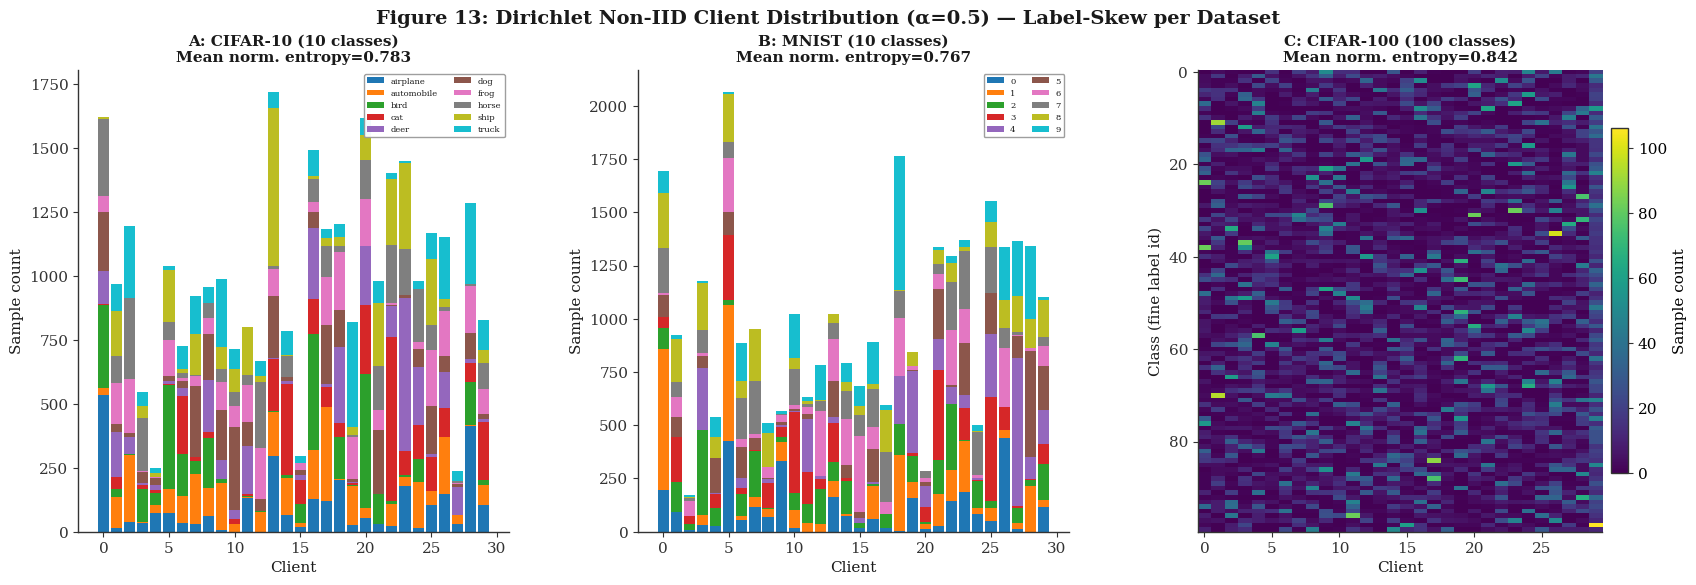

✅ Figure 13 saved.
   Mean normalised entropy — CIFAR-10: 0.783 | CIFAR-100: 0.842 | MNIST: 0.767  (1.0=IID, 0.0=single-class)


In [ ]:
def class_count_matrix(client_split, n_classes):
    """(n_clients, n_classes) matrix of per-client class counts."""
    n_clients = len(client_split)
    M = np.zeros((n_clients, n_classes), dtype=int)
    for cid, (_, y_c) in enumerate(client_split):
        for c in range(n_classes):
            M[cid, c] = int((y_c == c).sum())
    return M

def mean_normalised_entropy(count_matrix):
    """Mean over clients of Shannon entropy of the class distribution,
    normalised to [0,1] by log(n_classes). 1.0 = perfectly IID, 0.0 = single-class."""
    n_classes = count_matrix.shape[1]
    p = count_matrix / (count_matrix.sum(1, keepdims=True) + 1e-12)
    ent = -np.sum(p * np.log(p + 1e-12), axis=1) / np.log(n_classes)
    return float(ent.mean())

cnt_cifar    = class_count_matrix(client_cifar,    N_CLASSES)
cnt_cifar100 = class_count_matrix(client_cifar100, N_CLASSES_C100)
cnt_mnist    = class_count_matrix(client_mnist,    N_CLASSES)

ent_cifar    = mean_normalised_entropy(cnt_cifar)
ent_cifar100 = mean_normalised_entropy(cnt_cifar100)
ent_mnist    = mean_normalised_entropy(cnt_mnist)

fig = plt.figure(figsize=(20, 6))
fig.suptitle('Figure 13: Dirichlet Non-IID Client Distribution (α=0.5) — Label-Skew per Dataset',
             fontsize=14, fontweight='bold')
gs = gridspec.GridSpec(1, 3, figure=fig, wspace=0.30)

class_cmap = plt.get_cmap('tab10')

# Panel A — CIFAR-10 stacked bar
ax = fig.add_subplot(gs[0])
bottom = np.zeros(NUM_CLIENTS)
for c in range(N_CLASSES):
    ax.bar(range(NUM_CLIENTS), cnt_cifar[:, c], bottom=bottom,
           color=class_cmap(c % 10), width=0.85,
           label=CIFAR10_CLASSES[c] if NUM_CLIENTS <= 40 else None)
    bottom += cnt_cifar[:, c]
ax.set_title(f'A: CIFAR-10 (10 classes)\nMean norm. entropy={ent_cifar:.3f}', fontsize=11)
ax.set_xlabel('Client'); ax.set_ylabel('Sample count')
ax.legend(fontsize=6, ncol=2, loc='upper right')

# Panel B — MNIST stacked bar
ax = fig.add_subplot(gs[1])
bottom = np.zeros(NUM_CLIENTS)
for c in range(N_CLASSES):
    ax.bar(range(NUM_CLIENTS), cnt_mnist[:, c], bottom=bottom,
           color=class_cmap(c % 10), width=0.85,
           label=MNIST_CLASSES[c] if NUM_CLIENTS <= 40 else None)
    bottom += cnt_mnist[:, c]
ax.set_title(f'B: MNIST (10 classes)\nMean norm. entropy={ent_mnist:.3f}', fontsize=11)
ax.set_xlabel('Client'); ax.set_ylabel('Sample count')
ax.legend(fontsize=6, ncol=2, loc='upper right')

# Panel C — CIFAR-100 heatmap (100 classes: too many to stack legibly)
ax = fig.add_subplot(gs[2])
im = ax.imshow(cnt_cifar100.T, aspect='auto', cmap='viridis')
ax.set_title(f'C: CIFAR-100 (100 classes)\nMean norm. entropy={ent_cifar100:.3f}', fontsize=11)
ax.set_xlabel('Client'); ax.set_ylabel('Class (fine label id)')
cb = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cb.set_label('Sample count', color='black')
plt.setp(cb.ax.yaxis.get_ticklabels(), color='black')

plt.tight_layout()
plt.savefig('fig13_dirichlet_distribution.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('✅ Figure 13 saved.')
print(f'   Mean normalised entropy — CIFAR-10: {ent_cifar:.3f} | '
      f'CIFAR-100: {ent_cifar100:.3f} | MNIST: {ent_mnist:.3f}  (1.0=IID, 0.0=single-class)')


## 📊 Figure 14: Reconstruction-Error Distribution (v7 NEW — Result Analysis)

Visualizes the data-quality skew produced by `split_reconstruction_error`: the
overall per-sample PCA reconstruction-error histogram (with the quantile bin
edges used for the split marked), and the resulting per-client mean
reconstruction error for each dataset — malicious client IDs are colour-coded
so any correlation between attacker placement and data "typicality" is visible
at a glance. Reconstruction error is a *partitioning axis only* (not a CRTAT input). A CIFAR-10 accuracy/detection comparison between the Dirichlet
(label-skew) and Reconstruction-Error (quality-skew) splits is also reported,
to check that CRTAT+Blockchain's advantage is not an artifact of one
particular Non-IID partitioning strategy.


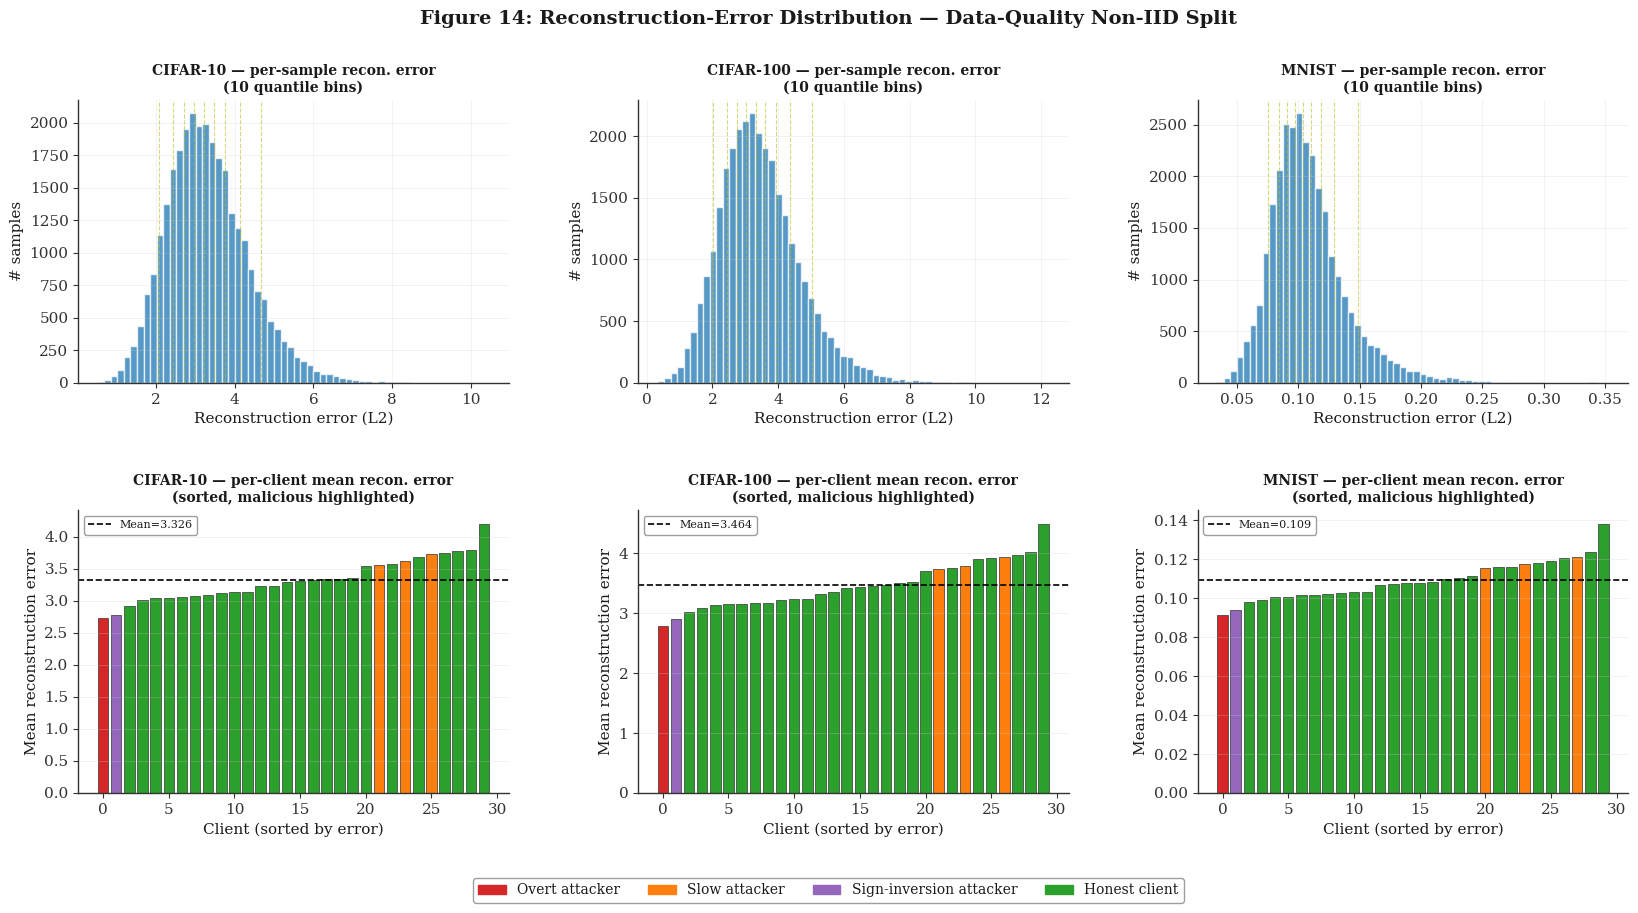

✅ Figure 14 saved.


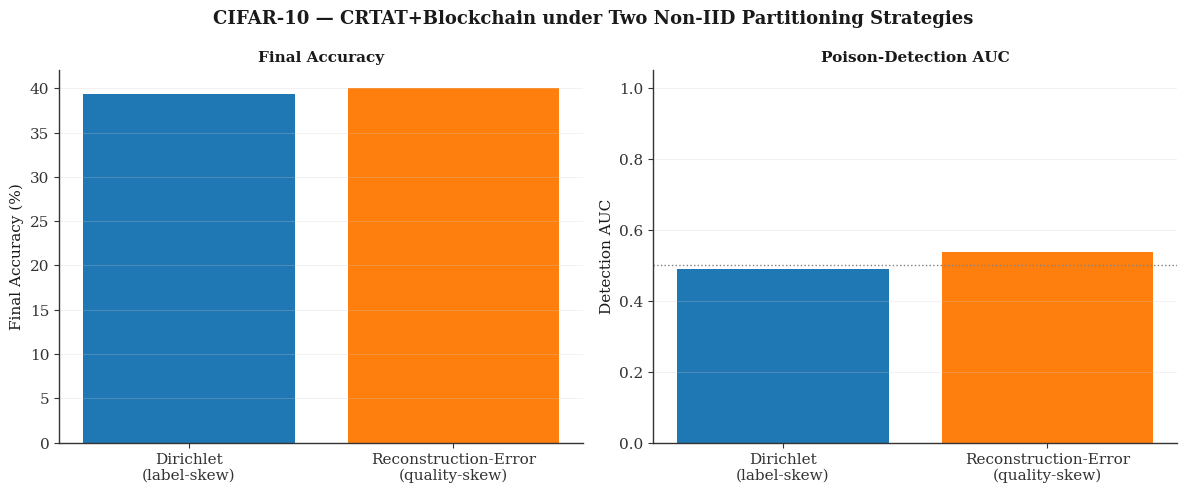

✅ Split-comparison figure saved.
   CIFAR-10 Dirichlet split         : acc=39.32%  AUC=0.4880
   CIFAR-10 Reconstruction-Err split : acc=40.08%  AUC=0.5360


In [ ]:
fig = plt.figure(figsize=(20, 9))
fig.suptitle('Figure 14: Reconstruction-Error Distribution — Data-Quality Non-IID Split',
             fontsize=14, fontweight='bold')
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.30)

_RECON_CFG = [
    ('CIFAR-10',  err_all_cifar,    err_mean_cifar),
    ('CIFAR-100', err_all_cifar100, err_mean_cifar100),
    ('MNIST',     err_all_mnist,    err_mean_mnist),
]

# Row 1 — overall per-sample reconstruction-error histogram + bin edges
for col, (dname, err_all, _) in enumerate(_RECON_CFG):
    ax = fig.add_subplot(gs[0, col])
    ax.hist(err_all, bins=60, color='#1f77b4', alpha=0.75, edgecolor='white')
    edges = np.quantile(err_all, np.linspace(0, 1, RECON_ERROR_BINS + 1))
    for e in edges[1:-1]:
        ax.axvline(e, color='#bcbd22', lw=0.8, ls='--', alpha=0.6)
    ax.set_title(f'{dname} — per-sample recon. error\n({RECON_ERROR_BINS} quantile bins)', fontsize=10)
    ax.set_xlabel('Reconstruction error (L2)'); ax.set_ylabel('# samples')
    ax.grid(True, alpha=0.3)

# Row 2 — per-client mean reconstruction error, malicious clients highlighted
for col, (dname, _, err_mean) in enumerate(_RECON_CFG):
    ax = fig.add_subplot(gs[1, col])
    colors = [_attack_color(i) for i in range(NUM_CLIENTS)]
    order = np.argsort(err_mean)
    ax.bar(range(NUM_CLIENTS), err_mean[order], color=[colors[i] for i in order],
           edgecolor='#333333', lw=0.5)
    ax.axhline(err_mean.mean(), color='black', ls='--', lw=1.2,
               label=f'Mean={err_mean.mean():.3f}')
    ax.set_title(f'{dname} — per-client mean recon. error\n(sorted, malicious highlighted)', fontsize=10)
    ax.set_xlabel('Client (sorted by error)'); ax.set_ylabel('Mean reconstruction error')
    ax.legend(fontsize=8); ax.grid(True, axis='y', alpha=0.3)

fig.legend(handles=legend_handles, loc='lower center', ncol=4, fontsize=10,
           bbox_to_anchor=(0.5, -0.02))
plt.tight_layout()
plt.savefig('fig14_reconstruction_error_distribution.png', dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()
print('✅ Figure 14 saved.')

# ── CIFAR-10: Dirichlet split vs Reconstruction-Error split comparison ──
mt_cifar_recon, db_cifar_recon, dc_cifar_recon = client_scores_from_result(result_cifar_recon)
auc_dirichlet_split = safe_auc(dc_cifar, gt_labels)
auc_recon_split      = safe_auc(dc_cifar_recon, gt_labels)
acc_dirichlet_split  = hist_cifar['CRTAT+Blockchain']['acc'][-1] * 100
acc_recon_split      = hist_cifar_recon['CRTAT+Blockchain']['acc'][-1] * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('CIFAR-10 — CRTAT+Blockchain under Two Non-IID Partitioning Strategies',
             fontsize=13, fontweight='bold')

ax = axes[0]
ax.bar(['Dirichlet\n(label-skew)', 'Reconstruction-Error\n(quality-skew)'],
       [acc_dirichlet_split, acc_recon_split], color=['#1f77b4', '#ff7f0e'])
ax.set_ylabel('Final Accuracy (%)'); ax.set_title('Final Accuracy', fontsize=11)
ax.grid(True, axis='y', alpha=0.3)

ax = axes[1]
ax.bar(['Dirichlet\n(label-skew)', 'Reconstruction-Error\n(quality-skew)'],
       [auc_dirichlet_split, auc_recon_split], color=['#1f77b4', '#ff7f0e'])
ax.axhline(0.5, color='gray', ls=':', lw=1)
ax.set_ylabel('Detection AUC'); ax.set_title('Poison-Detection AUC', fontsize=11)
ax.set_ylim([0, 1.05]); ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('fig14b_split_comparison.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('✅ Split-comparison figure saved.')
print(f'   CIFAR-10 Dirichlet split         : acc={acc_dirichlet_split:.2f}%  AUC={auc_dirichlet_split:.4f}')
print(f'   CIFAR-10 Reconstruction-Err split : acc={acc_recon_split:.2f}%  AUC={auc_recon_split:.4f}')


## 🔬 Figure 15: Component-Wise Ablation (replay, v9)

Replays the *recorded* per-round trust, inversion and **participation-mask** signals through CRTAT variants with one component removed, using exactly the main-run scoring protocol (`final_signal`, honest-only negatives). Before any table is printed the code asserts that the Full-CRTAT replay equals the main-run scores, so Table VI / Figure 15 / Table IV cannot silently disagree. Two extension rows (participation-aware history, no trust recovery) are listed separately.


Replay-reproduction checks (Full CRTAT replay must equal the main run):
  Replay check [CIFAR-10]: Full-CRTAT replay vs main-run scores → REPRODUCED ✅
  Replay check [MNIST]: Full-CRTAT replay vs main-run scores → REPRODUCED ✅
  Cross-table check: Full CRTAT (ablation) == CRTAT+Blockchain (main table) on both datasets ✅

Pooled-AUC identity (same 25 honest negatives for every attack type):
  CIFAR-10 seed 42: pooled=0.4880  count-weighted per-type mean=0.4880  identity holds: True
  CIFAR-10 seed 123: pooled=0.6160  count-weighted per-type mean=0.6160  identity holds: True
  MNIST seed 42: pooled=0.6560  count-weighted per-type mean=0.6560  identity holds: True
  MNIST seed 123: pooled=0.7280  count-weighted per-type mean=0.7280  identity holds: True

CRTAT COMPONENT-WISE ABLATION — pooled AUC (5 attackers vs 25 honest), mean over seeds
Variant                                        CIFAR-10 AUC  Δ vs Full    MNIST AUC  Δ vs Full
--------------------------------------------------------

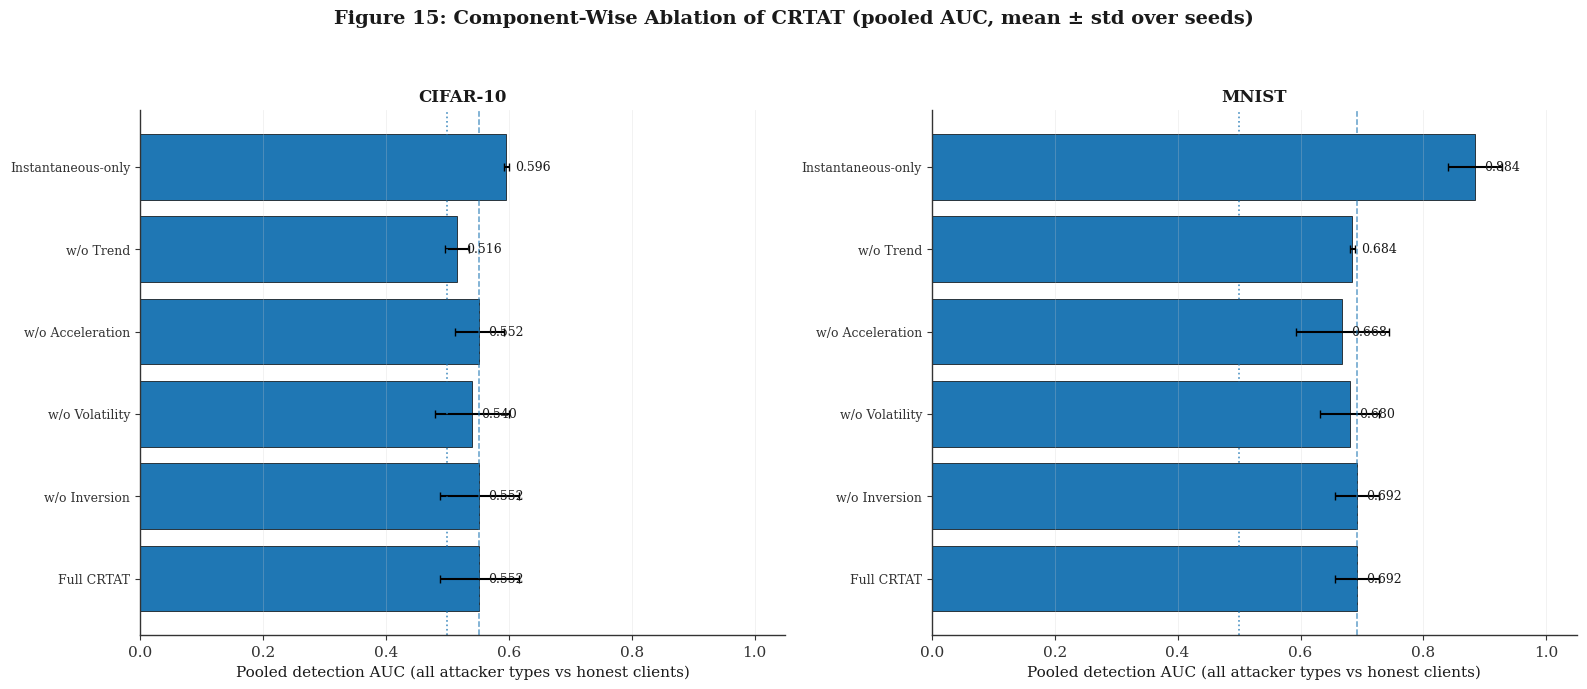


Figure 15 saved: fig15_component_ablation.png


In [ ]:
# ═════════════════════════════════════════════════════════════════════════════
# Component ablation by REPLAY of recorded signals — now with the SAME protocol as the main run
# (reviewer §3A). Earlier replay differences that made "Full CRTAT" ≠ the proposed method:
#   • final score was the LAST round only, the main run used a last-3-round mean;
#   • replay passed participated_mask=None, so non-participating rounds were appended to the
#     inversion history (as 0.0), which the main run never does;
#   • Table IV averaged scores across seeds before the AUC, Table VI averaged per-seed AUCs;
#   • per-attack AUCs used all other clients (incl. other attackers) as negatives.
# All four are removed: replay uses the recorded participation masks, the same final_signal
# rule and honest-only negatives, and the Full row is ASSERTED equal to the main-run score.
# ═════════════════════════════════════════════════════════════════════════════
def crtat_replay(res, use_inversion=True, **crtat_kwargs):
    ts, inv, extras = res[1], res[10], res[11]
    mask = extras['mask']
    crtat = CRTAT(**crtat_kwargs)
    full = np.zeros(ts.shape); obs = np.full(ts.shape, np.nan)
    for r in range(ts.shape[0]):
        crtat.update(ts[r], participated_mask=mask[r], inv_scores=(inv[r] if use_inversion else None))
        sc = crtat.combined_score(ts[r]); full[r] = sc; obs[r] = np.where(mask[r], sc, np.nan)
    return final_signal(obs), full

def verify_replay_reproduces_main(results, dname):
    ok = True
    for r in results:
        sc, full = crtat_replay(r)
        ok &= bool(np.allclose(full, r[2], atol=1e-10))                  # per-round CRTAT scores
        ok &= bool(np.allclose(sc, r[6]['CRTAT+Blockchain'], atol=1e-10))  # final signal
    status = 'REPRODUCED ✅' if ok else 'MISMATCH ❌ (do not report Table VI until resolved)'
    print(f'  Replay check [{dname}]: Full-CRTAT replay vs main-run scores → {status}')
    assert ok, f'Replay does not reproduce the main run for {dname}'

ABLATION_VARIANTS = [
    ('Instantaneous-only', dict(gamma=0.0)),
    ('w/o Trend',          dict(alpha=0.0)),
    ('w/o Acceleration',   dict(delta=0.0)),       # = w/o trend-change term
    ('w/o Volatility',     dict(beta=0.0)),
    ('w/o Inversion',      dict(use_inversion=False)),
    ('Full CRTAT',         dict()),
]
EXTENSION_VARIANTS = [   # added in response to the review; reported below the original six
    ('Full, participation-aware (skip absent)', dict(missing='skip')),
    ('Full, no trust recovery (decay=1.0)',     dict(decay=1.0)),
]
COMPONENT_ABLATION_ORDER = [n for n, _ in ABLATION_VARIANTS]

def ablation_table(results, variants):
    """name -> dict(columns, mean, std) ; columns = overt, slow, inversion, pooled, F1@OP-A, F1@OP-B, #flagged@OP-A"""
    out = {}
    for name, kw in variants:
        kw = dict(kw); use_inv = kw.pop('use_inversion', True); rows = []
        for r in results:
            sc, _ = crtat_replay(r, use_inversion=use_inv, **kw)
            pt = auc_per_type(sc)
            cA = confusion_counts(gt_labels, OPERATING_POINTS['OP-A']['fn'](sc))
            cB = confusion_counts(gt_labels, OPERATING_POINTS['OP-B']['fn'](sc))
            rows.append([pt['overt'], pt['slow'], pt['inversion'], auc_pooled(sc), cA['f1'], cB['f1'], cA['n_flagged']])
        a = np.array(rows); out[name] = dict(mean=a.mean(0), std=a.std(0), per_seed=a)
    return out

print('Replay-reproduction checks (Full CRTAT replay must equal the main run):')
verify_replay_reproduces_main(results_cifar, 'CIFAR-10')
verify_replay_reproduces_main(results_mnist, 'MNIST')

abl_cifar = ablation_table(results_cifar, ABLATION_VARIANTS + EXTENSION_VARIANTS)
abl_mnist = ablation_table(results_mnist, ABLATION_VARIANTS + EXTENSION_VARIANTS)
# keep the legacy names used by the Figure-15 plot / older cells (pooled AUC, mean over seeds)
ablation_auc_cifar = {n: abl_cifar[n]['mean'][3] for n in abl_cifar}
ablation_auc_mnist = {n: abl_mnist[n]['mean'][3] for n in abl_mnist}

# Cross-table consistency: Full CRTAT here must equal the proposed method in the main-run table
tblm_c = method_auc_table(results_cifar, ['CRTAT+Blockchain']); tblm_m = method_auc_table(results_mnist, ['CRTAT+Blockchain'])
for dname, ab, tb in [('CIFAR-10', abl_cifar, tblm_c), ('MNIST', abl_mnist, tblm_m)]:
    assert np.allclose(ab['Full CRTAT']['mean'][:4], tb['CRTAT+Blockchain']['mean'], atol=1e-10), \
        f'Full CRTAT (ablation) ≠ proposed method (main table) on {dname}'
print('  Cross-table check: Full CRTAT (ablation) == CRTAT+Blockchain (main table) on both datasets ✅\n')

# Pooled-AUC identity check (reviewer §3E)
print('Pooled-AUC identity (same 25 honest negatives for every attack type):')
for dname, results in [('CIFAR-10', results_cifar), ('MNIST', results_mnist)]:
    for r in results:
        p, w, ok = pooled_identity_check(r[6]['CRTAT+Blockchain'])
        print(f'  {dname} seed {r[11]["seed"]}: pooled={p:.4f}  count-weighted per-type mean={w:.4f}  identity holds: {ok}')

print('\n' + '=' * 96)
print('CRTAT COMPONENT-WISE ABLATION — pooled AUC (5 attackers vs 25 honest), mean over seeds')
print('=' * 96)
print(f"{'Variant':<44}{'CIFAR-10 AUC':>15}{'Δ vs Full':>11}{'MNIST AUC':>13}{'Δ vs Full':>11}")
print('-' * 96)
fc, fm = abl_cifar['Full CRTAT']['mean'][3], abl_mnist['Full CRTAT']['mean'][3]
for name, _ in ABLATION_VARIANTS + EXTENSION_VARIANTS:
    c, m = abl_cifar[name]['mean'][3], abl_mnist[name]['mean'][3]
    print(f"{name:<44}{c:>15.4f}{c-fc:>+11.4f}{m:>13.4f}{m-fm:>+11.4f}")
    if name == 'Full CRTAT': print('  ' + '· extensions (added after review) ·')

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Figure 15: Component-Wise Ablation of CRTAT (pooled AUC, mean ± std over seeds)', fontsize=14, fontweight='bold')
for ax, (dname, ab) in zip(axes, [('CIFAR-10', abl_cifar), ('MNIST', abl_mnist)]):
    names = COMPONENT_ABLATION_ORDER; y = np.arange(len(names))
    vals = [ab[n]['mean'][3] for n in names]; errs = [ab[n]['std'][3] for n in names]
    ax.barh(y, vals, xerr=errs, edgecolor='black', linewidth=0.5, capsize=3)
    ax.axvline(0.50, linestyle=':', linewidth=1.2, alpha=0.8)
    ax.axvline(ab['Full CRTAT']['mean'][3], linestyle='--', linewidth=1.1, alpha=0.7)
    ax.set_yticks(y); ax.set_yticklabels(names, fontsize=9); ax.invert_yaxis()
    ax.set_xlabel('Pooled detection AUC (all attacker types vs honest clients)', fontsize=11)
    ax.set_title(dname, fontsize=12, fontweight='bold'); ax.set_xlim(0, 1.05); ax.grid(True, axis='x', alpha=0.3)
    for yi, v in zip(y, vals): ax.text(v + 0.015, yi, f'{v:.3f}', va='center', fontsize=9)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('fig15_component_ablation.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('\nFigure 15 saved: fig15_component_ablation.png')


## 📋 Table VI: CRTAT Component Ablation (replay, same protocol as Table IV)

Per-attack AUC (positives = that attack type, negatives = 25 honest clients), pooled AUC, and F1 / #flagged at the two labelled operating points; mean ± std over `SEEDS`. The text comparing variants is generated from the table (see the printed 'AUTO-GENERATED ABLATION STATEMENT').


In [ ]:
# ─── Table VI: CRTAT component ablation (replay; same protocol as the main run) ───────────────
# Per-attack AUC: positives = that attack type, negatives = the 25 honest clients, per seed → mean±std.
# F1 / #flagged are shown at the two labelled operating points (OP-A principal, OP-B secondary).
def table_vi(ab, dname):
    print(f'\nTable VI — CRTAT component ablation | {dname} | replay of recorded signals | mean±std over seeds {SEEDS}')
    print('═'*128)
    print(f'{"Variant":<44}{"Overt AUC":>13}{"Slow AUC":>13}{"Inv. AUC":>13}{"Pooled AUC":>13}{"F1 OP-A":>13}{"F1 OP-B":>13}{"#flag OP-A":>10}')
    print('─'*128)
    for sep, rows in [(False, ABLATION_VARIANTS), (True, EXTENSION_VARIANTS)]:
        if sep: print('  · extensions added after review ·')
        for name, _ in rows:
            m, s = ab[name]['mean'], ab[name]['std']
            cells = [f'{m[k]:.3f}±{s[k]:.3f}' for k in range(6)] + [f'{m[6]:.1f}']
            print(f'{name:<44}' + ''.join(f'{c:>{w}}' for c, w in zip(cells, [13,13,13,13,13,13,10])))
    print('═'*128)

table_vi(abl_cifar, 'CIFAR-10')
table_vi(abl_mnist, 'MNIST')

# ── Auto-generated comparison text (reviewer §3B) — the sentence is derived from the table, never typed by hand ──
def ablation_statement(ab, dname, a='Instantaneous-only', b='Full CRTAT'):
    names = ['overt-attack', 'slow-attack', 'inversion']; better, worse, same = [], [], []
    for k, nm in enumerate(names):
        d = ab[a]['mean'][k] - ab[b]['mean'][k]
        (better if d > 1e-3 else worse if d < -1e-3 else same).append(f'{nm} ({ab[a]["mean"][k]:.3f} vs {ab[b]["mean"][k]:.3f})')
    parts = []
    if better: parts.append(f'higher {a} AUC than {b} for ' + ', '.join(better))
    if worse:  parts.append(f'lower for ' + ', '.join(worse))
    if same:   parts.append(f'equal (±0.001) for ' + ', '.join(same))
    return f'{dname}: ' + '; '.join(parts) + '.'
print('\nAUTO-GENERATED ABLATION STATEMENT (paste into the manuscript instead of hand-written comparisons):')
print('  ' + ablation_statement(abl_cifar, 'CIFAR-10'))
print('  ' + ablation_statement(abl_mnist, 'MNIST'))
print('  (the previous manuscript text claimed Instantaneous-only had higher overt AND slow AUC on CIFAR-10;')
print('   check the generated sentence above against the rerun table before reusing any wording)')

# Components whose removal does not hurt (honest reporting — these motivate refinement, not a blanket claim)
print('\nComponents whose removal INCREASES pooled AUC (Δ>0 vs Full) — report these as findings:')
for dname, ab in [('CIFAR-10', abl_cifar), ('MNIST', abl_mnist)]:
    fullp = ab['Full CRTAT']['mean'][3]
    hits = [(n, ab[n]['mean'][3]-fullp) for n, _ in ABLATION_VARIANTS if n != 'Full CRTAT' and ab[n]['mean'][3] - fullp > 1e-3]
    print(f'  {dname}: ' + (', '.join(f'{n} ({d:+.3f})' for n, d in hits) if hits else 'none'))
# 'w/o Inversion' identical to Full? check whether the inversion term changes ANY rank
for dname, results in [('CIFAR-10', results_cifar), ('MNIST', results_mnist)]:
    same_rank = all(np.array_equal(np.argsort(crtat_replay(r)[0], kind='stable'),
                                   np.argsort(crtat_replay(r, use_inversion=False)[0], kind='stable')) for r in results)
    maxdiff = max(np.abs(crtat_replay(r)[0] - crtat_replay(r, use_inversion=False)[0]).max() for r in results)
    print(f'  {dname}: inversion term changes client ranking? {"NO (AUC identical by construction)" if same_rank else "yes"}  | max |Δscore| = {maxdiff:.4f}')



Table VI — CRTAT component ablation | CIFAR-10 | replay of recorded signals | mean±std over seeds [42, 123]
════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
Variant                                         Overt AUC     Slow AUC     Inv. AUC   Pooled AUC      F1 OP-A      F1 OP-B#flag OP-A
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Instantaneous-only                            0.660±0.220  0.440±0.067  1.000±0.000  0.596±0.004  0.286±0.000  0.357±0.071      30.0
w/o Trend                                     0.460±0.060  0.380±0.060  0.980±0.020  0.516±0.020  0.215±0.015  0.214±0.071      18.0
w/o Acceleration                              0.500±0.180  0.427±0.133  0.980±0.020  0.552±0.040  0.244±0.022  0.214±0.071      23.5
w/o Volatility                                0.540±0.140  0.387±0.053  1.000±0.000  0.540±0.060  0.2

## 🔎 Inversion-Attacker Diagnostics (checks only — no score reversal, no post-hoc variant selection)


In [ ]:
# ═════════════════════════════════════════════════════════════════════════════
# Inversion-attacker diagnostics (reviewer §3G). These are CHECKS, not tuning: the score direction
# is NOT reversed and no choice below is made by looking at which one gives the best AUC.
#   1. positive-label definition        4. mean/median-reference contamination (leave-one-out, honest-only ref.)
#   2. update-sign / scale convention   5. is the inversion history recorded correctly?
#   3. score orientation                6. where does the signal get lost: instantaneous → temporal → final
# ═════════════════════════════════════════════════════════════════════════════
def inversion_diagnostics(res, dname, X_dummy=None):
    ts, inv, extras = res[1], res[10], res[11]
    mask = extras['mask']; R = ts.shape[0]; k = INVERSE_CLIENTS[0]
    print('═'*100); print(f'INVERSION DIAGNOSTICS — {dname} (seed {extras["seed"]})'); print('═'*100)
    # 1 labels
    print(f'1. Positive-label definition : INVERSE_CLIENTS={INVERSE_CLIENTS}, gt_inverse positives={int(sum(gt_inverse))}, '
          f'negatives used in AUC = {len(HONEST_CLIENTS)} honest clients (legacy code also used the other 4 attackers).')
    # 2 sign convention
    print(f'2. Update convention         : delta_sent = INVERSE_SCALE × delta_local with INVERSE_SCALE={INVERSE_SCALE} '
          f'→ sign flip AND ×{abs(INVERSE_SCALE):g} amplification (documentation elsewhere says "−1×"). '
          f'Participation of C{k:02d}: {int(mask[:, k].sum())}/{R} rounds.')
    # 3 orientation : instantaneous trust of inverter vs honest, in rounds where inverter participated
    rounds_k = np.where(mask[:, k])[0]
    if len(rounds_k):
        tr_k = ts[rounds_k, k]
        tr_h = np.array([ts[r, [h for h in HONEST_CLIENTS if mask[r, h]]].mean() for r in rounds_k])
        inst_auc = [round_auc(1 - np.clip(ts[r], -1, 1)/2, mask[r], INVERSE_CLIENTS) for r in rounds_k]
        print(f'3. Orientation               : mean trust C{k:02d} (observed rounds) = {tr_k.mean():+.3f} vs honest mean = {tr_h.mean():+.3f}  '
              f'(trust is cosine-to-median → LOWER trust must mean MORE suspicious)')
        print(f'   per-round instantaneous AUC (anomaly = 1 - trust/2, participants only): mean={np.nanmean(inst_auc):.3f} '
              f'| rounds with AUC<0.5: {int(np.sum(np.array(inst_auc)<0.5))}/{len(inst_auc)}')
    # 4 reference contamination — uses the stored last-round updates
    lu = extras.get('last_updates')
    if lu is not None and k in lu[0]:
        cids, ups = lu; pos = cids.index(k)
        hon_idx = [i for i, c in enumerate(cids) if c in HONEST_CLIENTS]
        ref_h = np.median(np.stack([ups[i] for i in hon_idx]), axis=0)             # honest-only reference (oracle; diagnostic)
        cos = lambda a, b: float(a @ b / (np.linalg.norm(a)*np.linalg.norm(b) + 1e-12))
        t_all = blockchain_trust(ups); t_loo = blockchain_trust_loo(ups)
        i_all = inversion_signal(ups); i_loo = inversion_signal_loo(ups)
        hon_mean = lambda v: float(np.mean([v[i] for i in hon_idx]))
        print(f'4. Reference contamination (last round, {len(cids)} participants, attackers present: '
              f'{[c for c in cids if c in MALICIOUS]}):')
        print(f'   trust vs median   : inverter {t_all[pos]:+.3f} | honest mean {hon_mean(t_all):+.3f}')
        print(f'   trust vs LOO-median: inverter {t_loo[pos]:+.3f} | honest mean {hon_mean(t_loo):+.3f}')
        print(f'   trust vs honest-only median (oracle): inverter {cos(ups[pos], ref_h):+.3f}')
        print(f'   inversion cos vs mean: inverter {i_all[pos]:+.3f} | LOO-mean: {i_loo[pos]:+.3f} | honest mean {hon_mean(i_all):+.3f}')
    # 5 recording
    obs_vals = ts[rounds_k, k] if len(rounds_k) else np.array([])
    print(f'5. History recording         : observed trust values of C{k:02d}: {np.round(obs_vals, 3).tolist()}')
    print(f'   neutral fills (absent rounds) inserted = {int((~mask[:, k]).sum())} × {NEUTRAL_TRUST}; '
          f'recorded inversion cosines (observed only): {np.round(inv[rounds_k, k], 3).tolist() if len(rounds_k) else []}')
    # 6 where is the signal lost?
    variants = [('instantaneous only (gamma=0)', dict(gamma=0.0)),
                ('full CRTAT, neutral fill (as published)', dict()),
                ('full CRTAT, participation-aware', dict(missing='skip'))]
    print('6. Final-score AUC of the inverter vs honest clients under each variant (all pre-declared; none is "selected"):')
    for nm, kw in variants:
        sc, _ = crtat_replay(res, **kw)
        legacy = (lambda s: _roc_auc_score([1 if i == k else 0 for i in range(NUM_CLIENTS)], s))(sc)
        print(f'   {nm:<42}: AUC vs honest = {auc_vs_honest(sc, INVERSE_CLIENTS):.3f}   (legacy all-other-clients negatives: {legacy:.3f})')
    print('   Interpretation guide: instantaneous AUC high but final AUC low → the temporal stage (neutral fill / window) destroys the signal;')
    print('   instantaneous AUC itself low → look at items 2 and 4 (amplified sign flip, reference contamination, participation).')
    print('   Do NOT flip the score direction or re-pick variants after seeing these numbers.')

for _dn, _res in [('CIFAR-10', results_cifar), ('MNIST', results_mnist)]:
    for _r in _res: inversion_diagnostics(_r, _dn)


════════════════════════════════════════════════════════════════════════════════════════════════════
INVERSION DIAGNOSTICS — CIFAR-10 (seed 42)
════════════════════════════════════════════════════════════════════════════════════════════════════
1. Positive-label definition : INVERSE_CLIENTS=[4], gt_inverse positives=1, negatives used in AUC = 25 honest clients (legacy code also used the other 4 attackers).
2. Update convention         : delta_sent = INVERSE_SCALE × delta_local with INVERSE_SCALE=-3.0 → sign flip AND ×3 amplification (documentation elsewhere says "−1×"). Participation of C04: 6/15 rounds.
3. Orientation               : mean trust C04 (observed rounds) = +0.073 vs honest mean = +0.272  (trust is cosine-to-median → LOWER trust must mean MORE suspicious)
   per-round instantaneous AUC (anomaly = 1 - trust/2, participants only): mean=0.967 | rounds with AUC<0.5: 0/6
5. History recording         : observed trust values of C04: [0.118, -0.029, 0.125, 0.129, 0.125, -0.029]
   

## 📋 Table VII: Trust and Ledger Ablation (re-run of the CRTAT branch)

Re-runs the CRTAT branch with the same seeds, splits, participation stream and training RNG as the main run (early stopping off), so the 'trust + hash ledger' row reproduces Table V's CRTAT accuracy exactly (asserted in the printed check). Configuration (seeds, partition, stopping rule, averaging) is printed above the table, and runtime is split by scope: local training / detector / aggregation / ledger construction / ledger verification / total.


In [ ]:
# ─── Table VII: trust & ledger ablation — re-runs the CRTAT branch only ──────────────────────
# Uses the SAME code path (_client_update), the SAME participation stream default_rng(seed) and the
# SAME training stream method_rng(seed,'CRTAT+Blockchain') as run_fl_simulation, plus the same split
# split_dirichlet(alpha=0.5, seed). With early stopping OFF, variant 'CRTAT + trust + hash ledger'
# therefore reproduces the main-run CRTAT accuracy exactly (asserted below).
def run_crtat_variant(factory, client_data, X_test, y_test, input_dim, n_classes, seed,
                      decay=CRTAT_DECAY, use_ledger=False, aggregator='crtat', attackers=True,
                      boost=1.0, clip=False, missing='neutral'):
    t_run0 = time.perf_counter()
    tm = dict(train_s=0.0, detect_s=0.0, aggregate_s=0.0, ledger_build_s=0.0, ledger_verify_s=0.0)
    rng_s = np.random.default_rng(seed)                                   # participation stream
    rng_t = method_rng(seed, 'CRTAT+Blockchain' if aggregator == 'crtat' else 'FedAvg_NoDefense')
    gp    = factory()[0].get_params().copy()
    crtat = CRTAT(decay=decay, missing=missing)
    bc    = TrustBlockchain() if use_ledger else None
    n_select = max(1, int(round(NUM_CLIENTS * CLIENT_FRACTION)))
    T, M, S = [], [], []
    for rnd in range(1, FL_ROUNDS + 1):
        lr = cosine_lr(rnd, FL_ROUNDS)
        participating = sorted(rng_s.choice(NUM_CLIENTS, n_select, replace=False).tolist())
        t0 = time.perf_counter(); clients, updates = factory(), []
        for cid in participating:
            X_c, y_c = client_data[cid]
            updates.append(_client_update(clients[cid], gp, X_c, y_c, cid, rnd, FL_ROUNDS, lr, rng_t,
                                          boost=boost, attackers=attackers))
        tm['train_s'] += time.perf_counter() - t0

        t0 = time.perf_counter()
        trust_full = np.full(NUM_CLIENTS, NEUTRAL_TRUST); inv_full = np.zeros(NUM_CLIENTS)
        trust_full[participating] = blockchain_trust(updates)
        inv_full[participating]   = inversion_signal(updates)
        mask = np.zeros(NUM_CLIENTS, dtype=bool); mask[participating] = True
        crtat.update(trust_full, participated_mask=mask, inv_scores=inv_full)
        sc = crtat.combined_score(trust_full)
        tm['detect_s'] += time.perf_counter() - t0

        if bc is not None:
            t0 = time.perf_counter(); bc.add_round(rnd, trust_full, sc, [], FLAG_THRESHOLD)
            tm['ledger_build_s'] += time.perf_counter() - t0

        t0 = time.perf_counter()
        agg_in = clip_to_median_norm(updates) if clip else updates
        w = crtat_weights(sc[participating]) if aggregator == 'crtat' else None
        gp = gp + fedavg_agg(agg_in, w)
        tm['aggregate_s'] += time.perf_counter() - t0
        T.append(trust_full); M.append(mask); S.append(np.where(mask, sc, np.nan))

    T, M, S = np.array(T), np.array(M), np.array(S)
    det = final_signal(S)
    hon = np.zeros(NUM_CLIENTS, bool); hon[HONEST_CLIENTS] = True; mal = ~hon
    cA = confusion_counts(gt_labels, OPERATING_POINTS['OP-A']['fn'](det))
    cB = confusion_counts(gt_labels, OPERATING_POINTS['OP-B']['fn'](det))
    out = dict(acc=evaluate_model(gp, X_test, y_test, input_dim=input_dim, n_classes=n_classes)[0]*100,
               attack=attack_metrics(gp, X_test, y_test, input_dim, n_classes), params=gp,
               auc=auc_pooled(det), f1_A=cA['f1'], f1_B=cB['f1'], nflag_A=cA['n_flagged'], conf_A=cA, conf_B=cB,
               trust_h=T[M & hon[None, :]].mean(), trust_m=T[M & mal[None, :]].mean(), ledger='—')
    if bc is not None:
        t0 = time.perf_counter(); ok, _ = bc.is_valid(); tm['ledger_verify_s'] = time.perf_counter() - t0
        out['ledger'] = (f'{len(bc.chain)-1} blocks, '
                         f'{len(_json.dumps([b.__dict__ for b in bc.chain], default=str))/1024:.1f} KB, '
                         f'{"valid" if ok else "INVALID"}')
    tm['total_s'] = time.perf_counter() - t_run0
    out['timing'] = tm
    return out

TABLE_VII_VARIANTS = [
    ('CRTAT without trust recovery', dict(decay=1.0,         use_ledger=False)),
    ('CRTAT + trust',                dict(decay=CRTAT_DECAY, use_ledger=False)),
    ('CRTAT + trust + hash ledger',  dict(decay=CRTAT_DECAY, use_ledger=True)),
]

def table_vii(dname, factory, X, y, X_test, y_test, input_dim, main_results, n_classes=N_CLASSES):
    splits = {s: split_dirichlet(X, y, NUM_CLIENTS, alpha=0.5, seed=s) for s in SEEDS}
    print(f'\nTable VII — Trust and blockchain ablation | {dname}')
    print(f'  Configuration: seeds={SEEDS} | partition=Dirichlet(alpha=0.5, seed=s) | {NUM_CLIENTS} clients, '
          f'{int(round(NUM_CLIENTS*CLIENT_FRACTION))} participate/round | rounds={FL_ROUNDS}')
    print(f'  Stopping rule: none (all {FL_ROUNDS} rounds; early stopping OFF) | accuracy = test accuracy after the last round')
    print(f'  Averaging: mean ± std over seeds (population std) | Honest/Malicious Trust = mean cosine-trust over participating rounds')
    print(f'  Timing columns (seconds, per full {FL_ROUNDS}-round run; mean over seeds): '
          f'train = local training of participants | detect = trust+CRTAT scoring | agg = weighted aggregation | '
          f'ledger-build = block construction | ledger-verify = one is_valid() pass | total = whole run')
    print('═'*172)
    print(f'{"Variant":<30}{"Final Acc %":>16}{"F1 OP-A":>10}{"F1 OP-B":>10}{"#flag A":>8}{"Hon.Trust":>10}{"Mal.Trust":>10}'
          f'{"train":>8}{"detect":>8}{"agg":>8}{"l-build":>9}{"l-verify":>10}{"total":>8}  Ledger')
    print('─'*172)
    allr = {}
    for name, kw in TABLE_VII_VARIANTS:
        rs = [run_crtat_variant(factory, splits[s], X_test, y_test, input_dim, n_classes, s, **kw) for s in SEEDS]
        allr[name] = rs
        a = np.array([r['acc'] for r in rs]); g = lambda k: np.mean([r[k] for r in rs])
        t = lambda k: np.mean([r['timing'][k] for r in rs])
        print(f'{name:<30}{f"{a.mean():.2f}±{a.std():.2f}":>16}{g("f1_A"):>10.3f}{g("f1_B"):>10.3f}{g("nflag_A"):>8.1f}'
              f'{g("trust_h"):>10.3f}{g("trust_m"):>10.3f}{t("train_s"):>8.2f}{t("detect_s"):>8.3f}{t("aggregate_s"):>8.3f}'
              f'{t("ledger_build_s"):>9.4f}{t("ledger_verify_s"):>10.4f}{t("total_s"):>8.2f}  {rs[0]["ledger"]}')
    print('═'*172)
    # reproducibility: this variant must equal the CRTAT branch of the main run (Table V) seed by seed
    if all(r[11]['early_stop'] is False for r in main_results):
        diffs = [abs(allr['CRTAT + trust + hash ledger'][i]['acc'] - main_results[i][0]['CRTAT+Blockchain']['acc'][-1]*100)
                 for i in range(len(SEEDS))]
        ok = max(diffs) < 1e-6
        print(f'  Reproduction check vs main run (Table V CRTAT accuracy, per seed): max|Δ|={max(diffs):.2e} pp → '
              f'{"REPRODUCED ✅" if ok else "DIFFERS ❌ — configurations are not identical; investigate before reporting"}')
    else:
        print('  Reproduction check skipped: main run used early stopping, so round counts differ.')
    return allr

tab7_cifar = table_vii('CIFAR-10', clients_factory_cifar, Xf_cifar, y_cifar, Xf_cifar_test, y_cifar_test, CIFAR_PCA_DIM, results_cifar)
tab7_mnist = table_vii('MNIST',    clients_factory_mnist, Xf_mnist, y_mnist, Xf_mnist_test, y_mnist_test, MNIST_PCA_DIM, results_mnist)



Table VII — Trust and blockchain ablation | CIFAR-10
  Configuration: seeds=[42, 123] | partition=Dirichlet(alpha=0.5, seed=s) | 30 clients, 12 participate/round | rounds=15
  Stopping rule: none (all 15 rounds; early stopping OFF) | accuracy = test accuracy after the last round
  Averaging: mean ± std over seeds (population std) | Honest/Malicious Trust = mean cosine-trust over participating rounds
  Timing columns (seconds, per full 15-round run; mean over seeds): train = local training of participants | detect = trust+CRTAT scoring | agg = weighted aggregation | ledger-build = block construction | ledger-verify = one is_valid() pass | total = whole run
════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
Variant                            Final Acc %   F1 OP-A   F1 OP-B #flag A Hon.Trust Mal.Trust   train  detect     agg  l-build  l-verify   total  Ledger
────────

## 📊 Attack Impact Beyond Overall Accuracy (clean controls, source-class accuracy, targeted misclassification)


In [ ]:
# ═════════════════════════════════════════════════════════════════════════════
# Attack impact beyond overall accuracy (reviewer §4: clean accuracy, source-class accuracy,
# targeted misclassification, attack-induced degradation).
# Targeted attacks: 0→1 and 2→3 label flips. 'ASR' = fraction of test samples of the source class
# predicted as the attacker's target class. Clean controls re-run the SAME configuration with no
# attackers (same seeds, split, schedule) for the CRTAT aggregator and for plain FedAvg.
# ═════════════════════════════════════════════════════════════════════════════
def _fmt(v):  return f'{np.nanmean(v)*100:5.1f}±{np.nanstd(v)*100:4.1f}'

def attack_impact_table(dname, results, factory, X, y, X_test, y_test, input_dim):
    print(f'\nAttack impact — {dname} (mean±std over seeds {SEEDS}; all values in %)')
    print('═'*112)
    print(f'{"Method":<20}{"Overall acc":>13}{"Acc src 0":>12}{"Acc src 2":>12}{"ASR 0→1":>12}{"ASR 2→3":>12}{"Targeted mis.":>15}')
    print('─'*112)
    for m in METHODS:
        ms = [attack_metrics(r[4][m], X_test, y_test, input_dim) for r in results]
        g = lambda k: [d[k] for d in ms]
        print(f'  {m:<18}{_fmt(g("acc")):>13}{_fmt(g("src_acc_0to1")):>12}{_fmt(g("src_acc_2to3")):>12}'
              f'{_fmt(g("asr_0to1")):>12}{_fmt(g("asr_2to3")):>12}{_fmt(g("targeted_mis_rate")):>15}')
    print('─'*112)
    splits = {s: split_dirichlet(X, y, NUM_CLIENTS, alpha=0.5, seed=s) for s in SEEDS}
    for label, agg_name, main_key in [('CRTAT aggregator', 'crtat', 'CRTAT+Blockchain'),
                                      ('FedAvg aggregator', 'fedavg', 'FedAvg_NoDefense')]:
        clean = [run_crtat_variant(factory, splits[s], X_test, y_test, input_dim, N_CLASSES, s,
                                   aggregator=agg_name, attackers=False)['attack'] for s in SEEDS]
        att = [attack_metrics(r[4][main_key], X_test, y_test, input_dim) for r in results]
        gc_ = lambda k: [d[k] for d in clean]; ga_ = lambda k: [d[k] for d in att]
        print(f'  CLEAN control, {label:<18}{_fmt(gc_("acc")):>5}{_fmt(gc_("src_acc_0to1")):>12}{_fmt(gc_("src_acc_2to3")):>12}'
              f'{_fmt(gc_("asr_0to1")):>12}{_fmt(gc_("asr_2to3")):>12}{_fmt(gc_("targeted_mis_rate")):>15}')
        d_acc = np.mean(gc_('acc')) - np.mean(ga_('acc')); d_tm = np.mean(ga_('targeted_mis_rate')) - np.mean(gc_('targeted_mis_rate'))
        print(f'    → attack-induced degradation ({label}): overall accuracy −{d_acc*100:.2f} pp, '
              f'targeted misclassification +{d_tm*100:.2f} pp')
    print('═'*112)

attack_impact_table('CIFAR-10', results_cifar, clients_factory_cifar, Xf_cifar, y_cifar, Xf_cifar_test, y_cifar_test, CIFAR_PCA_DIM)
attack_impact_table('MNIST',    results_mnist, clients_factory_mnist, Xf_mnist, y_mnist, Xf_mnist_test, y_mnist_test, MNIST_PCA_DIM)



Attack impact — CIFAR-10 (mean±std over seeds [42, 123]; all values in %)
════════════════════════════════════════════════════════════════════════════════════════════════════════════════
Method                Overall acc   Acc src 0   Acc src 2     ASR 0→1     ASR 2→3  Targeted mis.
────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  CRTAT+Blockchain      36.4± 2.9   39.4± 4.6   16.8± 5.6    6.6± 0.4   20.6± 2.2      13.4± 1.3
  Krum                  34.6± 1.9   27.7± 2.5   10.8± 0.8    5.6± 2.6   17.7± 9.4      11.4± 3.2
  TrimmedMean           37.1± 1.5   38.0± 4.4   16.5± 5.7    7.7± 0.9   19.5± 1.9      13.4± 1.4
  FoolsGold             33.9± 4.7   33.3±11.4   16.6± 6.2    6.5± 0.3   15.9± 2.1      11.0± 1.2
  CoordMedian           36.1± 1.2   37.8± 5.2    9.3± 4.2    7.4± 1.0   19.7± 2.3      13.3± 0.6
  FedAvg_NoDefense      34.7± 4.0   35.6± 8.2   18.2± 5.3    6.8± 0.4   17.1± 1.3      11.8± 0.4
────────────────────

## 🛡️ Does Soft Weighting Bound Malicious Influence? (update scaling × norm clipping)


In [ ]:
# ═════════════════════════════════════════════════════════════════════════════
# Does soft weighting bound malicious influence? (reviewer §4)  w_k ∝ exp(-3·cap·D_k) only
# down-weights; an update that is scaled up can still dominate. This experiment multiplies every
# malicious client's update by `scale` (model-replacement-style boosting; the inverter is already
# ×(−3), so scale=50 gives ×(−150)) and compares: CRTAT soft weights alone, CRTAT + norm clipping
# (each update clipped to the round's median L2 norm), and plain FedAvg for reference.
# ═════════════════════════════════════════════════════════════════════════════
def influence_bound_experiment(dname, factory, X, y, X_test, y_test, input_dim, seeds=SEEDS, scales=ATTACK_UPDATE_SCALES):
    splits = {s: split_dirichlet(X, y, NUM_CLIENTS, alpha=0.5, seed=s) for s in seeds}
    print(f'\nInfluence-bound experiment — {dname} | seeds={list(seeds)} | rounds={FL_ROUNDS}')
    print('═'*104)
    print(f'{"Update scale":>13}  {"Aggregation":<30}{"Test acc %":>14}{"Targeted mis. %":>18}{"#flag OP-A":>12}{"Pooled AUC":>12}')
    print('─'*104)
    rows = []
    for scale in scales:
        for label, kw in [('CRTAT soft weights',          dict(aggregator='crtat',  clip=False)),
                          ('CRTAT + norm clipping',       dict(aggregator='crtat',  clip=True)),
                          ('FedAvg (no defense)',         dict(aggregator='fedavg', clip=False))]:
            rs = [run_crtat_variant(factory, splits[s], X_test, y_test, input_dim, N_CLASSES, s, boost=scale, **kw) for s in seeds]
            acc = np.array([r['acc'] for r in rs]); tmr = np.array([r['attack']['targeted_mis_rate']*100 for r in rs])
            nfl = np.mean([r['nflag_A'] for r in rs]); au = np.mean([r['auc'] for r in rs])
            print(f'{scale:>13g}  {label:<30}{f"{acc.mean():.2f}±{acc.std():.2f}":>14}{f"{tmr.mean():.1f}±{tmr.std():.1f}":>18}{nfl:>12.1f}{au:>12.3f}')
            rows.append((scale, label, acc.mean(), tmr.mean()))
        print('─'*104)
    print('  Read: if accuracy collapses / targeted misclassification grows with scale for "CRTAT soft weights" but')
    print('  not for "CRTAT + norm clipping", soft weighting alone does not bound malicious influence.')
    return rows

infl_mnist = influence_bound_experiment('MNIST',    clients_factory_mnist, Xf_mnist, y_mnist, Xf_mnist_test, y_mnist_test, MNIST_PCA_DIM)
infl_cifar = influence_bound_experiment('CIFAR-10', clients_factory_cifar, Xf_cifar, y_cifar, Xf_cifar_test, y_cifar_test, CIFAR_PCA_DIM)



Influence-bound experiment — MNIST | seeds=[42, 123] | rounds=15
════════════════════════════════════════════════════════════════════════════════════════════════════════
 Update scale  Aggregation                       Test acc %   Targeted mis. %  #flag OP-A  Pooled AUC
────────────────────────────────────────────────────────────────────────────────────────────────────────
            1  CRTAT soft weights                90.48±0.34           3.2±0.6        21.0       0.692
            1  CRTAT + norm clipping             91.01±0.09           2.1±0.5        24.0       0.592
            1  FedAvg (no defense)               88.15±1.49           4.6±1.2        20.0       0.696
────────────────────────────────────────────────────────────────────────────────────────────────────────
           10  CRTAT soft weights                75.10±2.08          36.2±5.8        12.0       0.808
           10  CRTAT + norm clipping             91.04±0.04           2.2±0.7        23.5       0.592
       

## ⚡ Figure 16: Latency, Throughput & Storage vs Scale (v7 NEW — Result Analysis)

Extends the single-scale Computational Cost Benchmark (Step 14) into a sweep
over client counts (`SCALE_TEST_CLIENTS = [10, 30, 50, 100, 200, 500]`), measuring how each
defense's **per-round latency**, **throughput** (clients aggregated per
second), and **storage footprint** (blockchain ledger bytes/round) scale as
the federation grows toward more realistic production sizes.

All methods are benchmarked on synthetic update vectors of a fixed
representative dimensionality (`BENCH_PARAM_DIM`) so the sweep isolates the
effect of client count from model size. Krum's pairwise-distance step is
computed via the algebraically-equivalent Gram-matrix identity
(‖a−b‖² = ‖a‖²+‖b‖²−2a·b) purely for this benchmark, since the naive 3-D
broadcast used elsewhere in this notebook is memory-prohibitive at hundreds
of clients — the aggregation result and selected client set are identical.

**Scope:** per-round *detector + aggregation* latency on synthetic updates; excludes local training, ledger construction/verification.


Running Latency / Throughput / Storage sweep …
  scale n_clients=  10  done
  scale n_clients=  30  done
  scale n_clients=  50  done
  scale n_clients= 100  done
  scale n_clients= 200  done
  scale n_clients= 500  done
✅ Scale sweep complete.


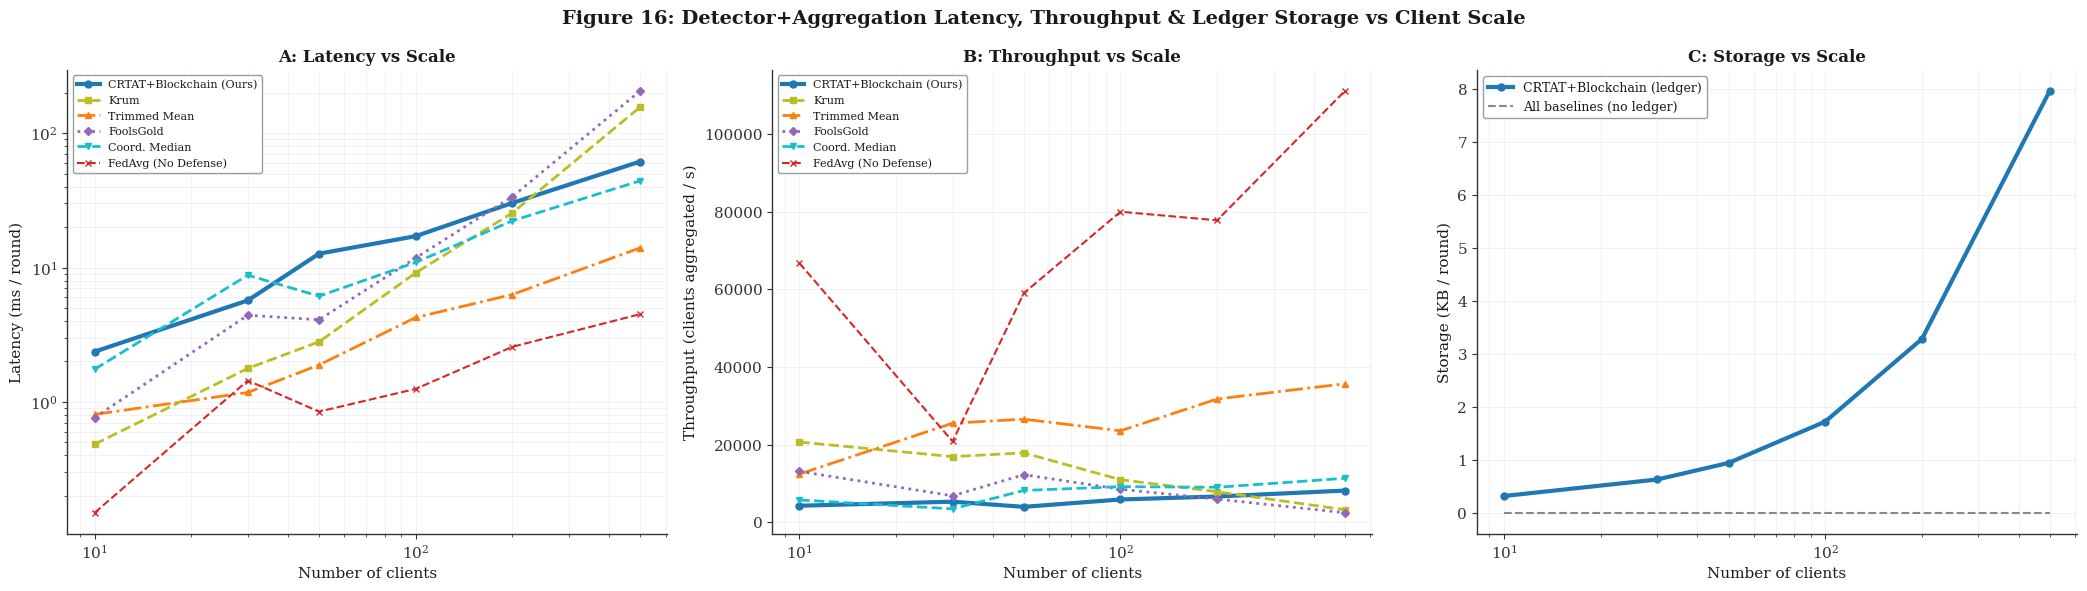

✅ Figure 16 saved.

Scale Benchmark Summary
══════════════════════════════════════════════════════════════════════════════════════════
Method                       10        30        50       100       200       500   (latency ms/round)
──────────────────────────────────────────────────────────────────────────────────────────
  CRTAT+Blockchain         2.37      5.69     12.68     17.12     30.24     61.46
  Krum                     0.48      1.78      2.80      9.13     25.53    156.42
  TrimmedMean              0.81      1.18      1.88      4.25      6.30     14.01
  FoolsGold                0.76      4.42      4.09     11.78     33.68    206.13
  CoordMedian              1.75      8.77      6.12     10.93     22.26     44.22
  FedAvg_NoDefense         0.15      1.44      0.85      1.25      2.57      4.50

CRTAT+Blockchain ledger storage at largest scale (n=500): 7.973 KB/round (119.59 KB for a 15-round run)


In [ ]:
BENCH_PARAM_DIM = 5000   # representative update size, fixed across the scale sweep

def _krum_select_bench(updates, f):
    """Gram-matrix formulation of Krum — identical selection/weights to
    krum_select(), but O(n^2) memory instead of O(n^2 * d). Used only for the
    large-n scale benchmark below."""
    stacked = np.stack(updates)
    n = len(stacked)
    f = krum_effective_f(n, f)
    k = max(1, n - f - 2)
    norms = np.sum(stacked**2, axis=1)
    d = np.maximum(norms[:, None] + norms[None, :] - 2 * stacked @ stacked.T, 0)
    krum_sc = [sum(sorted(d[i])[1:k+1]) for i in range(n)]
    n_sel = max(1, n - f - 2)
    selected = np.argsort(krum_sc)[:n_sel]
    w = np.zeros(n); w[selected] = 1.0 / n_sel
    return w, np.array(krum_sc)

def _bench_round(fn, n=2):
    times = []
    for _ in range(n):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return float(np.mean(times))

SCALE_METHODS = ['CRTAT+Blockchain', 'Krum', 'TrimmedMean', 'FoolsGold', 'CoordMedian', 'FedAvg_NoDefense']
scale_results = {m: {'latency_ms': [], 'throughput': [], 'storage_kb': []} for m in SCALE_METHODS}

print('Running Latency / Throughput / Storage sweep …')
for n_cl in SCALE_TEST_CLIENTS:
    rng_s = np.random.default_rng(0)
    updates_s = [rng_s.standard_normal(BENCH_PARAM_DIM).astype(np.float32) * 0.01
                 for _ in range(n_cl)]
    f_est = max(1, int(round(0.15 * n_cl)))   # assume ~15% malicious, matches NUM_MALICIOUS/NUM_CLIENTS

    def _round_crtat():
        crtat = CRTAT(n_clients=n_cl)
        t = blockchain_trust(updates_s)
        i = inversion_signal(updates_s)
        crtat.update(t, inv_scores=i)
        s = crtat.combined_score(t)
        w = crtat_weights(s)
        return fedavg_agg(updates_s, w)

    def _round_krum():
        w, sc = _krum_select_bench(updates_s, f_est)
        return fedavg_agg(updates_s, w)

    def _round_tm():
        return trimmed_mean_agg(updates_s)

    def _round_fg():
        w = foolsgold_weights(updates_s)
        return fedavg_agg(updates_s, w)

    def _round_med():
        return median_agg(updates_s)

    def _round_fa():
        return fedavg_agg(updates_s)

    round_fns = {
        'CRTAT+Blockchain': _round_crtat, 'Krum': _round_krum, 'TrimmedMean': _round_tm,
        'FoolsGold': _round_fg, 'CoordMedian': _round_med, 'FedAvg_NoDefense': _round_fa,
    }
    ledger_bytes = 8 + n_cl*8 + n_cl*8 + 64 + 28 + 64   # per-round blockchain block size

    for m, fn in round_fns.items():
        lat = _bench_round(fn)
        scale_results[m]['latency_ms'].append(lat * 1000)
        scale_results[m]['throughput'].append(n_cl / lat)
        scale_results[m]['storage_kb'].append(ledger_bytes / 1024 if m == 'CRTAT+Blockchain' else 0.0)

    print(f'  scale n_clients={n_cl:>4}  done')

print('✅ Scale sweep complete.')

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
fig.suptitle('Figure 16: Detector+Aggregation Latency, Throughput & Ledger Storage vs Client Scale', fontsize=14, fontweight='bold')

ax = axes[0]
for m in SCALE_METHODS:
    ax.plot(SCALE_TEST_CLIENTS, scale_results[m]['latency_ms'], **MSTYLES[m], label=MLABELS[m])
ax.set_xlabel('Number of clients'); ax.set_ylabel('Latency (ms / round)')
ax.set_title('A: Latency vs Scale', fontsize=12)
ax.set_xscale('log'); ax.set_yscale('log')
ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)

ax = axes[1]
for m in SCALE_METHODS:
    ax.plot(SCALE_TEST_CLIENTS, scale_results[m]['throughput'], **MSTYLES[m], label=MLABELS[m])
ax.set_xlabel('Number of clients'); ax.set_ylabel('Throughput (clients aggregated / s)')
ax.set_title('B: Throughput vs Scale', fontsize=12)
ax.set_xscale('log')
ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)

ax = axes[2]
ax.plot(SCALE_TEST_CLIENTS, scale_results['CRTAT+Blockchain']['storage_kb'],
        **MSTYLES['CRTAT+Blockchain'], label='CRTAT+Blockchain (ledger)')
ax.plot(SCALE_TEST_CLIENTS, [0]*len(SCALE_TEST_CLIENTS), color='#888888', lw=1.5, ls='--',
        label='All baselines (no ledger)')
ax.set_xlabel('Number of clients'); ax.set_ylabel('Storage (KB / round)')
ax.set_title('C: Storage vs Scale', fontsize=12)
ax.set_xscale('log')
ax.legend(fontsize=9); ax.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.savefig('fig16_latency_throughput_storage.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('✅ Figure 16 saved.')

print()
print('Scale Benchmark Summary')
print('═'*90)
print(f'{"Method":<20} ' + ''.join(f'{n:>10}' for n in SCALE_TEST_CLIENTS) + '   (latency ms/round)')
print('─'*90)
for m in SCALE_METHODS:
    print(f'  {m:<18} ' + ''.join(f'{v:>10.2f}' for v in scale_results[m]['latency_ms']))
print()
print(f'CRTAT+Blockchain ledger storage at largest scale (n={SCALE_TEST_CLIENTS[-1]}): '
      f'{scale_results["CRTAT+Blockchain"]["storage_kb"][-1]:.3f} KB/round '
      f'({scale_results["CRTAT+Blockchain"]["storage_kb"][-1]*FL_ROUNDS:.2f} KB for a {FL_ROUNDS}-round run)')


## v7 additions (historical note)

v7 added CIFAR-100, the reconstruction-error Non-IID split (a partitioning axis only, not a CRTAT input), the Dirichlet distribution figure, the component ablation (superseded by the v9 replay-based Table VI / Figure 15) and the scale sweep (Figure 16, detector+aggregation only). The v9 changes answering the reviewer comments are listed in the traceability table at the end of this notebook.

**Note:** the notebook downloads CIFAR-10, CIFAR-100 and MNIST at runtime, so it needs internet access (e.g. Google Colab or Kaggle). Lower `SEEDS` to one seed for a quick check.


## ✅ v9 Reviewer-Response Summary & Traceability

| Reviewer item | Where handled in this notebook |
|---|---|
| §3A Full-CRTAT ≠ proposed method across tables | Step 8b protocol; `crtat_replay` uses recorded participation masks + same `final_signal`; **assertions** that replay == main run and Table VI Full == Table IV |
| §3B wrong ablation comparison | `ablation_statement()` generates the sentence from the table |
| §3C thresholds | `OPERATING_POINTS` (OP-A principal τ=0.60, OP-B top-30%, OP-S sensitivity); every result labelled |
| §3D Table VII documentation | configuration block (seeds, partition, stopping rule, averaging) + reproduction check vs Table V |
| §3E pooled AUC | honest-only negatives everywhere; `pooled_identity_check` verifies pooled = count-weighted per-type mean |
| §3F zero P/R/F1 | `confusion_counts` / `fmt_counts` report TP/FP/TN/FN and #flagged ('undef' precision when nothing is flagged) |
| §3G inversion below chance | diagnostics cell (labels, sign/scale convention, orientation, LOO/honest-only reference, recording, where the signal is lost) — no score reversal |
| §3H runtime scopes | timing split into train / detector / aggregation / ledger-build / ledger-verify / total (Table VII, protocol-check cell, cost benchmark) |
| §4 baseline scores undefined | `BASELINE_SCORE_DEFINITIONS` printed with Table IV |
| §4 baseline-update contradiction | Step 9 text: end-to-end comparison, matched seed/schedule (not a replay) |
| §4 Krum f | `krum_effective_f` enforces n>2f+2 (f=5, n=12 → f_eff=4), clamp logged |
| §4 reconstruction error role | documented: partition axis only, not a CRTAT input |
| §4 trust recovery reproducibility | CRTAT docstring gives equations, initialisation, parameters; Table III cell lists values |
| §4 short horizon | observations per client printed (protocol-check cell) |
| §4 neutral observations | `NEUTRAL_TRUST` defined; `CRTAT(missing='skip')` participation-aware alternative reported in Table VI |
| §4 "acceleration" | renamed *trend-change* in prose/docstrings (argument name `delta` kept) |
| §4 influence bound | influence-bound experiment (update scaling × norm clipping) |
| §4 clean accuracy / ASR | attack-impact cell (clean controls, source-class accuracy, targeted misclassification) |
| §5 temporal baselines | simplified FLDetector-*inspired* baseline added (explicitly not FLDetector) |
| §5 ledger claims | `is_valid(anchor_hash=...)` + rewrite demonstration; wording changed to *tamper-evident* |

**Manuscript-only items (no code change possible):** grammar/wording table, `Table ??` and `[?]` references, duplicate references [5]/[24] and [9]/[26], Roy et al. year mismatch, CRTAT vs CR-TAT and defense/defence standardisation in the PDF, replacing "provide proof" with "illustrate", title change, abstract wording for the 47.03 ms figure.

**Not executed:** this revision was syntax-checked and smoke-tested on synthetic data only; CIFAR/MNIST downloads require internet (Colab/Kaggle). All outputs were cleared because every number changes under the unified protocol — re-run top to bottom.
